# Wheel-Slip Simulator and Trajectory Control: current-driven motor

This notebook drives the plant with **q-axis current** (`WheelSlipRobotSimulator`; ideal current control, no back-EMF). `robot_model_voltage.ipynb` is the same plant driven by **motor voltage**.

This notebook develops a step-through simulator for the project's four-wheel omni robot, a PID baseline, and a locally linear convex MPC. The reference is time-indexed position, velocity, acceleration, and heading, so the controllers plan through turns rather than aiming only at the endpoint.

## Notebook map

1. **Setup and constants:** project physical parameters, controller settings, and coordinate conventions.
2. **Reference trajectory:** route geometry, timing, velocity/acceleration references, and obstacles.
3. **Wheel contact:** call the project's `williams_model.py` wheel-frame, slip, and friction functions.
4. **Plant dynamics:** independently integrate chassis motion and four wheel speeds with coupled contact forces and torques.
5. **Controllers:** PID inverse dynamics and convex MPC prediction, objective, and constraints.
6. **Simulation and diagnostics:** inspect trajectory, actual wheel speeds, d/a slip, forces, currents, and balance residuals.

## Model boundary

- Physical simulator state is `[x_world, y_world, phi, vx_world, vy_world, omega, theta_dot_1, ..., theta_dot_4]` (the voltage plant adds the four winding currents). Wheel speeds are independent states; wheel angles are not tracked.
- The active `WheelSlipRobotSimulator` evaluates the project's actual wheel-ground d/a slip and force laws. Drive force acts on the chassis and its matching contact torque appears in that wheel's rotation equation.
- The prior effective-mass matrix remains in `RollingOnlyRobotSimulator` as a no-slip baseline only. The slip-capable plant uses the rigid-body mass matrix and separately integrates wheel inertia, avoiding a second reflection of wheel inertia into the chassis matrix.
- Wheel contact uses the smooth Williams-style force law in `williams_model.py`, with the configured friction parameters and normal load. It transitions smoothly from the configured static coefficient near zero slip toward the dynamic coefficient as slip grows; it is not an ideal stick/slip complementarity solver.
- `DT` is the controller sample time. The contact dynamics are stiff near zero slip, so the plant uses an implicit integrator. Its tolerances are numerical settings that should be checked for convergence, not hardware timing claims.
- Optional wheel-load redistribution is a repeatable surrogate that conserves total robot weight, not a ZMP, suspension, or wheel-hop model. The body-frame external wrench and obstacle models remain separate.
- Motor input is commanded q-axis current, with motor torque `tau_m = K_t I_q`. This model does not simulate motor voltage, back-EMF, winding resistance/inductance, or the FOC current loop. Under sustained wheelspin, ideal current control can therefore keep accelerating a wheel when motor torque exceeds the modeled contact torque; wheel speed has no electrical roll-off in this plant. Current, acceleration, speed, and yaw-rate limits are controller/safety limits; project friction and motor values remain provisional until measured or verified.
- The voltage-driven version of this plant (winding currents, back-EMF, driver limits) is in `robot_model_voltage.ipynb`.

## Reference documents

`COCO_Project_Report1_anonymized.pdf` is a drone-racing RTI/SQP NMPC example, not this robot's physics model. Its transferable ideas are stage-wise trajectory tracking, explicit constraints, warm starts, and solver-latency awareness. This notebook uses a locally linearized prediction of its nonlinear wheel-slip plant; the QP prediction is an approximation, while the plant evaluates the nonlinear contact law.

## 1. Import Required Libraries

Import the project’s robot constants and the Python libraries used for simulation and plotting. NumPy and Matplotlib are required; CVXPY is used in the later optional QP section.

In [ ]:
import os

# Cap native numerical-library threading. Run this setup cell before importing NumPy.
# The simulator's time-stepping loop is sequential; this limits BLAS/OpenMP threads
# but does not parallelize a single trajectory.
N_CORES = 2
for _thread_env in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_thread_env] = str(N_CORES)

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import importlib
import robot_constants as _robot_constants

# Refresh cached project constants when this setup cell is rerun.
_robot_constants = importlib.reload(_robot_constants)
#import williams_model as _williams_model
#_williams_model = importlib.reload(_williams_model)
import robot_constants as rc

# --------------------------- Simulation configuration ---------------------------
# Use PID by default while validating the nonlinear plant; set to "MPC" to run the QP.
CONTROLLER_MODE = "PID"
# True: run only the plant checks (sections 4.1 onward) and skip the PID/MPC simulation.
# False: skip the checks, which take most of the run time, and run the controller simulation.
RUN_PLANT_CHECKS = False
MPC_HORIZON = 8           # Current feasibility-tested LTV prediction horizon.
MPC_CONSTRAINT_TOL = 1e-4  # Match OSQP absolute tolerance when reporting feasibility.
DT = 0.01  # controller sample time and plant hold interval [s]; maximum used is 0.01
# Plant ODE solver. Radau is implicit, so it steps through the stiff grip-restoring
# (0.1 ms) and winding (0.55 ms) time constants; explicit RK45 would need ~0.25 ms
# substeps regardless of DT.
PLANT_INTEGRATOR = "Radau"
# Plant solver tolerances. The slip error they allow must stay far below the grip/slide
# transition band (DRIVE_BREAKAWAY_BAND, 5 mm/s). Looser is faster.
PLANT_RTOL = 1e-5
PLANT_ATOL = 1e-7
# True: each plant step starts from the previous step's Jacobian and step size; a fresh Jacobian
# is computed when a wheel changes grip/slide mode or the solver converges slowly. This changes
# how quickly each step is solved, not the tolerances it meets. False: a fresh one every step.
PLANT_REUSE_JACOBIAN = True

# True: include the ESTIMATED wheel rolling resistance (WHEEL_ROLLING_RESISTANCE_ESTIMATE
# in robot_constants.py, literature-based, not measured). False: C_rr = 0.
INCLUDE_ESTIMATED_ROLLING_RESISTANCE = True
rc.WHEEL_ROLLING_RESISTANCE_COEFF = (
    rc.WHEEL_ROLLING_RESISTANCE_ESTIMATE if INCLUDE_ESTIMATED_ROLLING_RESISTANCE else 0.0
)
MAX_ACCELERATION = 5.5  # m/s^2; below the modeled current/traction acceleration capability
MAX_VELOCITY = 4.5      # m/s; fast soccer-robot transit target, still actuator-limited
MAX_YAW_RATE = 3.0      # rad/s; provisional until measured
N_WHEELS = len(rc.WHEEL_ALPHA_DEG)

# Disturbances (ESTIMATED surrogates; parameters in robot_constants.py). Set both False for
# the ideal plant. The open-loop verification suite (section 4.1) always uses the ideal
# plant, so its straight-line checks stay meaningful.
#   ENABLE_FRICTION_OFFSET: each wheel's friction coefficients are scaled by f_i = 1 + b_i,
#     a fixed per-wheel offset for the run (wheel-to-wheel and field variation); makes
#     open-loop motion drift.
#   ENABLE_LOAD_VIBRATION: each wheel's normal load is scaled by g_i = 1 + a_i n_i, then the
#     four are rescaled to keep their sum: smooth random load variation whose size grows with
#     the wheel out-of-roundness and the robot's total speed, amplified by the wheel's
#     (filtered) acceleration.
ENABLE_FRICTION_OFFSET = True
ENABLE_LOAD_VIBRATION = True
DISTURBANCE_SEED = 7  # same seed -> same disturbance realisation

# Centre of gravity, mm from the robot centre P (body axes: x right, y forward, z up).
# Default: the real robot (CAD), CoG at (0.597, 10.206, 61.146) mm, 10.2 mm toward the front.
# Simplification (Dana): (0.0, 0.0, rc.COG_Z_MM) centres it in x and y. The inertia about
# the CoG (CAD) is unchanged; the yaw inertia about P and the planar mass matrix follow
# from the offset.
COG_POSITION_MM = (rc.COG_X_MM, rc.COG_Y_MM, rc.COG_Z_MM)
rc.set_center_of_gravity(*COG_POSITION_MM)

# Wheel normal loads N_i. They set each wheel's grip limit mu_d,s N_i, its friction
# forces, and its rolling resistance (section 4.6 shows the calculation).
#   "equal":        N_i = m g / 4 at all times (the earlier model).
#   "static":       loads at rest from the CoG position: force and moment balance about the CoG.
#   "quasi_static": "static" plus load transfer: the horizontal contact force acts at the
#                   floor, COG_HEIGHT below the CoG, and shifts load between the wheels.
#                   The loads follow the contact force at the end of the previous step
#                   (one DT lag) and are held over the step.
# Even with a centred CoG the loads are unequal: the front contacts are 39.7 mm ahead of P
# and the rear ones 56.2 mm behind it (wheels at 30 and 45 deg). Section 4.6 has the numbers.
WHEEL_LOAD_MODEL = "quasi_static"

# True: the PID allocates wheel currents with a NOMINAL model, as a designer would: the
# plant's mass matrix without its CoG coupling terms (translation and yaw decoupled), the
# geometric base loads (computed once from the wheel positions and the CoG), and no load
# transfer or friction disturbance. The CoG crosstalk then reaches the PID as a disturbance
# it has to reject. False gives it the plant's true model, which cancels most of the coupling.
PID_USES_NOMINAL_MODEL = True

# The project friction law is bounded by its configured static coefficient.
# Retain the bound as a safety check on the computed contact force.
ALLOW_DRIVE_TRACTION_OVERLOAD = False

# Sliding drive (d-axis) friction law. One word to change; the others stay available.
#   "switch" (default): the switch model of Leine et al. (1998). A wheel sticks while the force
#     it needs to grip is within mu_d,s N. A wheel that breaks loose while |v_d| is below
#     DRIVE_BREAKAWAY_BAND keeps mu_d(|v_d|) N in the direction of the force it needed (the
#     transition band), so its force never passes through zero at the switch; once the slip has
#     left the band it slides with the "continuous" law, which has the same value there.
#   "continuous": every sliding wheel gets F_d = -N mu_d(|v|) tanh(v / DRIVE_SLIP_REGULARIZATION).
#     It reaches the static limit within a few mm/s of slip, but is zero at the breakaway instant.
#   "atan": the previous law, -N mu_d(|v|) (2/pi) atan(K_SMOOTH_D v). Zero at zero slip, and
#     about 5 cm/s of slip to recover, so a wheel lost its drive force when it broke away.
#   "lugre": LuGre dynamic friction (Canudas de Wit et al. 1995), one bristle state per wheel
#     (LUGRE_* below). No grip/slide decision and no blend; steady sliding gives the same
#     mu_d(|v|) N. Section 4.15 compares it with "switch".
# Sections 4.10-4.12 validate the transitions.
DRIVE_SLIDING_LAW = "switch"

# Grip/slide blend time tau [s]. When a wheel changes between rolling and sliding, its drive force
# moves from the rolling force (capped at its grip limit) to the sliding force, or back, with this
# time constant, instead of switching in one step: F_i = lambda_i F_roll + (1 - lambda_i) F_slide,
# d(lambda_i)/dt = (target_i - lambda_i) / tau. It stands for contact dynamics the model does not
# resolve (roller and carpet deformation). 0 switches instantly (the sliding law above alone).
DRIVE_MODE_BLEND_TIME = 0.033  # about 5 cm of travel at 1.5 m/s

# LuGre drive friction (DRIVE_SLIDING_LAW = "lugre"). None of these is measured; the reasoning is in
# friction_model_plan.md, section 4.2. For each wheel, with slip v and g(v) = mu_d(|v|) N:
#   dz/dt = v - sigma0 |v| z / g(v),   F = -(sigma0 z + sigma1 dz/dt + sigma2 v)
# LUGRE_PRESLIDING_DEFLECTION: bristle deflection z at the static limit mu_s N [m]; sets the
#   stiffness sigma0 = mu_s N / deflection (about 7200 N/m for a rear wheel at 0.5 mm).
# LUGRE_DAMPING_RATIO: sigma1 as a fraction of critical damping of sigma0 against the rim inertia
#   J_w / R_w^2 (18.5 g).
# LUGRE_VISCOUS_COEFF: sigma2 [N s/m]. 0 keeps steady sliding equal to mu_d(|v|) N.
LUGRE_PRESLIDING_DEFLECTION = 0.5e-3
LUGRE_DAMPING_RATIO = 1.0
LUGRE_VISCOUS_COEFF = 0.0

# Drive-axis grip (rolling) vs sliding is decided by FORCE only: a wheel grips when
# the contact force needed to keep it gripping is within MU_D_STAT * N_i; otherwise
# it slides with the Williams kinetic law. No slip-velocity threshold is used.
# While gripping, the contact also pulls any existing drive slip back to zero with
# force -DRIVE_GRIP_SLIP_STIFFNESS * v_d. That term is part of the required force,
# so it counts against the static limit. Without it, gripping only holds
# d(v_d)/dt = 0, and a wheel that had slid would keep its slip forever.
# ILLUSTRATIVE, unmeasured: same value as Dana's SLIP_STIFFNESS_N_PER_M_S. A sliding
# wheel re-grips once k * |v_d| (plus inertial demand) falls below MU_D_STAT * N,
# i.e. at roughly MU_D_STAT * N / k ~ 33 mm/s for the nominal load.
DRIVE_GRIP_SLIP_STIFFNESS = 180.0  # N per (m/s)
CURRENT_FEASIBILITY_BISECTION_STEPS = 14  # conservative scale resolution: 1 / 2^14

HEADING_MODE = "sideways_body"  # front_body, sideways_body, front_world, sideways_world, or target
HEADING_TARGET_WORLD = np.array([5.0, 0.0])

## 2. Reference Targets: Position, Velocity, and Heading at Each Time

This notebook does not ask the MPC to invent a route. `ROUTE_WAYPOINTS` is a manually selected centerline that already passes on chosen sides of the static obstacles. The code parameterizes that route by time and supplies a desired position and velocity at every MPC stage. These references are fixed data; the QP chooses currents and predicted robot states to track them.

The route's forward/backward speed envelope accelerates from rest, stays under configured speed and acceleration limits, and brakes to rest at the last waypoint. That makes the endpoint a receiving-pass style target: goal position with zero translational velocity. The path itself is not the convexity claim.

Convexity comes from the optimization problem: at each horizon stage the obstacle side is fixed from the nominal reference, so obstacle avoidance is a linear half-space. State updates are affine and the tracking/effort costs are quadratic. The QP cannot decide to pass either side of an obstacle in the same solve; changing sides is an outer route-choice decision. The drone report uses a fixed spline and nonlinear SQP/RTI tracking, and says trajectory planning is outside its scope.

Heading is another time-indexed target. Use the route tangent during transit, a fixed target point for pass/shot behavior, or provide a custom callback for a scheduled heading. For a receiving pass, set the endpoint velocity to zero and choose the heading toward the passer or intended shot target.


**Drive-slip diagnostic:** The active slip plant stores actual wheel speeds and simulates d-axis wheelspin with the project friction law. `ALLOW_DRIVE_TRACTION_OVERLOAD` bypasses the controller feasibility check against the configured static-friction capacity; the contact force remains governed by `williams_model.py` and its static-to-dynamic transition.


In [2]:
from scipy.interpolate import CubicSpline

# Define the smooth, timed robot route first. Static obstacles are placed beside
# this path below, with enough clearance for the PID plant trajectory.
FIELD_LENGTH = 4.5  # x direction [m]
FIELD_WIDTH = 6.0   # y direction [m]
# Two joined elliptical loops form a broad figure-eight that fits inside the field.
# The lower loop runs counterclockwise; the upper loop runs clockwise. They meet
# at the center with a continuous tangent, so the robot swerves through the crossing.
FIGURE_EIGHT_RADIUS_X = 1.50
FIGURE_EIGHT_RADIUS_Y = 1.25
LOOP_PHASE = np.linspace(0.0, 2.0 * np.pi, 121)
LOWER_PHASE = 0.5 * np.pi + LOOP_PHASE
UPPER_PHASE = 1.5 * np.pi - LOOP_PHASE

LOWER_LOOP = np.column_stack((
    FIGURE_EIGHT_RADIUS_X * np.cos(LOWER_PHASE),
    -FIGURE_EIGHT_RADIUS_Y + FIGURE_EIGHT_RADIUS_Y * np.sin(LOWER_PHASE),
))
UPPER_LOOP = np.column_stack((
    FIGURE_EIGHT_RADIUS_X * np.cos(UPPER_PHASE),
    FIGURE_EIGHT_RADIUS_Y + FIGURE_EIGHT_RADIUS_Y * np.sin(UPPER_PHASE),
))
ROUTE_WAYPOINTS = np.vstack((LOWER_LOOP[:-1], UPPER_LOOP[:-1], LOWER_LOOP[0]))
ROUTE_WAYPOINTS[-1] = ROUTE_WAYPOINTS[0]

# The path is defined first. These small obstacles sit in opposite field corners,
# beside the figure-eight rather than inside the path. Clearance is checked each step.
STATIC_OBSTACLES = [
    np.array([[1.85, 2.55], [2.15, 2.55], [2.15, 2.85], [1.85, 2.85]]),
    np.array([[-2.15, -2.85], [-1.85, -2.85], [-1.85, -2.55], [-2.15, -2.55]]),
]
# Each dynamic obstacle stores polygon vertices in its local frame and a function
# returning its predicted world-frame translation at time_s. Example:
# {"vertices": local_rectangle, "position_fn": lambda time_s: np.array([x0+vx*time_s, y0+vy*time_s])}
DYNAMIC_OBSTACLES = []
ROBOT_CLEARANCE = 0.35  # m; footprint + safety margin + prediction/discretization margin
# Shape timed targets to the current-limited PID plant so they remain trackable.
# Combined reference acceleration is sqrt(2.0^2 + 1.2^2) ~= 2.33 m/s^2.
REFERENCE_MAX_SPEED = 2.2  # m/s; the plant reaches about 1.7 m/s on this loop
REFERENCE_LATERAL_ACCELERATION = 2.0  # m/s^2; below the observed 2.5 m/s^2 slip onset
REFERENCE_TANGENTIAL_ACCELERATION = 1.2  # m/s^2; creates visible speed-up/braking phases


def convex_polygon_halfspaces(vertices):
    """Return unit outward edge normals n and bounds b for a CCW convex polygon."""
    vertices = np.asarray(vertices, dtype=float)
    edges = np.roll(vertices, -1, axis=0) - vertices
    normals = np.column_stack((edges[:, 1], -edges[:, 0]))
    normals /= np.linalg.norm(normals, axis=1, keepdims=True)
    return normals, np.sum(normals * vertices, axis=1)


def obstacle_safe_halfspace(route_point, vertices, clearance=ROBOT_CLEARANCE):
    """Choose the locally safe side of a convex obstacle as n dot p >= b+clearance.

    The side is selected from the route point and held fixed in the local QP.
    Obstacle-side selection itself is discrete/nonconvex; the resulting halfspace
    is affine and convex for that selected route corridor.
    """
    route_point = np.asarray(route_point, dtype=float)
    vertices = np.asarray(vertices, dtype=float)
    normals, _ = convex_polygon_halfspaces(vertices)
    closest_point = None
    edge_normal = None
    min_distance = np.inf
    for edge_index, start in enumerate(vertices):
        end = vertices[(edge_index + 1) % len(vertices)]
        edge = end - start
        fraction = np.clip(np.dot(route_point - start, edge) / np.dot(edge, edge), 0.0, 1.0)
        candidate = start + fraction * edge
        distance = np.linalg.norm(route_point - candidate)
        if distance < min_distance:
            min_distance = distance
            closest_point = candidate
            edge_normal = normals[edge_index]
    normal = edge_normal if min_distance < 1e-10 else (route_point - closest_point) / min_distance
    return normal, float(normal @ closest_point + clearance)


def point_polygon_distance(point, vertices):
    """Return Euclidean clearance from a point to a convex polygon boundary/interior."""
    point = np.asarray(point, dtype=float)
    vertices = np.asarray(vertices, dtype=float)
    normals, bounds = convex_polygon_halfspaces(vertices)
    if np.all(normals @ point <= bounds):
        return 0.0
    distances = []
    for edge_index, start in enumerate(vertices):
        edge = vertices[(edge_index + 1) % len(vertices)] - start
        fraction = np.clip(np.dot(point - start, edge) / np.dot(edge, edge), 0.0, 1.0)
        distances.append(np.linalg.norm(point - (start + fraction * edge)))
    return float(min(distances))


def obstacle_polygons_at(time_s):
    """Return named world-frame obstacle polygons and required clearances at time_s."""
    obstacles = [
        (f"static_{index}", np.asarray(vertices, dtype=float), ROBOT_CLEARANCE)
        for index, vertices in enumerate(STATIC_OBSTACLES)
    ]
    for index, obstacle in enumerate(DYNAMIC_OBSTACLES):
        translation = np.asarray(obstacle["position_fn"](time_s), dtype=float)
        if translation.shape != (2,):
            raise ValueError("dynamic obstacle position_fn must return [x, y]")
        vertices = np.asarray(obstacle["vertices"], dtype=float) + translation
        obstacles.append((
            obstacle.get("name", f"dynamic_{index}"), vertices,
            float(obstacle.get("clearance", ROBOT_CLEARANCE)),
        ))
    return obstacles


def obstacle_clearance_report(position, time_s):
    """Measure center-to-polygon clearance after a plant step; negative margin is collision."""
    report = []
    for name, vertices, required_clearance in obstacle_polygons_at(time_s):
        distance = point_polygon_distance(position, vertices)
        report.append({
            "name": name,
            "distance_m": distance,
            "required_clearance_m": required_clearance,
            "margin_m": distance - required_clearance,
        })
    return report


def pid_obstacle_repulsion(position, time_s, gain=4.0, influence_distance=1.0):
    """Add a smooth, local repulsive acceleration for the PID comparison baseline."""
    acceleration = np.zeros(2)
    for _, vertices, required_clearance in obstacle_polygons_at(time_s):
        distance = point_polygon_distance(position, vertices)
        gap = distance - required_clearance
        if gap < influence_distance:
            normal, _ = obstacle_safe_halfspace(position, vertices, clearance=0.0)
            acceleration += gain * (influence_distance - max(gap, 0.0)) * normal
    return acceleration


# Fit the centerline by chord length, then reparameterize samples by measured arc length.
_route_chords = np.linalg.norm(np.diff(ROUTE_WAYPOINTS, axis=0), axis=1)
_route_knots = np.r_[0.0, np.cumsum(_route_chords)]

_route_x = CubicSpline(_route_knots, ROUTE_WAYPOINTS[:, 0], bc_type="periodic")
_route_y = CubicSpline(_route_knots, ROUTE_WAYPOINTS[:, 1], bc_type="periodic")

_route_parameter = np.linspace(0.0, _route_knots[-1], 5001)
_route_points = np.column_stack((_route_x(_route_parameter), _route_y(_route_parameter)))
PATH_ARC = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(_route_points, axis=0), axis=1))]
_route_dx = _route_x(_route_parameter, 1)
_route_dy = _route_y(_route_parameter, 1)
_route_ddx = _route_x(_route_parameter, 2)
_route_ddy = _route_y(_route_parameter, 2)
_route_tangent_norm = np.maximum(np.hypot(_route_dx, _route_dy), 1e-9)
PATH_TANGENT = np.column_stack((_route_dx / _route_tangent_norm, _route_dy / _route_tangent_norm))
PATH_CURVATURE = (_route_dx * _route_ddy - _route_dy * _route_ddx) / np.maximum(_route_tangent_norm**3, 1e-9)

# Build a timed centerline speed profile. Curvature and yaw rate limit corner
# speed; forward/backward passes leave room to accelerate and brake at the endpoints.
LATERAL_ACCEL_LIMIT = REFERENCE_LATERAL_ACCELERATION
TANGENTIAL_ACCEL_LIMIT = REFERENCE_TANGENTIAL_ACCELERATION
PATH_SPEED_CAP = np.minimum.reduce((
    np.full_like(PATH_CURVATURE, REFERENCE_MAX_SPEED),
    np.sqrt(LATERAL_ACCEL_LIMIT / np.maximum(np.abs(PATH_CURVATURE), 1e-6)),
    MAX_YAW_RATE / np.maximum(np.abs(PATH_CURVATURE), 1e-6),
))
PATH_SPEED = PATH_SPEED_CAP.copy()
PATH_SPEED[0] = 0.0
PATH_SPEED[-1] = 0.0
PATH_DS = np.diff(PATH_ARC)
for _ in range(2):
    for index in range(1, len(PATH_SPEED)):
        PATH_SPEED[index] = min(
            PATH_SPEED[index],
            np.sqrt(max(0.0, PATH_SPEED[index - 1]**2 + 2.0 * TANGENTIAL_ACCEL_LIMIT * PATH_DS[index - 1])),
        )
    for index in range(len(PATH_SPEED) - 2, -1, -1):
        PATH_SPEED[index] = min(
            PATH_SPEED[index],
            np.sqrt(max(0.0, PATH_SPEED[index + 1]**2 + 2.0 * TANGENTIAL_ACCEL_LIMIT * PATH_DS[index])),
        )
# Approximate each interval travel time from its arc length and endpoint speeds.
# PATH_TIME maps route distance onto clock time for the controller references.
PATH_DT = 2.0 * PATH_DS / np.maximum(PATH_SPEED[:-1] + PATH_SPEED[1:], 1e-6)
PATH_TIME = np.r_[0.0, np.cumsum(PATH_DT)]
PATH_END_TIME = float(PATH_TIME[-1])
PATH_TANGENTIAL_ACCEL = np.gradient(PATH_SPEED**2 / 2.0, PATH_ARC)
PATH_NORMAL = np.column_stack((-PATH_TANGENT[:, 1], PATH_TANGENT[:, 0]))


def trajectory_reference(time_s):
    """Return desired world position, velocity, and acceleration at time_s.

    These are fixed references, not optimization variables. The MPC tracks
    them; after PATH_END_TIME the desired robot remains at the goal and stopped.
    """
    if time_s <= 0.0:
        arc_position, speed, tangential_acceleration = PATH_ARC[0], PATH_SPEED[0], PATH_TANGENTIAL_ACCEL[0]
    elif time_s >= PATH_END_TIME:
        # Receiving-pass target: stay at the goal with zero planar velocity.
        return ROUTE_WAYPOINTS[-1].copy(), np.zeros(2), np.zeros(2)
    else:
        arc_position = np.interp(time_s, PATH_TIME, PATH_ARC)
        speed = np.interp(arc_position, PATH_ARC, PATH_SPEED)
        tangential_acceleration = np.interp(arc_position, PATH_ARC, PATH_TANGENTIAL_ACCEL)

    position = np.array([
        np.interp(arc_position, PATH_ARC, _route_points[:, 0]),
        np.interp(arc_position, PATH_ARC, _route_points[:, 1]),
    ])
    tangent = np.array([
        np.interp(arc_position, PATH_ARC, PATH_TANGENT[:, 0]),
        np.interp(arc_position, PATH_ARC, PATH_TANGENT[:, 1]),
    ])
    tangent /= max(np.linalg.norm(tangent), 1e-9)
    normal = np.array([-tangent[1], tangent[0]])
    curvature = np.interp(arc_position, PATH_ARC, PATH_CURVATURE)
    velocity = speed * tangent
    acceleration = tangential_acceleration * tangent + speed**2 * curvature * normal
    return position, velocity, acceleration


def body_to_world(vector_body, phi):
    """Rotate a body-frame vector into the world frame."""
    cosine, sine = np.cos(phi), np.sin(phi)
    return np.array([[cosine, -sine], [sine, cosine]]) @ np.asarray(vector_body, dtype=float)


def world_to_body(vector_world, phi):
    """Rotate a world-frame vector into the body frame, matching simulation.py."""
    cosine, sine = np.cos(phi), np.sin(phi)
    return np.array([[cosine, sine], [-sine, cosine]]) @ np.asarray(vector_world, dtype=float)


def wrap_angle(angle):
    return (angle + np.pi) % (2.0 * np.pi) - np.pi


def tangent_heading_reference(time_s, position, velocity):
    """Return the selected heading while tracking the original figure-eight."""
    clamped_time = np.clip(time_s, 0.0, PATH_END_TIME)
    arc_position = np.interp(clamped_time, PATH_TIME, PATH_ARC)
    tangent = np.array([
        np.interp(arc_position, PATH_ARC, PATH_TANGENT[:, 0]),
        np.interp(arc_position, PATH_ARC, PATH_TANGENT[:, 1]),
    ])
    path_heading = float(np.arctan2(tangent[1], tangent[0]))

    if HEADING_MODE == "front_body":
        return path_heading
    if HEADING_MODE == "sideways_body":
        return float(path_heading + np.pi / 2)
    if HEADING_MODE == "front_world":
        return 0.0
    if HEADING_MODE == "sideways_world":
        return float(np.pi / 2)

    raise ValueError(
        "HEADING_MODE must be 'front_body', 'sideways_body', "
        "'front_world', 'sideways_world', or 'target'"
    )


def target_heading_reference(target_world):
    """Create a heading callback that faces a fixed pass/shot target.

    At every time, the desired angle points from the robot position to target_world.
    """
    target_world = np.asarray(target_world, dtype=float)

    def heading(time_s, position, velocity):
        direction = target_world - position
        return float(np.arctan2(direction[1], direction[0]))

    return heading


def configured_heading_reference():
    """Build the selected heading reference used by PID and MPC."""
    if HEADING_MODE == "target":
        return target_heading_reference(HEADING_TARGET_WORLD)
    if HEADING_MODE in ("front_body", "sideways_body", "front_world", "sideways_world"):
        return tangent_heading_reference
    raise ValueError(
        "HEADING_MODE must be 'front_body', 'sideways_body', "
        "'front_world', 'sideways_world', or 'target'"
    )

## 3. Wheel geometry and project-defined slip/friction

For each wheel, `drive[:, i]` is the powered drive direction, `axle[:, i]` is the passive-roller axis, and \(\mathbf r_i\) is the vector from the robot centre to the wheel centre. These directions are defined in the robot body frame.

The wheel-centre velocity is rigid-body velocity at an offset point:

$$
\mathbf v_i = \mathbf v_b + \boldsymbol\omega \times \mathbf r_i, \qquad
v_{a,i}=\mathbf a_i^T\mathbf v_i.
$$

`wheel_contact_outputs()` delegates d/a slip and force calculations to `williams_model.all_wheel_forces()`. The wheel speeds are actual states, so d-axis slip is not constrained to zero. The notebook scales the project's force magnitudes by sampled normal-load ratios when the optional load-redistribution surrogate is enabled.

**Wheel positions vs directions.** `WHEEL_POSITION_DEG` sets where each contact point sits on the circle ($\mathbf r_i$, `wheel_positions_body()`); `WHEEL_ALPHA_DEG` sets the axle direction $\mathbf a_i$, and the drive direction $\mathbf d_i$ is the axle turned +90°. For tangential wheels the two arrays are equal, $\mathbf r_i \parallel \mathbf a_i$, the drive yaw lever $\mathbf r_i\times\mathbf d_i = L$ and the roller lever $\mathbf r_i\times\mathbf a_i = 0$. Otherwise both levers come from the cross products, so every matrix ($H$, $M_{\mathrm{eff}}$, the roller wrench, the wheel loads, the kinematics) uses the actual geometry.

**Sliding drive friction.** A sliding wheel gets $F_d = -N\,\mu_d(|v_d|)\tanh(v_d/v_s)$ (`DRIVE_SLIDING_LAW = "switch"` or `"continuous"`), with $\mu_d(|v|) = \mu_{d,k} + (\mu_{d,s}-\mu_{d,k})e^{-\alpha|v|}$ and $v_s$ = `DRIVE_SLIP_REGULARIZATION` (1 mm/s). Within a few mm/s of slip it reaches the static limit $\mu_{d,s}N$, the force the wheel had when it broke away, then decays to $\mu_{d,k}N$. With `"switch"` (the default; the switch model of Leine et al. 1998), a wheel that breaks loose while its slip is still inside the transition band ($|v_d|$ < `DRIVE_BREAKAWAY_BAND`, 5 mm/s) keeps $\mu_d(|v_d|)N$ in the direction of the force it needed, so its force never passes through zero at the switch; at the band edge the sliding law has the same value. Section 4.10 tests the transitions. The previous law, `"atan"`, is zero at zero slip, so a wheel lost its drive force at the moment it broke away.

In [ ]:
def cross_2d_z(omega, r):
    """omega x r for omega = omega*z_hat, r a 2D vector.

    From the determinant expansion:

        | i      j     k |
        | 0      0   omega|
        | r_x  r_y     0 |

    = (-omega*r_y, omega*r_x)
    """
    omega_vec = np.array([0.0, 0.0, omega])
    r_vec = np.array([r[0], r[1], 0.0])

    return np.cross(omega_vec, r_vec)[:2]

# Wheel frame calculation based on the angle of the wheel from the first
# quadrant +x/+y in a counterclockwise direction.
#
# d_hat: wheel drive direction
# a_hat: wheel axle / passive roller direction
# The geometry depends only on the wheel layout in robot_constants, so it is computed once per
# layout and reused: the plant evaluates it tens of thousands of times per simulated second.
# The cache key is the layout itself, so a test that changes rc.WHEEL_ALPHA_DEG or
# rc.WHEEL_POSITION_DEG gets the new geometry. The arrays are read-only because they are shared.
_wheel_geometry_cache = {}


def _wheel_geometry():
    """(d_hat, a_hat, positions) for the current rc wheel layout."""
    key = (tuple(rc.WHEEL_ALPHA_DEG), tuple(rc.WHEEL_POSITION_DEG), float(rc.WHEEL_ROBOT_DIST))
    geometry = _wheel_geometry_cache.get(key)
    if geometry is None:
        alpha = np.radians(np.asarray(rc.WHEEL_ALPHA_DEG, dtype=float))
        delta = alpha + np.pi / 2
        beta = np.radians(np.asarray(rc.WHEEL_POSITION_DEG, dtype=float))
        geometry = (
            np.vstack((np.cos(delta), np.sin(delta))),
            np.vstack((np.cos(alpha), np.sin(alpha))),
            rc.WHEEL_ROBOT_DIST * np.vstack((np.cos(beta), np.sin(beta))),
        )
        for array in geometry:
            array.flags.writeable = False
        _wheel_geometry_cache[key] = geometry
    return geometry

def wheel_directions_body():
    """Return drive and axle unit vectors for all wheels in body coordinates."""
    d_hat, a_hat, _ = _wheel_geometry()
    return d_hat, a_hat

def wheel_positions_body():
    """Contact-point positions r_i from the robot centre P [m], body axes, shape (2, 4).

    Each wheel sits at WHEEL_POSITION_DEG on the circle of radius WHEEL_ROBOT_DIST. Its
    direction comes separately from WHEEL_ALPHA_DEG (wheel_directions_body). With equal
    arrays the wheels are tangential: r_i is parallel to a_i and every yaw lever is L.
    """
    return _wheel_geometry()[2]

def wheel_center_velocity_body(velocity_body, omega):
    """Return each wheel center's velocity in body coordinates [m/s]."""
    radius = wheel_positions_body()
    # omega x r_i for omega along z: (-omega r_y, omega r_x), as in cross_2d_z.
    return np.asarray(velocity_body, dtype=float)[:, None] + omega * np.array([-radius[1], radius[0]])

def wheel_slip_velocities(velocity_body, omega, theta_dot_actual):
    """Return drive-axis and axle-axis slip velocities for all wheels [m/s]."""
    d_hat, a_hat = wheel_directions_body()

    v_center = wheel_center_velocity_body(velocity_body, omega)
    v_contact_d = v_center + theta_dot_actual * rc.WHEEL_RADIUS * d_hat

    v_slip_d = np.sum(d_hat * v_contact_d, axis=0)
    v_slip_a = np.sum(a_hat * v_center, axis=0)

    return v_slip_d, v_slip_a

def mu_d(v_slip_d):
    """mu_d(v_slip_d) = mu_d_max * (2/pi) * atan(k * v_slip_d)."""
    return  (rc.MU_D_DYN + (rc.MU_D_STAT - rc.MU_D_DYN)*np.exp(-rc.ALPHA_D * np.abs(v_slip_d)))


def drive_friction_force(v_slip_d, loads):
    """Sliding drive-axis (d) friction force on each wheel [N], opposing the slip v_slip_d.

    "continuous" and "switch": -N mu_d(|v|) tanh(v / v_s), v_s = DRIVE_SLIP_REGULARIZATION. Within a few v_s it
    reaches mu_d,s N (the static limit at which the wheel broke away) and then decays to mu_d,k N.
    "atan": -N mu_d(|v|) (2/pi) atan(K_SMOOTH_D v), zero at zero slip (previous law).
    "lugre": the "continuous" curve, for diagnostics only; the LuGre force comes from the bristle
    state in the contact solve.
    Both are smooth, odd functions of the slip.
    """
    v_slip_d = np.asarray(v_slip_d, dtype=float)
    if DRIVE_SLIDING_LAW in ("continuous", "switch", "lugre"):
        shape = np.tanh(v_slip_d / rc.DRIVE_SLIP_REGULARIZATION)
    elif DRIVE_SLIDING_LAW == "atan":
        shape = (2.0 / np.pi) * np.arctan(rc.K_SMOOTH_D * v_slip_d)
    else:
        raise ValueError("DRIVE_SLIDING_LAW must be 'switch', 'continuous', 'atan', or 'lugre'")
    return -np.asarray(loads, dtype=float) * mu_d(v_slip_d) * shape


def mu_a(v_slip_a):
    """mu_a(v_slip_a) = mu_a_max * (2/pi) * atan(k * v_slip_a)."""
    return  (rc.MU_A_DYN + (rc.MU_A_STAT - rc.MU_A_DYN)*np.exp(-rc.ALPHA_A * np.abs(v_slip_a)))


def wheel_contact_outputs(velocity_body, omega, theta_dot_actual, normal_loads=None):
    """Calculate wheel contact forces and d/a slip velocities for all wheels."""
    v_slip_d, v_slip_a = wheel_slip_velocities(velocity_body, omega, theta_dot_actual)

    # loads are either equally loaded, or unequal loads from disturbance functions representing wheel lift from bouncing.
    loads = np.full(N_WHEELS, rc.F_N, dtype=float) if normal_loads is None else np.asarray(normal_loads, dtype=float)

    if loads.shape != (N_WHEELS,) or np.any(loads < 0.0):
        raise ValueError("normal_loads must contain four nonnegative wheel loads")

    F_d = drive_friction_force(v_slip_d, loads)
    F_a = -loads * mu_a(v_slip_a) * (2.0 / np.pi) * np.arctan(rc.K_SMOOTH_A * v_slip_a)

    d_hat, a_hat = wheel_directions_body()
    F = d_hat * F_d + a_hat * F_a

    return F, F_d, F_a, v_slip_d, v_slip_a

def wheel_loss_torque(theta_dot, normal_loads=None):
    """Torque on each wheel from rolling resistance and bearing drag [N m].

    tau_loss = -C_rr * N_i * R_w * tanh(theta_dot / w_eps) - b_w * theta_dot

    It opposes wheel rotation. Through the rolling constraint it is the only
    term that can dissipate pure-yaw motion: for pure spin the contact velocity
    is along d_hat (r_i is parallel to a_hat), so the a-axis roller friction is
    zero. Both coefficients are UNMEASURED and default to 0 in robot_constants.py.
    tanh(.) only regularizes sign(theta_dot); w_eps is a numerical setting.
    """
    if rc.WHEEL_ROLLING_RESISTANCE_COEFF == 0.0 and rc.WHEEL_BEARING_VISCOUS_DRAG == 0.0:
        return np.zeros(N_WHEELS)  # both losses off (the default): nothing to evaluate
    theta_dot = np.asarray(theta_dot, dtype=float)
    loads = np.full(N_WHEELS, rc.F_N, dtype=float) if normal_loads is None else np.asarray(normal_loads, dtype=float)
    rolling_resistance = (
        -rc.WHEEL_ROLLING_RESISTANCE_COEFF * loads * rc.WHEEL_RADIUS
        * np.tanh(theta_dot / rc.WHEEL_LOSS_SMOOTHING_SPEED)
    )
    bearing_drag = -rc.WHEEL_BEARING_VISCOUS_DRAG * theta_dot
    return rolling_resistance + bearing_drag

# a-axis friction wrench, which is active at all times regardless of drive traction.
def axial_friction_wrench_body(velocity_body, omega, normal_loads=None):
    """Sum project-defined a-axis forces and moments into a body wrench."""
    _, a_hat = wheel_directions_body()

    radius = wheel_positions_body()
    _, _, F_a, _, v_slip_a = wheel_contact_outputs(velocity_body, omega, np.zeros(N_WHEELS), normal_loads)
    F_a_vec = a_hat * F_a
    F_total = np.sum(F_a_vec, axis=1)
    
    radius_3d = np.vstack((radius, np.zeros(N_WHEELS))).T
    force_3d = np.vstack((F_a_vec, np.zeros(N_WHEELS))).T

    total_torque = np.sum(np.cross(radius_3d, force_3d)[:, 2])

    return np.r_[F_total, total_torque], v_slip_a, F_a

## 4. Disturbance Functions

Disturbance functions model effects that make the robot deviate from its nominal dynamics, so the controllers can be tested under non-ideal conditions. They are repeatable: the same `DISTURBANCE_SEED` gives the same realisation. Their switches are in the configuration cell and their parameters are estimates in `robot_constants.py`. A plant built with `disturbances=False` ignores the switches; the open-loop verification suite in section 4.1 does that.

- **Friction offset** (`make_friction_disturbance()`, `ENABLE_FRICTION_OFFSET`): each wheel's friction coefficients, both the forces and the static limit, are scaled by $f_i = 1 + b_i$, with $b_i$ fixed for the run (wheel-to-wheel and field variation). It makes open-loop motion drift.
- **Load vibration** (`make_load_vibration()`, `ENABLE_LOAD_VIBRATION`): each wheel's normal load from the load model (section 4.6) is scaled by $g_i = 1 + a_i n_i$, where $n_i$ is smooth correlated random noise in $[-1, 1]$ (correlation time 0.1 s). The four loads are then rescaled to keep their sum, so the vibration moves load between the wheels. The size grows with the robot's speed and is amplified by the wheel's acceleration:
$$a_i = \min\Big(a_{\max},\ \big[a_0 + \kappa\,\tfrac{\varepsilon}{2}\,(N_{\mathrm{rollers}}\,v_{\mathrm{total}}/R_w)^2/g\big]\,\big(1 + G\,|\ddot\theta_i|/\ddot\theta_{\mathrm{ref}}\big)\Big),\qquad v_{\mathrm{total}} = \sqrt{|\mathbf v|^2 + (L\omega)^2}.$$
  - The speed term is the vertical acceleration of an axle following a roller envelope of irregularity $\varepsilon$, as a fraction of $g$ (the relative load change), attenuated by a compliance factor $\kappa$. Duda et al. (2021) measured $\varepsilon \approx 0.05$ mm on a double-row omniwheel; a perfectly round wheel leaves only $a_0$.
  - $v_{\mathrm{total}}$ is the robot's total speed at the wheels, translation and spin together.
  - $|\ddot\theta_i|$ is wheel $i$'s angular acceleration, low-pass filtered (50 ms), so a wheel that accelerates hard or breaks loose shakes more without the amplitude jumping from step to step.

A load change scales the wheel's grip limit $\mu_{d,s}N_i$, its friction forces, and its rolling resistance. Both disturbances are sampled once per `DT` and held over the step.

In [4]:
def make_friction_disturbance(seed=None):
    """Fixed per-wheel friction-coefficient offset (ESTIMATED): four multipliers f_i.

    Each wheel's d-axis and a-axis friction (forces and static limit) is scaled by
    f_i = clip(1 + b_i, FRICTION_SCALE_MIN, FRICTION_SCALE_MAX), with b_i ~ N(0, FRICTION_OFFSET_STD)
    fixed for the run (wheel-to-wheel and field variation).
    """
    rng = np.random.default_rng(DISTURBANCE_SEED if seed is None else seed)
    scale = np.clip(1.0 + rc.FRICTION_OFFSET_STD * rng.normal(size=N_WHEELS),
                    rc.FRICTION_SCALE_MIN, rc.FRICTION_SCALE_MAX)

    def sample_friction_scale(state, dt_s):
        return scale.copy()

    return sample_friction_scale


def make_load_vibration(seed=None):
    """Repeatable wheel-load vibration (ESTIMATED): four multipliers g_i on the normal loads.

    g_i = 1 + a_i n_i, with n_i smooth correlated random noise (correlation time
    LOAD_VIBRATION_CORRELATION_TIME), clipped to +/-1. The size a_i grows with the robot's speed and
    is amplified by the wheel's acceleration:
        a_i = min(MAX, [BASE + kappa (eps/2) (N_ROLLERS v_total / R_w)^2 / g]
                       * (1 + ACCEL_GAIN |theta_ddot_i| / REF_ACCEL))
      * v_total = sqrt(|v|^2 + (L omega)^2): the robot's total speed at the wheels (translation and
        spin). The bracket's speed term is the vertical acceleration of an axle following a roller
        envelope of out-of-roundness eps (Duda et al. 2021), as a fraction of g, attenuated by the
        compliance factor kappa. A perfectly round wheel (eps = 0) leaves only BASE.
      * theta_ddot_i: wheel i's angular acceleration, low-pass filtered (time constant
        LOAD_VIBRATION_ACCEL_FILTER_TIME), so a wheel that accelerates hard or breaks loose shakes
        more, without the amplitude jumping from one step to the next.
    a_i is capped at LOAD_VIBRATION_MAX (< 1, so every g_i > 0). The plant rescales the four disturbed
    loads to keep their sum (apply_load_vibration). Sampled once per DT and held; the kinematics are
    unchanged.
    """
    rng = np.random.default_rng((DISTURBANCE_SEED if seed is None else seed) + 1000)
    noise = np.zeros(N_WHEELS)
    previous_speed = None
    accel_filtered = np.zeros(N_WHEELS)

    def sample_load_scale(state, dt_s):
        nonlocal noise, previous_speed, accel_filtered
        speed = np.hypot(np.hypot(state[3], state[4]), rc.WHEEL_ROBOT_DIST * state[5])
        theta_dot = np.asarray(state[6:10], dtype=float)
        raw_accel = np.zeros(N_WHEELS) if previous_speed is None else np.abs(theta_dot - previous_speed) / dt_s
        previous_speed = theta_dot.copy()
        blend = 1.0 - np.exp(-dt_s / rc.LOAD_VIBRATION_ACCEL_FILTER_TIME)
        accel_filtered = accel_filtered + blend * (raw_accel - accel_filtered)
        geometric = (rc.LOAD_VIBRATION_COMPLIANCE * 0.5 * rc.WHEEL_ENVELOPE_IRREGULARITY
                     * (rc.N_ROLLERS * speed / rc.WHEEL_RADIUS) ** 2 / rc.GRAVITY)
        amplitude = np.minimum(
            rc.LOAD_VIBRATION_MAX,
            (rc.LOAD_VIBRATION_BASE + geometric)
            * (1.0 + rc.LOAD_VIBRATION_ACCEL_GAIN * accel_filtered / rc.LOAD_VIBRATION_REF_ACCEL),
        )
        persistence = float(np.exp(-dt_s / rc.LOAD_VIBRATION_CORRELATION_TIME))
        noise = persistence * noise + np.sqrt(1.0 - persistence**2) * rng.normal(size=N_WHEELS)
        return 1.0 + amplitude * np.clip(noise, -1.0, 1.0)

    return sample_load_scale


def zero_disturbance(time_s, physical_state=None):
    """Return no external body-frame wrench [Fx, Fy, torque]."""
    return np.zeros(3)


def sinusoidal_force_disturbance(amplitude=(0.0, 0.0), frequency=1.0, torque_amplitude=0.0):
    """Create a time-varying body-frame wrench callback for disturbance tests."""
    amplitude = np.asarray(amplitude, dtype=float)
    if amplitude.shape != (2,):
        raise ValueError("amplitude must be [Fx, Fy]")

    def disturbance(time_s, physical_state=None):
        phase = 2.0 * np.pi * frequency * time_s
        return np.r_[amplitude * np.sin(phase), torque_amplitude * np.sin(phase)]

    return disturbance

## 4. Coupled wheel-slip plant

The active plant stores world pose/velocity and four independent wheel angular speeds. It rotates chassis velocity into body coordinates, evaluates each wheel's actual contact slip and the project's d/a forces, sums the contact wrench, and integrates chassis and wheel states together. The rigid-body mass matrix is `diag(m, m, Izz)`; wheel inertia appears in each wheel's rotational equation, not in the no-slip effective mass matrix.

The active slip plant integrates 10 states with SciPy's implicit Radau solver (`PLANT_INTEGRATOR`): six chassis states and four wheel angular velocities (the voltage plant adds four winding currents). Each wheel independently grips or slides, decided by force alone: the force needed to grip is compared with its static traction limit. The coupled contact solve enforces zero contact velocity for gripping wheels and uses the Williams drive-friction law for sliding wheels. The MPC finite-differences the same RK45 one-step map; its affine prediction remains a local approximation of the nonlinear contact model.

### Wheel/contact and body equations

For wheel $i$, the project computes contact-point velocity from chassis twist and actual wheel speed. In Henry's sign convention:

$$
v_{d,i}=\mathbf{d}_i^T(\mathbf{v}_b+\boldsymbol{\omega}\times\mathbf{r}_i)+R_w\dot{\theta}_i,
\qquad
v_{a,i}=\mathbf{a}_i^T(\mathbf{v}_b+\boldsymbol{\omega}\times\mathbf{r}_i).
$$

`williams_model.py` maps these slips to $F_{d,i}$ and $F_{a,i}$. Let $H_d$ and $H_a$ map drive and axle forces into body wrench. The chassis equation is

$$
M_b\dot{\mathbf{q}}+\mathbf{C}(\mathbf{q})=H_d\mathbf{F}_d+H_a\mathbf{F}_a+\mathbf{w}_{ext},
\qquad
M_b=\begin{bmatrix}m&0&-mc_y\\0&m&mc_x\\-mc_y&mc_x&I_P\end{bmatrix},
\quad
\mathbf{C}=\begin{bmatrix}-m\omega v-m\omega^2c_x\\m\omega u-m\omega^2c_y\\m\omega(c_xu+c_yv)\end{bmatrix}.
$$

Here $\mathbf q=[u,v,\omega]$ is the twist of the reference point $P$, the centre of the wheel-contact circle, and the CoG sits at $\mathbf c=(c_x,c_y)$ = `COG_OFFSET` from $P$ (CAD: 0.6 mm, 10.2 mm). The rows are $m\,\mathbf a_{\mathrm{CoG}}=\mathbf F$ and the moment balance about $P$, written in $P$'s twist, with $\mathbf a_{\mathrm{CoG}}=[\dot u-\dot\omega c_y-\omega v-\omega^2c_x,\;\dot v+\dot\omega c_x+\omega u-\omega^2c_y]$ and $I_P=I_{zz,\mathrm{CoG}}+m|\mathbf c|^2$ = `ROBOT_INERTIA`. With $\mathbf c=0$ they reduce to $\operatorname{diag}(m,m,I_{zz})$ and $[-m\omega v,\;m\omega u,\;0]$. The kinetic energy is $\tfrac12\mathbf q^TM_b\mathbf q$, and $\mathbf q^T\mathbf C=0$, so the velocity terms do no work.

The wheel torque equation follows the project's sign convention:

$
J_w\ddot{\theta}_i=K_t I_{q,i}+R_w F_{\mathrm{used},i}.
$

For each wheel, grip (rolling) mode uses the contact reaction \(F_{\mathrm{required}}\) needed to hold the contact point at zero drive-direction velocity, provided \(|F_{\mathrm{required}}|\leq\mu_{d,\mathrm{stat}}F_{N,i}\). \(F_{\mathrm{required}}\) includes the inertial/torque reaction and a slip-restoring term \(-k_g v_{d,i}\) (`DRIVE_GRIP_SLIP_STIFFNESS`). That term returns any existing slip to zero, so gripping does not freeze slip left over from sliding. With \(v_{d,i}=0\) it vanishes and grip is exact no-slip rolling. If the required force exceeds that wheel's static traction limit, only that wheel switches to sliding and uses its raw Williams drive-friction force \(F_d\). The rolling/sliding assignment is resolved iteratively because the wheel forces are coupled through chassis acceleration. Axial roller friction remains active throughout. Actual wheel angular velocities remain integrated states; every wheel's angular acceleration follows motor, loss, and contact torque balance, which for a gripping wheel reproduces the grip constraint.

In [5]:
class RollingOnlyRobotSimulator:
    """No-slip baseline plant; wheel inertia is reflected through the rolling constraint.

    State order is [x_world, y_world, phi, vx_world, vy_world, omega,
    theta_dot_1, theta_dot_2, theta_dot_3, theta_dot_4]. This baseline constrains
    wheel acceleration to no-slip rolling and is not the active slip plant.
    """

    enforces_no_slip = True

    def __init__(self, dt=DT, initial_state=None, disturbance_fn=zero_disturbance,
                 disturbance_forecast=None, heading_reference_fn=None,
                 wheel_load_fn=None, disturbances=True, disturbance_seed=None):
        self.dt = float(dt)
        # wheel_load_fn(state, dt) -> four normal loads is an optional hook (None: equal loads).
        self.wheel_load_fn = wheel_load_fn
        # disturbances=True follows the configuration switches; False is the ideal plant.
        self.friction_fn = (
            make_friction_disturbance(disturbance_seed)
            if disturbances and ENABLE_FRICTION_OFFSET else None
        )
        self.load_vibration_fn = (
            make_load_vibration(disturbance_seed)
            if disturbances and ENABLE_LOAD_VIBRATION else None
        )

        self.normal_loads = np.full(N_WHEELS, rc.F_N, dtype=float)
        self.friction_scale = np.ones(N_WHEELS)
        self.load_scale = np.ones(N_WHEELS)  # load-vibration multipliers g_i (ones when off)
        self.wheel_traction_limits = rc.MU_D_STAT * self.normal_loads

        self.max_acceleration = MAX_ACCELERATION
        self.max_velocity = MAX_VELOCITY
        self.max_yaw_rate = MAX_YAW_RATE

        self.disturbance_fn = disturbance_fn
        self.disturbance_forecast = disturbance_forecast

        if heading_reference_fn is None:
            self.heading_reference_fn = configured_heading_reference()
        else:
            self.heading_reference_fn = heading_reference_fn

        # Geometry is fixed in body coordinates. Each column describes one wheel.
        self.drive, self.axle = wheel_directions_body()
        # Contact positions come separately from the directions, so non-tangential wheels work.
        self.positions = wheel_positions_body()
        wheel_radius_vectors = self.positions

        # Signed yaw lever arm: z component of r_i x d_i.
        # z component of r_i x d_i, written out explicitly (np.cross on 2-D vectors
        # is deprecated in NumPy 2.0 and removed in later releases).
        yaw_levers = wheel_radius_vectors[0] * self.drive[1] - wheel_radius_vectors[1] * self.drive[0]

        # H maps four drive forces to [Fx, Fy, tau_z]; its transpose maps body
        # twist/acceleration to the matching wheel-direction kinematic quantities.
        self.H = np.vstack((self.drive, yaw_levers))  # (3, 4)
        # H maps body twist [u, v, omega] to wheel drive speeds and yaw lever arms.
        # It is the matrix form of the old wheel-geometry force/moment sums.

        # Rigid-body mass matrix for the twist q = [u, v, omega] of the reference point P
        # (centre of the wheel-contact circle). The CoG sits at c = COG_OFFSET from P, so
        # translation and yaw couple. I_P = I_zz(CoG) + m |c|^2 = ROBOT_INERTIA.
        # The plant keeps its own copy of c, so a later set_center_of_gravity() call
        # cannot make the mass matrix and the velocity terms disagree.
        self.cog_offset = np.array(rc.COG_OFFSET, dtype=float)
        self.cog_height = float(rc.COG_HEIGHT)
        c_x, c_y = self.cog_offset
        m = rc.ROBOT_MASS
        self.body_mass = np.array([
            [m, 0.0, -m * c_y],
            [0.0, m, m * c_x],
            [-m * c_y, m * c_x, rc.ROBOT_INERTIA],
        ])

        # Under no slip, theta_ddot = -(H.T @ q_dot) / R_w. Substituting this
        # into wheel torque balance reflects wheel inertia into body motion:
        # M_eff = M_body + (J_w / R_w^2) H H.T. This is the model's key constraint.
        self.effective_mass = self.body_mass + (rc.WHEEL_INERTIA / rc.WHEEL_RADIUS**2) * (self.H @ self.H.T)
        self.mass_inverse = np.linalg.inv(self.effective_mass)  # M_eff^-1 for the force balance.

        # Motor torque is tau_m = K_t * Iq. G maps four wheel currents to the
        # three body-twist derivatives after applying the no-slip wheel constraint.
        self.G = -(rc.MOTOR_KT / rc.WHEEL_RADIUS) * self.mass_inverse @ self.H

        facet_angles = 2.0 * np.pi * np.arange(8) / 8.0
        self.facets = np.column_stack((np.cos(facet_angles), np.sin(facet_angles)))
        self.acceleration_limit_poly = self.max_acceleration * np.cos(np.pi / 8.0)
        self.velocity_limit_poly = self.max_velocity * np.cos(np.pi / 8.0)

        if initial_state is None:
            self.state = self.reference_state(0.0)
        else:
            self.state = np.asarray(initial_state, dtype=float).copy()
            if self.state.shape == (6,):
                velocity_body = world_to_body(self.state[3:5], self.state[2])
                twist_body = np.r_[velocity_body, self.state[5]]
                self.state = np.r_[self.state, -(self.H.T @ twist_body) / rc.WHEEL_RADIUS]
            if self.state.shape != (10,):
                raise ValueError("initial_state must contain 6 robot states, optionally followed by 4 wheel angular velocities")
        self.initial_state = self.state.copy()
        self.index = 0
        self.history = []

    def heading_ref(self, time_s):
        position, velocity, _ = trajectory_reference(time_s)
        return float(self.heading_reference_fn(time_s, position, velocity))

    def yaw_rate_ref(self, time_s):
        eps = max(1e-4, self.dt * 0.25)
        return wrap_angle(self.heading_ref(time_s + eps) - self.heading_ref(time_s - eps)) / (2.0 * eps)

    def reference_state(self, time_s):
        position, velocity, _ = trajectory_reference(time_s)
        phi = self.heading_ref(time_s)
        omega = self.yaw_rate_ref(time_s)
        velocity_body = world_to_body(velocity, phi)
        theta_dot = -(self.H.T @ np.r_[velocity_body, omega]) / rc.WHEEL_RADIUS
        return np.r_[position, phi, velocity, omega, theta_dot]

    def coriolis(self, twist_body, mass):
        """Velocity terms of the body-axes equations for P, with the CoG at c from P.

        m a_CoG = F with a_CoG = [u_dot - omega_dot c_y - omega v - omega^2 c_x,
        v_dot + omega_dot c_x + omega u - omega^2 c_y]; the moment about P adds c x m a_CoG.
        These are the terms without accelerations. With c = 0 they reduce to
        [-m omega v, m omega u, 0].
        """
        u, v, omega = twist_body
        c_x, c_y = self.cog_offset
        return np.array([
            -mass * omega * v - mass * omega**2 * c_x,
            mass * omega * u - mass * omega**2 * c_y,
            mass * omega * (c_x * u + c_y * v),
        ])

    def physical_dynamics(self, state_world, current, wrench_body):
        """Apply motor/contact/disturbance forces and return world-state rates.

        Velocity is rotated to body axes for the wheel model, the body force
        balance is solved there, and translational acceleration is rotated back.
        """
        phi = state_world[2]
        # The state stores vx/vy in world axes, but the force balance uses body axes.
        velocity_body = world_to_body(state_world[3:5], phi)  # Rotate by -phi: [u, v].
        twist_body = np.r_[velocity_body, state_world[5]]  # [u, v, omega].

        # Coriolis/rotating-frame term for body coordinates: [-m*omega*v, m*omega*u, 0].
        coriolis = self.coriolis(twist_body, rc.ROBOT_MASS)
        # M_eff*q_dot = motor wrench + external wrench - Coriolis.
        generalized_acceleration = self.G @ current + self.mass_inverse @ (wrench_body - coriolis)

        # q_dot's first two entries are u_dot/v_dot, not physical acceleration.
        # Correct for rotating axes, then rotate the physical acceleration into world axes.
        acceleration_body = np.array([
            generalized_acceleration[0] - state_world[5] * velocity_body[1],
            generalized_acceleration[1] + state_world[5] * velocity_body[0],
        ])
        acceleration_world = body_to_world(acceleration_body, phi)
        # Required drive traction is the contact force needed to satisfy rolling
        # and wheel torque balance; MPC limits it by static friction capacity.
        # Required drive traction follows from wheel torque balance and no-slip:
        # J_w*theta_ddot = K_t*Iq + R_w*F_d, theta_ddot = -H.T*q_dot/R_w.
        traction = (
            -(rc.MOTOR_KT / rc.WHEEL_RADIUS) * current
            - (rc.WHEEL_INERTIA / rc.WHEEL_RADIUS**2) * (self.H.T @ generalized_acceleration)
        )
        theta_ddot = - (self.H.T @ generalized_acceleration) / rc.WHEEL_RADIUS

        # Derivative order matches state order: pose rates, world acceleration,
        # yaw acceleration, then the four wheel angular accelerations.
        derivative_world = np.r_[state_world[3:5], state_world[5], acceleration_world, generalized_acceleration[2], theta_ddot]
        return derivative_world, traction, generalized_acceleration, velocity_body

    def wheel_dynamics(self, current, traction, generalized_acceleration, state_world):
        """Return integrated wheel speeds and the existing no-slip acceleration relation."""

        theta_dot = state_world[6:10].copy()
        theta_ddot = - (self.H.T @ generalized_acceleration) / rc.WHEEL_RADIUS

        motor_torque = rc.MOTOR_KT * current
        signed_load_torque = rc.WHEEL_RADIUS * traction
        torque_residual = rc.WHEEL_INERTIA * theta_ddot - (motor_torque + signed_load_torque)
        return theta_dot, theta_ddot, motor_torque, signed_load_torque, torque_residual

    def discrete_map(self, state, current, wrench_body):
        """Advance all ten states together with classical fourth-order Runge-Kutta.

        Current and external wrench are held constant over this timestep. The
        plant derivative is evaluated at each RK4 intermediate state.
        """
        dt = self.dt
        k1 = self.physical_dynamics(state, current, wrench_body)[0]
        k2 = self.physical_dynamics(state + 0.5 * dt * k1, current, wrench_body)[0]
        k3 = self.physical_dynamics(state + 0.5 * dt * k2, current, wrench_body)[0]
        k4 = self.physical_dynamics(state + dt * k3, current, wrench_body)[0]
        return state + (dt / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

    def _linearize(self, function, state0, current0, wrench0):
        """Finite-difference A/B/E around the nominal state, current, and wrench.

        The physical dynamics remain nonlinear, but this local affine model is
        what each convex MPC subproblem predicts over its short horizon.
        """
        value0 = np.asarray(function(state0, current0, wrench0), dtype=float)
        jacobians = [np.zeros((value0.size, state0.size)),
                     np.zeros((value0.size, N_WHEELS)),
                     np.zeros((value0.size, 3))]
        epsilon = 1e-5
        for block, width in enumerate((state0.size, N_WHEELS, 3)):
            for column in range(width):
                plus = [state0.copy(), current0.copy(), wrench0.copy()]
                minus = [state0.copy(), current0.copy(), wrench0.copy()]
                plus[block][column] += epsilon
                minus[block][column] -= epsilon
                jacobians[block][:, column] = (function(*plus) - function(*minus)) / (2.0 * epsilon)
        affine = value0 - jacobians[0] @ state0 - jacobians[1] @ current0 - jacobians[2] @ wrench0
        return (*jacobians, affine)

    def linear_model(self, time_index=None, wrench_body=None):
        """Locally linearize world-state dynamics, body wrench, acceleration, and traction."""
        time_index = self.index if time_index is None else int(time_index)
        time_s = time_index * self.dt
        wrench0 = np.zeros(3) if wrench_body is None else np.asarray(wrench_body, dtype=float)
        # The axial friction law is nonlinear in wheel-frame slip. For the
        # current MPC stage, linearize at the measured plant state so a large
        # tracking error is not extrapolated from a zero-slip reference.
        state0 = (
            self.state.copy() if time_index == self.index
            else self.reference_state(time_s)
        )
        eps = max(1e-4, self.dt * 0.25)
        twist_ref_dot = (
            self.reference_state(time_s + eps)[3:6]
            - self.reference_state(time_s - eps)[3:6]
        ) / (2.0 * eps)
        velocity_body = world_to_body(state0[3:5], state0[2])
        # twist_ref_dot[:2] is world-frame acceleration because the stored
        # reference velocities are world-frame. Convert it to body axes first.
        # Since a_body = [u_dot - omega*v, v_dot + omega*u], recover the
        # body-twist derivative required by the wheel model as:
        # [u_dot, v_dot] = a_body + [omega*v, -omega*u].
        acceleration_body_ref = world_to_body(twist_ref_dot[:2], state0[2])
        qdot_ref = np.r_[
            acceleration_body_ref + np.array([
                state0[5] * velocity_body[1], -state0[5] * velocity_body[0],
            ]),
            twist_ref_dot[2],
        ]
        current0 = np.linalg.pinv(self.G) @ (
            qdot_ref - self.mass_inverse @ (wrench0 - self.coriolis(np.r_[velocity_body, state0[5]], rc.ROBOT_MASS))
        )

        A, B, E, c = self._linearize(self.discrete_map, state0, current0, wrench0)
        acceleration_map = self._linearize(
            lambda state, current, wrench: self.physical_dynamics(state, current, wrench)[0][3:5],
            state0, current0, wrench0,
        )
        traction_map = self._linearize(
            lambda state, current, wrench: self.physical_dynamics(state, current, wrench)[1],
            state0, current0, wrench0,
        )
        return {
            "A": A, "B": B, "E": E, "c": c,
            "acceleration_x": acceleration_map[0], "acceleration_u": acceleration_map[1],
            "acceleration_w": acceleration_map[2], "acceleration_c": acceleration_map[3],
            "traction_x": traction_map[0], "traction_u": traction_map[1],
            "traction_w": traction_map[2], "traction_c": traction_map[3],
            "nominal_state": state0, "nominal_current": current0,
        }

    def candidate_feasible(self, scale, request, state, wrench, model):
        current = scale * request
        if model is None:
            # Check PID's candidate against the actual nonlinear equations.
            derivative, traction, _, _ = self.physical_dynamics(state, current, wrench)
            next_state = self.discrete_map(state, current, wrench)
            acceleration = derivative[3:5]
        else:
            next_state = model["A"] @ state + model["B"] @ current + model["E"] @ wrench + model["c"]
            acceleration = model["acceleration_x"] @ state + model["acceleration_u"] @ current + model["acceleration_w"] @ wrench + model["acceleration_c"]
            traction = model["traction_x"] @ state + model["traction_u"] @ current + model["traction_w"] @ wrench + model["traction_c"]
        return self._candidate_within_limits(current, acceleration, traction, next_state)

    def _candidate_within_limits(self, current, acceleration, traction, next_state):
        """Traction, acceleration, velocity, and yaw-rate limits for one candidate.

        The motor current limit is not checked here: the plant enforces it.
        """
        tolerance = MPC_CONSTRAINT_TOL
        return (
            (ALLOW_DRIVE_TRACTION_OVERLOAD or np.all(np.abs(traction) <= self.wheel_traction_limits + tolerance))
            and np.max(self.facets @ acceleration) <= self.acceleration_limit_poly + tolerance
            and np.max(self.facets @ next_state[3:5]) <= self.velocity_limit_poly + tolerance
            and abs(next_state[5]) <= self.max_yaw_rate + tolerance
        )

    def largest_feasible_current_scale(self, request, state, wrench, model):
        # The plant enforces the motor current limit (saturate_current); this scaling
        # only keeps the traction, acceleration, velocity, and yaw-rate limits.
        current_limited_scale = 1.0
        if self.candidate_feasible(current_limited_scale, request, state, wrench, model):
            return current_limited_scale, True
        if not self.candidate_feasible(0.0, request, state, wrench, model):
            return 0.0, False
        low, high = 0.0, current_limited_scale
        # Every low endpoint is checked against the same plant map used by the
        # simulation. Fourteen bisections retain a feasible command while limiting
        # current-scale resolution to 1/16384 of the requested vector.
        for _ in range(CURRENT_FEASIBILITY_BISECTION_STEPS):
            middle = 0.5 * (low + high)
            if self.candidate_feasible(middle, request, state, wrench, model):
                low = middle
            else:
                high = middle
        return low, True

    def project_current_to_feasible(self, request, state, wrench, model):
        """Project an inaccurate MPC first action onto one-step plant limits.

        This is a small convex QP. It also handles boundary states where zero
        current is not a feasible fallback because the robot must actively brake.
        """
        import cvxpy as cp

        current = cp.Variable(N_WHEELS)
        next_state = (
            model["A"] @ state + model["B"] @ current
            + model["E"] @ wrench + model["c"]
        )
        acceleration = (
            model["acceleration_x"] @ state
            + model["acceleration_u"] @ current
            + model["acceleration_w"] @ wrench
            + model["acceleration_c"]
        )
        traction = (
            model["traction_x"] @ state
            + model["traction_u"] @ current
            + model["traction_w"] @ wrench
            + model["traction_c"]
        )
        constraints = [
            current <= rc.IQ_LIMIT,
            -current <= rc.IQ_LIMIT,
            traction <= self.wheel_traction_limits,
            -traction <= self.wheel_traction_limits,
            self.facets @ acceleration <= self.acceleration_limit_poly,
            self.facets @ next_state[3:5] <= self.velocity_limit_poly,
            next_state[5] <= self.max_yaw_rate,
            -next_state[5] <= self.max_yaw_rate,
        ]
        problem = cp.Problem(cp.Minimize(cp.sum_squares(current - request)), constraints)
        problem.solve(
            solver=cp.OSQP, warm_start=True, verbose=False,
            max_iter=100000, eps_abs=1e-6, eps_rel=1e-6,
        )
        if problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE) or current.value is None:
            raise RuntimeError(
                f"No feasible one-step current projection at t={self.index * self.dt:.3f}s "
                f"(QP status: {problem.status})."
            )
        projected = np.asarray(current.value, dtype=float).copy()
        if not self.candidate_feasible(1.0, projected, state, wrench, model):
            raise RuntimeError(
                f"One-step current projection still violates plant limits at "
                f"t={self.index * self.dt:.3f}s (QP status: {problem.status})."
            )
        return projected, problem.status

    def update_contact_disturbances(self):
        """Sample this step's wheel loads, friction multipliers, and traction limits (held for one DT)."""
        if self.wheel_load_fn is None:
            self.normal_loads = np.full(N_WHEELS, rc.F_N, dtype=float)
        else:
            self.normal_loads = np.asarray(self.wheel_load_fn(self.state, self.dt), dtype=float)
            if self.normal_loads.shape != (N_WHEELS,) or np.any(self.normal_loads < 0.0):
                raise ValueError("wheel_load_fn must return four nonnegative normal loads")
            if not np.isclose(np.sum(self.normal_loads), rc.ROBOT_MASS * rc.GRAVITY, atol=1e-8):
                raise ValueError("wheel_load_fn must conserve total robot weight")
        if self.friction_fn is not None:
            self.friction_scale = np.asarray(self.friction_fn(self.state, self.dt), dtype=float)
        if self.load_vibration_fn is not None:
            self.load_scale = np.asarray(self.load_vibration_fn(self.state, self.dt), dtype=float)
        self.normal_loads = self.apply_load_vibration(self.normal_loads)
        self.wheel_traction_limits = rc.MU_D_STAT * self.normal_loads * self.friction_scale

    def apply_load_vibration(self, loads):
        """Scale the wheel loads by this step's vibration multipliers, keeping their sum (m g)."""
        loads = np.asarray(loads, dtype=float)
        scaled = loads * self.load_scale
        return scaled * (np.sum(loads) / np.sum(scaled))

    def motor_command(self, decision, state):
        """Plant input for one step: the controller's q-axis current request."""
        return np.asarray(decision["current"], dtype=float)

    def motor_current(self, state, command):
        """Motor current that produces torque this step; the command itself here."""
        return command

    def step(self, controller):
        time_s = self.index * self.dt
        wrench = np.asarray(self.disturbance_fn(time_s, self.state.copy()), dtype=float)
        self.update_contact_disturbances()
        if wrench.shape != (3,):
            raise ValueError("disturbance_fn must return body-frame [Fx, Fy, torque]")
        # PID uses the exact nonlinear plant directly. Finite-difference
        # linearization is needed only by MPC and is costly for this model.
        model = (
            self.linear_model(self.index, wrench)
            if isinstance(controller, ConvexMPCController) else None
        )
        decision = controller.compute(self, wrench, model)
        before = self.state.copy()
        # command is the plant input for this step; current is the motor current
        # producing torque during it. They are the same for this current-input plant.
        command = self.motor_command(decision, before)
        current = self.motor_current(before, command)
        derivative, traction, generalized_acceleration, velocity_body = self.physical_dynamics(before, command, wrench)
        theta_dot, theta_ddot, motor_torque, signed_load_torque, wheel_residual = self.wheel_dynamics(current, traction, generalized_acceleration, before)
        after = (
            model["A"] @ before + model["B"] @ command
            + model["E"] @ wrench + model["c"]
            if model is not None else self.discrete_map(before, command, wrench)
        )
        margins = {
            "current_A": rc.IQ_LIMIT - np.abs(current),
            "traction_N": self.wheel_traction_limits - np.abs(traction),
            "acceleration_facets": self.acceleration_limit_poly - self.facets @ derivative[3:5],
            "velocity_facets": self.velocity_limit_poly - self.facets @ after[3:5],
            "yaw_rate_rad_s": np.array([self.max_yaw_rate - abs(after[5])]),
        }
        clearance_records = obstacle_clearance_report(after[:2], time_s + self.dt)
        obstacle_margins = np.array(
            [record["margin_m"] for record in clearance_records] or [np.inf], dtype=float
        )
        # In overload-diagnostic mode, negative traction margin marks predicted
        # breakaway; it is reported but is not treated as a solver/plant failure.
        checked_margins = {key: value for key, value in margins.items()
                           if not (ALLOW_DRIVE_TRACTION_OVERLOAD and key == "traction_N")}
        minimum_margin = min(float(np.min(values)) for values in checked_margins.values())
        minimum_obstacle_margin = float(np.min(obstacle_margins))
        collision = minimum_obstacle_margin < 0.0
        residual = self.body_mass @ generalized_acceleration + self.coriolis(np.r_[velocity_body, before[5]], rc.ROBOT_MASS) - self.H @ traction - wrench
        position_ref, velocity_ref, acceleration_ref = trajectory_reference(time_s)
        # PID supplies online route-projection targets; MPC keeps fixed clock targets.
        position_ref = decision.get("position_ref", position_ref)
        velocity_ref = decision.get("velocity_ref", velocity_ref)
        acceleration_ref = decision.get("acceleration_ref", acceleration_ref)
        heading_ref = decision.get("heading_ref", self.heading_ref(time_s))
        yaw_rate_ref = decision.get("yaw_rate_ref", self.yaw_rate_ref(time_s))
        snapshot = {
            "step": self.index, "time": time_s, "dt": self.dt,
            "controller": type(controller).__name__, "state_before": before,
            "state_after": after.copy(),
            "reference": {"position": position_ref, "velocity": velocity_ref,
                          "acceleration": acceleration_ref, "heading": heading_ref,
                          "yaw_rate": yaw_rate_ref},
            "linear_model": model, "disturbance_wrench_body": wrench.copy(),
            "decision": decision, "current": current.copy(),
            "state_derivative": derivative, "velocity_body": velocity_body,
            "wheel_speed": theta_dot.copy(), "wheel_speed_rolling": theta_dot.copy(),
            "wheel_angular_acceleration": theta_ddot.copy(),
            "motor_torque": motor_torque, "signed_load_torque": signed_load_torque,
            "wheel_torque_balance_residual": wheel_residual,
            "required_traction": traction.copy(), "drive_slip": np.zeros(N_WHEELS),
            "normal_loads_N": self.normal_loads.copy(),
            "wheel_traction_limits_N": self.wheel_traction_limits.copy(),
            "static_traction_margin": margins["traction_N"].copy(),
            #"slip_onset": (np.abs(traction) > self.wheel_traction_limits + MPC_CONSTRAINT_TOL),
            "force_balance_residual": residual, "constraint_margins": margins,
            "minimum_constraint_margin": minimum_margin, "feasible": minimum_margin >= -MPC_CONSTRAINT_TOL and not collision,
            "obstacle_clearance": clearance_records,
            "minimum_obstacle_clearance_margin": minimum_obstacle_margin,
            "collision": collision,
        }
        self.state = after
        self.index += 1
        self.history.append(snapshot)
        if hasattr(controller, "observe"):
            controller.observe(snapshot)
        return snapshot

    def run(self, controller, steps):
        return [self.step(controller) for _ in range(int(steps))]

In [6]:
class ContinuousHeadingRobotSimulator(RollingOnlyRobotSimulator):
    """Keep the reference angle on the same continuous branch as physical phi."""

    def heading_ref(self, time_s):
        raw_heading = super().heading_ref(time_s)
        if not hasattr(self, "state"):
            return raw_heading
        return float(self.state[2] + wrap_angle(raw_heading - self.state[2]))

In [ ]:
class WheelSlipRobotSimulator(ContinuousHeadingRobotSimulator):
    """Slip-capable plant with force-based per-wheel grip/slide selection."""

    enforces_no_slip = False
    # Master contact switch, for the friction-ablation check only. False removes
    # every d- and a-axis contact force: the wheels spin and the chassis stays put.
    enable_friction = True
    # First of the four grip/slide blend weights lambda_i (1 = rolling, 0 = sliding).
    blend_start = 10
    # First of the four LuGre bristle deflections z_i [m] (zero with the other friction laws).
    bristle_start = 14
    # Plant integrator tolerances (Radau). The slip error they allow (~1e-5 m/s) is far below the
    # transition band (DRIVE_BREAKAWAY_BAND), as the Karnopp/Leine literature recommends.
    integrator_rtol = PLANT_RTOL
    integrator_atol = PLANT_ATOL

    def __init__(self, dt=DT, initial_state=None, disturbance_fn=zero_disturbance,
                 disturbance_forecast=None, heading_reference_fn=None, wheel_load_fn=None,
                 disturbances=True, disturbance_seed=None, load_model=None):
        # Plant steps already integrated in this step, reused instead of integrated again
        # (the PID's feasibility check integrates the same step it then applies).
        self._step_cache = {}
        # Jacobian of the last plant step and the grip/slide modes it was computed for, and the
        # solver's last step size (PLANT_REUSE_JACOBIAN).
        self._stored_jacobian = None
        self._last_step_size = None
        self.load_model = WHEEL_LOAD_MODEL if load_model is None else load_model
        if self.load_model not in ("equal", "static", "quasi_static"):
            raise ValueError("load_model must be 'equal', 'static', or 'quasi_static'")
        if wheel_load_fn is not None and self.load_model != "equal":
            raise ValueError("wheel_load_fn replaces the load model; use it with load_model='equal'")
        supplied_extra = None
        if initial_state is not None and np.shape(initial_state) in ((14,), (18,)):
            supplied_extra = np.asarray(initial_state, dtype=float)[10:].copy()
            initial_state = np.asarray(initial_state, dtype=float)[:10]
        if initial_state is not None and np.shape(initial_state) not in ((6,), (10,)):
            raise ValueError("initial_state must contain 6 chassis states, optionally followed by 4 wheel speeds")
        super().__init__(
            dt=dt, initial_state=initial_state, disturbance_fn=disturbance_fn,
            disturbance_forecast=disturbance_forecast,
            heading_reference_fn=heading_reference_fn, wheel_load_fn=wheel_load_fn,
            disturbances=disturbances, disturbance_seed=disturbance_seed,
        )
        # Grip/slide blend weights (rolling) and LuGre bristle deflections (relaxed) at the start,
        # unless given.
        extra = np.r_[np.ones(N_WHEELS), np.zeros(N_WHEELS)]
        if supplied_extra is not None:
            extra[:supplied_extra.size] = supplied_extra
        self.state = np.r_[self.state, extra]
        self.initial_state = self.state.copy()
        self.mass_inverse = np.linalg.inv(self.body_mass)
        # Mass matrix with every wheel gripping, for the force_to_roll diagnostic.
        self.all_roll_mass = (
            self.body_mass + self.H @ np.diag(np.full(N_WHEELS, rc.WHEEL_INERTIA / rc.WHEEL_RADIUS**2)) @ self.H.T
        )

        # Wheel loads. Contact points sit at r_i = L a_i from P; the balances use them
        # relative to the CoG.
        self.contact_from_cog = self.positions - self.cog_offset[:, None]
        self.static_loads = self.quasi_static_loads(np.zeros(2))
        if self.load_model != "equal":
            self.normal_loads = self.static_loads.copy()
            self.wheel_traction_limits = rc.MU_D_STAT * self.normal_loads
        # Total horizontal contact force: at the latest evaluation, and at the end of the last
        # plant step (discrete_map), which sets the next step's "quasi_static" loads.
        self._latest_contact_force = np.zeros(2)
        self._last_contact_force = np.zeros(2)

    def quasi_static_loads(self, horizontal_force):
        """Wheel loads of a rigid chassis on four equal contact springs; zero force gives the static loads.

        With r_i the contact point from the CoG and F the total horizontal contact force
        (body axes), applied at the floor, h below the CoG, the loads satisfy
            sum N_i = m g,   sum N_i r_y,i = -h F_y,   sum N_i r_x,i = -h F_x
        (vertical force, pitch moment, and roll moment about the CoG). Four wheels and three
        equations: a rigid plane on equal springs closes the system, N_i = c0 + c1 x_i + c2 y_i.
        Here the front pair shares one y and the rear pair another, so the front/rear split
        comes from the pitch balance alone; the springs only split load within a pair.
        A load that would be negative is set to zero (wheel lifted) and the remaining
        contacts are re-solved; three contacts make the balance statically determinate.
        """
        fx, fy = np.asarray(horizontal_force, dtype=float)
        rx, ry = self.contact_from_cog
        balance = np.vstack((np.ones(N_WHEELS), ry, rx))
        rhs = np.array([rc.ROBOT_MASS * rc.GRAVITY, -self.cog_height * fy, -self.cog_height * fx])
        basis = np.vstack((np.ones(N_WHEELS), self.positions)).T  # rows [1, x_i, y_i]
        loads = basis @ np.linalg.solve(balance @ basis, rhs)
        in_contact = np.ones(N_WHEELS, dtype=bool)
        while np.any(loads[in_contact] < 0.0) and in_contact.sum() > 1:
            in_contact &= loads >= 0.0
            loads = np.zeros(N_WHEELS)
            loads[in_contact] = np.linalg.lstsq(balance[:, in_contact], rhs, rcond=None)[0]
        return np.maximum(loads, 0.0)

    def reference_state(self, time_s):
        """Reference chassis/wheel-speed state; the further states (blend weights, currents) are held."""
        base = super().reference_state(time_s)
        if not hasattr(self, "state") or self.state.shape[0] <= base.shape[0]:
            return base
        return np.r_[base, self.state[base.shape[0]:]]

    def blend_weights(self, state_world):
        """Grip/slide blend weights lambda_i (all ones when DRIVE_MODE_BLEND_TIME = 0)."""
        if DRIVE_MODE_BLEND_TIME <= 0.0:
            return np.ones(N_WHEELS)
        b = self.blend_start
        return np.clip(np.asarray(state_world[b:b + N_WHEELS], dtype=float), 0.0, 1.0)

    def blend_rates(self, state_world):
        """d(lambda_i)/dt = (target_i - lambda_i) / tau; target from the last contact solve."""
        if DRIVE_MODE_BLEND_TIME <= 0.0 or DRIVE_SLIDING_LAW == "lugre":
            return np.zeros(N_WHEELS)
        b = self.blend_start
        target = self._force_selection_diagnostics["rolling_mask"].astype(float)
        return (target - np.asarray(state_world[b:b + N_WHEELS], dtype=float)) / DRIVE_MODE_BLEND_TIME

    def bristle_deflections(self, state_world):
        """LuGre bristle deflections z_i [m] (zero with the other friction laws)."""
        b = self.bristle_start
        return np.asarray(state_world[b:b + N_WHEELS], dtype=float)

    def bristle_rates(self):
        """dz_i/dt from the last contact solve (zero with the other friction laws)."""
        return self._force_selection_diagnostics["bristle_rate"]

    def lugre_coefficients(self, normal_loads):
        """LuGre bristle stiffness sigma0 [N/m] and damping sigma1 [N s/m] for each wheel.

        sigma0 puts the static limit mu_s N at LUGRE_PRESLIDING_DEFLECTION of deflection, so it is
        proportional to the load; sigma1 is LUGRE_DAMPING_RATIO of critical damping of sigma0
        against the rim inertia J_w / R_w^2. Neither is measured (friction_model_plan.md, 4.2).
        """
        sigma0 = rc.MU_D_STAT * self.friction_scale * np.asarray(normal_loads, dtype=float) / LUGRE_PRESLIDING_DEFLECTION
        sigma1 = 2.0 * LUGRE_DAMPING_RATIO * np.sqrt(sigma0 * rc.WHEEL_INERTIA / rc.WHEEL_RADIUS**2)
        return sigma0, sigma1

    def update_contact_disturbances(self):
        """Sample the friction disturbance; this step's wheel loads come from the load model."""
        super().update_contact_disturbances()
        self._step_cache = {}  # loads and friction change: earlier integrations no longer apply
        # The base class applied the vibration to its own (equal) loads; for the other models
        # it is applied here to the model's loads.
        if self.load_model == "static":
            self.normal_loads = self.apply_load_vibration(self.static_loads)
        elif self.load_model == "quasi_static":
            self.normal_loads = self.apply_load_vibration(self.quasi_static_loads(self._last_contact_force))
        self.wheel_traction_limits = rc.MU_D_STAT * self.normal_loads * self.friction_scale

    @staticmethod
    def saturate_current(state_world, current):
        """Limit a current command to what the motor can deliver at this wheel speed.

        |i| <= IQ_LIMIT (driver current limit, so torque <= K_t*IQ_LIMIT at low speed),
        and |R i + K_e theta_dot| <= MAX_MOTOR_VOLTAGE (bus voltage). The second limit is
        the torque-speed curve: back-EMF leaves less voltage to drive current as the
        wheel speeds up, so drive torque reaches zero at the no-load speed
        MAX_MOTOR_VOLTAGE / K_e. Any command, from any controller, passes through this.
        """
        back_emf = rc.MOTOR_KT * np.asarray(state_world[6:10], dtype=float)
        high = np.minimum(rc.IQ_LIMIT, (rc.MAX_MOTOR_VOLTAGE - back_emf) / rc.MOTOR_RESISTANCE)
        low = np.maximum(-rc.IQ_LIMIT, (-rc.MAX_MOTOR_VOLTAGE - back_emf) / rc.MOTOR_RESISTANCE)
        return np.minimum(np.maximum(np.asarray(current, dtype=float), low), high)

    def _contact_wrenches(self, state_world, current=None, wrench_body=None):
        """Contact solve (_solve_contact) with the wheel loads of this plant's load model."""
        # Loads are held over the step (update_contact_disturbances sets them). The
        # "quasi_static" loads therefore lag the contact force by one DT; solving them
        # together with the forces inside every evaluation makes an algebraic loop that
        # fails when wheels slide hard.
        result = self._solve_contact(state_world, current, wrench_body, self.normal_loads)
        self._latest_contact_force = np.sum(result[1], axis=1)
        return result

    def _solve_contact(self, state_world, current, wrench_body, normal_loads):
        """Solve coupled per-wheel rolling/sliding contact modes and body dynamics."""
        phi = state_world[2]
        velocity_body = world_to_body(state_world[3:5], phi)
        theta_dot = state_world[6:10]
        _, force_d_raw, force_a, slip_d, slip_a = wheel_contact_outputs(
            velocity_body, state_world[5], theta_dot, normal_loads
        )

        # Friction-coefficient disturbance (all ones unless a friction disturbance is enabled).
        force_d_raw = self.friction_scale * force_d_raw
        force_a = self.friction_scale * force_a
        if not self.enable_friction:
            force_d_raw = np.zeros(N_WHEELS)
            force_a = np.zeros(N_WHEELS)

        # Every wheel is always in contact; drive force is not modulated by wheel angle.
        force_d_sliding = force_d_raw

        drive, axle = wheel_directions_body()
        radius = self.positions
        force_a_vectors = axle * force_a
        # Roller-force moment about P: z component of r_i x F_a,i, summed.
        a_hat_wrench = np.r_[
            np.sum(force_a_vectors, axis=1),
            np.sum(radius[0] * force_a_vectors[1] - radius[1] * force_a_vectors[0]),
        ]

        current = np.zeros(N_WHEELS) if current is None else np.asarray(current, dtype=float)
        wrench_body = np.zeros(3) if wrench_body is None else np.asarray(wrench_body, dtype=float)
        if current.shape != (N_WHEELS,) or wrench_body.shape != (3,):
            raise ValueError("current must have four entries and wrench_body must have three")
        current = self.saturate_current(state_world, current)

        coriolis = self.coriolis(np.r_[velocity_body, state_world[5]], rc.ROBOT_MASS)
        motor_torque = rc.MOTOR_KT * current
        # Rolling resistance / bearing drag on each wheel (zero unless configured).
        loss_torque = wheel_loss_torque(theta_dot, normal_loads)
        # Known (non-contact) torque on each wheel.
        wheel_torque = motor_torque + loss_torque
        traction_limits = rc.MU_D_STAT * normal_loads * self.friction_scale

        # Force-based grip: tentatively let every contacting wheel grip, then break
        # away any wheel whose required grip force exceeds its static limit.
        # The grip force includes -k * v_d, which returns existing slip to zero
        # (gripping means zero contact velocity, not just constant slip).
        grip_restoring_force = -DRIVE_GRIP_SLIP_STIFFNESS * slip_d
        # With friction off no wheel can grip, so all of them "slide" with zero force.
        rolling = np.full(N_WHEELS, self.enable_friction, dtype=bool)
        force_slide = force_d_sliding.copy()  # force of each sliding wheel (Karnopp band below)
        # Grip/slide blend: wheel i's force is blend_i * (its rolling part) + (1 - blend_i) * (sliding
        # law). The rolling part is the force the robot-level solve needs from that wheel, or, once
        # capped, a fixed value; with all blend weights 1 this is the instant switch.
        blend = self.blend_weights(state_world)
        # Diagnostic only: the force each wheel would need from the ground if every wheel gripped
        # now with these motor torques (no slip-restoring term). Above mu_s N, the robot is asking
        # that wheel for more than static friction can give.
        all_roll_acceleration = np.linalg.solve(
            self.all_roll_mass,
            self.H @ (-wheel_torque / rc.WHEEL_RADIUS) + a_hat_wrench + wrench_body - coriolis,
        )
        force_to_roll = (-(rc.WHEEL_INERTIA / rc.WHEEL_RADIUS**2) * (self.H.T @ all_roll_acceleration)
                         - wheel_torque / rc.WHEEL_RADIUS)
        bristle_rate = np.zeros(N_WHEELS)
        if DRIVE_SLIDING_LAW == "lugre":
            # LuGre (Canudas de Wit et al. 1995): each wheel's drive force follows from its bristle
            # deflection z_i and its slip, so there is no grip/slide decision and the robot-level
            # equations are solved once:
            #   dz/dt = v - sigma0 |v| z / g(v),   F = -(sigma0 z + sigma1 dz/dt + sigma2 v),
            #   g(v) = mu_d(|v|) N, the Stribeck curve of the other laws.
            # sigma0 / g(v) = mu_s / (mu_d(|v|) LUGRE_PRESLIDING_DEFLECTION) does not depend on the
            # load, so a lifted wheel (N = 0) needs no special case.
            bristle = self.bristle_deflections(state_world)
            sigma0, sigma1 = self.lugre_coefficients(normal_loads)
            bristle_rate = slip_d - (rc.MU_D_STAT / (mu_d(slip_d) * LUGRE_PRESLIDING_DEFLECTION)) * np.abs(slip_d) * bristle
            force_used = -(sigma0 * bristle + sigma1 * bristle_rate + LUGRE_VISCOUS_COEFF * slip_d)
            if not self.enable_friction:
                force_used = np.zeros(N_WHEELS)
            generalized_acceleration = np.linalg.solve(
                self.body_mass, self.H @ force_used + a_hat_wrench + wrench_body - coriolis
            )
            # For plots and counts only: a wheel counts as sliding once its bristles carry nearly the
            # sliding force and it slips faster than the transition band.
            sliding_force = self.friction_scale * np.asarray(normal_loads, dtype=float) * mu_d(slip_d)
            rolling = ~((np.abs(sigma0 * bristle) >= 0.95 * sliding_force)
                        & (np.abs(slip_d) >= rc.DRIVE_BREAKAWAY_BAND)) & self.enable_friction
            force_required = force_to_roll.copy()
            grip_restoring_force = np.zeros(N_WHEELS)
            blend = np.ones(N_WHEELS)
        else:
            for _ in range(N_WHEELS + 1):
                sliding = ~rolling
                required_matrix = (
                    self.body_mass
                    + (self.H * (rolling * blend * rc.WHEEL_INERTIA / rc.WHEEL_RADIUS**2)) @ self.H.T
                )
                required_rhs = (
                    self.H @ (
                        sliding * (blend * force_slide + (1.0 - blend) * force_d_sliding)
                        + rolling * (blend * (grip_restoring_force - wheel_torque / rc.WHEEL_RADIUS)
                                     + (1.0 - blend) * force_d_sliding)
                    )  # known contributions: sliding friction, and for gripping wheels the known torque and slip-restoring force
                    + a_hat_wrench + wrench_body - coriolis
                )
                generalized_acceleration = np.linalg.solve(required_matrix, required_rhs)
                force_required = (
                    -(rc.WHEEL_INERTIA / rc.WHEEL_RADIUS**2)
                    * (self.H.T @ generalized_acceleration)
                    - wheel_torque / rc.WHEEL_RADIUS
                    + grip_restoring_force
                )

                # Break away only the rolling wheels whose required reaction exceeds
                # their own static traction limit. Re-solve because chassis acceleration
                # changes when any wheel changes contact mode.
                # Break away one wheel at a time, the most overloaded first. A gripping wheel
                # that already slips demands a large restoring force (-k v_d), which in the
                # trial solve inflates the other wheels' required forces. Releasing every
                # wheel over its limit at once would also release wheels that grip once the
                # overloaded one slides, and the result would flip between nearby states.
                overload = np.where(rolling, np.abs(force_required) / np.maximum(traction_limits, 1e-12), 0.0)
                worst = int(np.argmax(overload))
                if not rolling[worst] or np.abs(force_required[worst]) <= traction_limits[worst] + MPC_CONSTRAINT_TOL:
                    break
                rolling[worst] = False
                if DRIVE_MODE_BLEND_TIME > 0.0:
                    # Blending: the capped rolling part holds the grip limit in the direction of the
                    # force the wheel needed; the blend weight then moves the force to the sliding law.
                    force_slide[worst] = np.sign(force_required[worst]) * traction_limits[worst]
                elif DRIVE_SLIDING_LAW == "switch" and abs(slip_d[worst]) < rc.DRIVE_BREAKAWAY_BAND:
                    # Transition band (Leine et al. 1998, after Karnopp 1985): a wheel breaking loose
                    # near zero slip keeps mu_d(|v|) N (the static
                    # limit at v = 0) in the direction of the force it needed, instead of the slip law,
                    # which is zero at zero slip. At the band edge the slip law is equal to it (same
                    # magnitude, and the slip grows opposite to this force), so nothing jumps.
                    force_slide[worst] = (np.sign(force_required[worst]) * self.friction_scale[worst]
                                          * normal_loads[worst] * mu_d(abs(slip_d[worst])))
            else:
                raise RuntimeError("Per-wheel rolling/sliding contact solve did not converge")

            sliding = ~rolling
            rolling_part = np.where(rolling, force_required, force_slide)
            force_used = blend * rolling_part + (1.0 - blend) * force_d_sliding
        drive_wrench = self.H @ force_used
        force_vectors = drive * force_used + axle * force_a

        # Every array here is built fresh in this evaluation, so none is copied (readers copy);
        # only the loads, which are the plant's own array, are.
        self._force_selection_diagnostics = {
            "wheel_slip_d": slip_d,
            "force_mode": np.where(rolling, "rolling", "sliding"),
            "rolling_mask": rolling,
            "raw_force_d": force_d_raw,
            "force_required": force_required,
            "force_to_roll": force_to_roll,
            "force_used": force_used,
            "traction_limits": traction_limits,
            "loss_torque": loss_torque,
            "motor_torque": motor_torque,
            "grip_restoring_force": grip_restoring_force,
            "normal_loads": np.array(normal_loads, dtype=float),
            "blend": blend,
            "bristle_rate": bristle_rate,
        }
        return (
            velocity_body, force_vectors, force_used, force_a, slip_d, slip_a,
            drive_wrench, a_hat_wrench, generalized_acceleration,
        )

    def physical_dynamics(self, state_world, current, wrench_body):
        """Return chassis and wheel-speed derivatives."""
        # The contact solve saturates the current; its motor torque is used below.
        (velocity_body, _, force_used, _, slip_d, slip_a,
         drive_wrench, a_hat_wrench, generalized_acceleration) = self._contact_wrenches(
            state_world, current, wrench_body
        )
        acceleration_body = np.array([
            generalized_acceleration[0] - state_world[5] * velocity_body[1],
            generalized_acceleration[1] + state_world[5] * velocity_body[0],
        ])
        acceleration_world = body_to_world(acceleration_body, state_world[2])
        motor_torque = self._force_selection_diagnostics["motor_torque"]
        loss_torque = self._force_selection_diagnostics["loss_torque"]
        theta_ddot = (
            motor_torque + loss_torque + rc.WHEEL_RADIUS * force_used
        ) / rc.WHEEL_INERTIA
        # The same torque balance holds for gripping and sliding wheels. For a
        # gripping wheel force_used is the required grip force, which gives
        # d(v_d)/dt = -k * v_d * R_w^2 / J_w (zero when v_d is already zero).
        derivative_world = np.r_[
            state_world[3:5], state_world[5], acceleration_world,
            generalized_acceleration[2], theta_ddot, self.blend_rates(state_world), self.bristle_rates(),
        ]
        return derivative_world, force_used, generalized_acceleration, velocity_body

    def motor_current(self, state, command):
        """Motor current producing torque this step: the command after motor saturation."""
        return self.saturate_current(state, command)

    def wheel_dynamics(self, current, traction, generalized_acceleration, state_world):
        """Return actual wheel rates and the matching motor/contact torque balance."""
        theta_dot = state_world[6:10].copy()
        loss_torque = wheel_loss_torque(theta_dot, self.normal_loads)
        theta_ddot = (
            rc.MOTOR_KT * np.asarray(current, dtype=float)
            + loss_torque
            + rc.WHEEL_RADIUS * np.asarray(traction, dtype=float)
        ) / rc.WHEEL_INERTIA
        motor_torque = rc.MOTOR_KT * np.asarray(current, dtype=float)
        signed_load_torque = rc.WHEEL_RADIUS * np.asarray(traction, dtype=float)
        residual = rc.WHEEL_INERTIA * theta_ddot - motor_torque - loss_torque - signed_load_torque
        return theta_dot, theta_ddot, motor_torque, signed_load_torque, residual

    def discrete_map(self, state, current, wrench_body):
        """Advance the plant state over one controller interval with PLANT_INTEGRATOR."""
        key = (np.asarray(state, dtype=float).tobytes(), np.asarray(current, dtype=float).tobytes(),
               np.asarray(wrench_body, dtype=float).tobytes())
        if key in self._step_cache:
            final, self.last_nfev, contact_force = self._step_cache[key]
            self._last_contact_force = contact_force.copy()
            return final.copy()
        last = {}  # the latest evaluation, so the Jacobian does not repeat it

        def rates(time_s, state_world):
            derivative = self.physical_dynamics(state_world, current, wrench_body)[0]
            last["state"], last["rates"] = state_world.copy(), derivative
            last["mode"] = self._force_selection_diagnostics["rolling_mask"]
            return derivative

        options = {}
        if PLANT_REUSE_JACOBIAN and PLANT_INTEGRATOR in ("Radau", "BDF", "LSODA"):
            options["jac"] = self._step_jacobian(rates, last)
            if self._last_step_size is not None:
                options["first_step"] = min(self._last_step_size, self.dt)
        result = solve_ivp(
            rates,
            (0.0, self.dt),
            np.asarray(state, dtype=float),
            method=PLANT_INTEGRATOR,
            rtol=self.integrator_rtol,
            atol=self.integrator_atol,
            max_step=self.dt,
            **options,
        )
        self.last_nfev = result.nfev  # solver effort for this step; chattering shows up here
        if result.t.size > 1:
            self._last_step_size = float(result.t[-1] - result.t[-2])
        if not result.success:
            raise RuntimeError(f"{PLANT_INTEGRATOR} plant integration failed: {result.message}")
        final = result.y[:, -1]
        if self.load_model == "quasi_static":
            # The next step's loads follow the contact force at the end of this step. (The
            # step that is applied runs last; controller trial calls come before it.)
            self.physical_dynamics(final, current, wrench_body)
            self._last_contact_force = self._latest_contact_force.copy()
        self._step_cache[key] = (final.copy(), self.last_nfev, self._last_contact_force.copy())
        return final

    def _step_jacobian(self, rates, last):
        """Jacobian function for one plant step (PLANT_REUSE_JACOBIAN).

        Radau asks once when the step starts, and again only when its Newton iteration converged
        slowly. The first request gets the stored Jacobian if the wheels' grip/slide modes match the
        ones it was computed for; otherwise, and on every later request, a fresh forward-difference
        Jacobian is computed and stored.
        """
        requests = [0]

        def jacobian(time_s, state_world):
            requests[0] += 1
            state_world = np.asarray(state_world, dtype=float)
            if "state" in last and np.array_equal(last["state"], state_world):
                base, mode = last["rates"], last["mode"]
            else:
                base = rates(time_s, state_world)
                mode = last["mode"]
            stored = self._stored_jacobian
            if (requests[0] == 1 and stored is not None and stored[0].shape == (state_world.size,) * 2
                    and np.array_equal(stored[1], mode)):
                return stored[0]
            steps = np.sqrt(np.finfo(float).eps) * np.maximum(np.abs(state_world), 1.0)
            matrix = np.empty((state_world.size, state_world.size))
            for j, step in enumerate(steps):
                shifted = state_world.copy()
                shifted[j] += step
                matrix[:, j] = (rates(time_s, shifted) - base) / step
            self._stored_jacobian = (matrix, np.array(mode))
            return matrix

        return jacobian

    def inverse_dynamics_current(self, desired_qdot, state_world, wrench_body, nominal=False):
        """Allocate wheel currents for a desired body-twist derivative.

        nominal=False uses this plant's true model. nominal=True uses a designer's model: the
        mass matrix without its CoG coupling terms (and the matching velocity terms for c = 0),
        the geometric base loads self.static_loads, and no friction disturbance or load
        transfer. Whatever the nominal model leaves out reaches the controller as crosstalk.
        """
        velocity_body = world_to_body(state_world[3:5], state_world[2])
        twist_body = np.r_[velocity_body, state_world[5]]
        if nominal:
            mass = np.diag(np.diag(self.body_mass))
            u, v, omega = twist_body
            coriolis = np.array([-rc.ROBOT_MASS * omega * v, rc.ROBOT_MASS * omega * u, 0.0])
            loads = self.static_loads
            _, _, force_a, _, _ = wheel_contact_outputs(velocity_body, omega, np.zeros(N_WHEELS), loads)
            radius = self.positions
            axial_levers = radius[0] * self.axle[1] - radius[1] * self.axle[0]
            axial_wrench = np.r_[self.axle @ force_a, axial_levers @ force_a]
        else:
            mass = self.body_mass
            coriolis = self.coriolis(twist_body, rc.ROBOT_MASS)
            loads = self.normal_loads
            axial_wrench = self._contact_wrenches(
                state_world, np.zeros(N_WHEELS), wrench_body
            )[-2]
        required_drive_wrench = (
            mass @ np.asarray(desired_qdot, dtype=float)
            + coriolis - np.asarray(wrench_body, dtype=float) - axial_wrench
        )
        force_d_target = np.linalg.pinv(self.H) @ required_drive_wrench
        theta_ddot_target = -(self.H.T @ np.asarray(desired_qdot, dtype=float)) / rc.WHEEL_RADIUS
        loss_torque = wheel_loss_torque(state_world[6:10], loads)
        motor_torque_target = (
            rc.WHEEL_INERTIA * theta_ddot_target - rc.WHEEL_RADIUS * force_d_target
            - loss_torque
        )
        return motor_torque_target / rc.MOTOR_KT

    def linear_model(self, time_index=None, wrench_body=None):
        """Finite-difference the nonlinear plant step for a local MPC prediction."""
        time_index = self.index if time_index is None else int(time_index)
        time_s = time_index * self.dt
        wrench0 = np.zeros(3) if wrench_body is None else np.asarray(wrench_body, dtype=float)
        state0 = self.state.copy() if time_index == self.index else self.reference_state(time_s)

        eps = max(1e-4, self.dt * 0.25)
        position_ref, velocity_ref, acceleration_ref = trajectory_reference(time_s)
        phi_ref = state0[2]
        velocity_body_ref = world_to_body(state0[3:5], phi_ref)
        acceleration_body_ref = world_to_body(acceleration_ref, phi_ref)
        omega_ref = state0[5]
        yaw_accel_ref = (
            self.yaw_rate_ref(time_s + eps) - self.yaw_rate_ref(time_s - eps)
        ) / (2.0 * eps)
        qdot_ref = np.r_[
            acceleration_body_ref + np.array([
                omega_ref * velocity_body_ref[1], -omega_ref * velocity_body_ref[0],
            ]),
            yaw_accel_ref,
        ]
        requested_current0 = self.inverse_dynamics_current(qdot_ref, state0, wrench0)
        current0 = np.clip(requested_current0, -rc.IQ_LIMIT, rc.IQ_LIMIT)
        A, B, E, c = self._linearize(self.discrete_map, state0, current0, wrench0)

        def plant_outputs(state, current, wrench):
            derivative, force_used, _, _ = self.physical_dynamics(state, current, wrench)
            return np.r_[derivative[3:5], force_used]

        output_x, output_u, output_w, output_c = self._linearize(
            plant_outputs, state0, current0, wrench0
        )
        return {
            "A": A, "B": B, "E": E, "c": c,
            "acceleration_x": output_x[:2], "acceleration_u": output_u[:2],
            "acceleration_w": output_w[:2], "acceleration_c": output_c[:2],
            "traction_x": output_x[2:], "traction_u": output_u[2:],
            "traction_w": output_w[2:], "traction_c": output_c[2:],
            "nominal_state": state0, "nominal_current": current0,
        }

    def step(self, controller):
        snapshot = super().step(controller)
        before = snapshot["state_before"]
        current = snapshot["current"]
        wrench = snapshot["disturbance_wrench_body"]
        (velocity_body, _, force_used, force_a, slip_d, slip_a,
         drive_wrench, a_hat_wrench, generalized_acceleration) = self._contact_wrenches(
            before, current, wrench
        )
        theta_ddot = snapshot["wheel_angular_acceleration"]
        motor_torque = rc.MOTOR_KT * current
        signed_load_torque = rc.WHEEL_RADIUS * force_used
        loss_torque = self._force_selection_diagnostics["loss_torque"]
        snapshot["wheel_torque_balance_residual"] = (
            rc.WHEEL_INERTIA * theta_ddot - motor_torque - loss_torque - signed_load_torque
        )
        snapshot["wheel_loss_torque"] = loss_torque.copy()
        snapshot["force_balance_residual"] = (
            self.body_mass @ generalized_acceleration
            + self.coriolis(np.r_[velocity_body, before[5]], rc.ROBOT_MASS)
            - drive_wrench - a_hat_wrench - wrench
        )
        snapshot["wheel_speed"] = snapshot["state_after"][6:10].copy()
        snapshot["wheel_speed_actual_before"] = before[6:10].copy()
        snapshot["wheel_speed_rolling"] = (
            -(self.H.T @ np.r_[velocity_body, before[5]]) / rc.WHEEL_RADIUS
        )
        snapshot["drive_slip"] = slip_d.copy()
        snapshot["slip_a"] = slip_a.copy()
        snapshot["force_d"] = self._force_selection_diagnostics["raw_force_d"].copy()
        snapshot["force_required"] = self._force_selection_diagnostics["force_required"].copy()
        snapshot["force_used"] = self._force_selection_diagnostics["force_used"].copy()
        snapshot["force_mode"] = self._force_selection_diagnostics["force_mode"].copy()
        snapshot["rolling_mask"] = self._force_selection_diagnostics["rolling_mask"].copy()
        snapshot["traction_limits_N"] = self._force_selection_diagnostics["traction_limits"].copy()
        snapshot["friction_scale"] = self.friction_scale.copy()
        snapshot["load_scale"] = self.load_scale.copy()
        snapshot["force_a"] = force_a.copy()
        snapshot["axial_wrench_body"] = a_hat_wrench.copy()
        snapshot["drive_wrench_body"] = drive_wrench.copy()
        snapshot["static_traction_margin"] = self.wheel_traction_limits - np.abs(force_used)
        #snapshot["slip_onset"] = np.abs(slip_d) >= _williams_model.slip_threshold
        snapshot["required_traction"] = force_used.copy()
        snapshot["signed_load_torque"] = signed_load_torque.copy()
        snapshot["normal_loads_N"] = self._force_selection_diagnostics["normal_loads"].copy()
        b = self.blend_start
        snapshot["blend"] = snapshot["state_after"][b:b + N_WHEELS].copy()
        z = self.bristle_start
        snapshot["bristle_deflection"] = snapshot["state_after"][z:z + N_WHEELS].copy()
        return snapshot


def make_plant(**kwargs):
    """Plant for the PID/MPC runs: the current-input slip plant."""
    return WheelSlipRobotSimulator(**kwargs)

## 4.1 Open-loop plant verification (Dana's test suite)

These are the plant checks from Dana's `robot22102026D.ipynb` (her sections 6, 7 and 7.1), run on this notebook's `WheelSlipRobotSimulator` with the same commands, durations, assertions and plots. They are open loop at the chassis level. A fixed body-twist command goes through inverse kinematics to four wheel-speed targets, and no pose feedback, PID, or MPC is involved:

`body twist → inverse_kinematics (θ̇ = −Hᵀq / R_w) → wheel-speed PI servo → q-axis current → WheelSlipRobotSimulator`

Expected behaviour comes from simple inverse kinematics: a forward command moves the robot straight forward and then stops; a lateral command moves it sideways (yaw coupling is allowed, because the front and rear wheel angles differ); a yaw command spins it in place.

**What differs from Dana's notebook, and why**

- **Axes.** Here forward is body $+y$ and right is body $+x$. `body_command(forward, left, yaw_rate)` takes Dana's $[v_x, v_y, \omega]$ meaning (forward, left, CCW yaw) and returns this notebook's $[u, v, \omega] = [-\text{left}, \text{forward}, \omega]$. Positive yaw is CCW in both.
- **Actuator.** Dana's servo outputs voltage; this notebook's plant takes q-axis current, so the servo outputs current. Its PI gives $i_{ref} = K_p e + K_i\!\int e\,dt$ (`VEL_P_GAIN` [A per rad/s], `VEL_I_GAIN` [A per rad]), clipped to `IQ_LIMIT`, with Dana's conditional anti-windup. There is no back-EMF, voltage deadband, or wheel-speed cutoff; the plotted voltages are only the quasi-steady value $R\,i + K_e\dot\theta$ a driver would need. The voltage-driven version is `robot_model_voltage.ipynb`.
- **Friction.** Dana's rolling cap $\mu_s N$ is `MU_D_STAT * F_N`; her transverse law is this notebook's a-axis roller law (`mu_a`). Dana runs with transverse friction off by default; here a-axis friction is always on.
- **Friction ablation** uses `WheelSlipRobotSimulator.enable_friction = False`, which removes every d- and a-axis contact force.
- **Timestep check.** `dt` is the servo/hold interval: `DT` = 10 ms instead of Dana's 1 ms, and the check runs 10, 5, 2.5 and 1.25 ms around it. Inside each interval the implicit Radau solver is adaptive with `max_step = dt`.
- No random disturbances are enabled, so Dana's `seed` arguments are dropped.

In [ ]:
# Open-loop plant harness in the style of Dana's robot22102026D.ipynb (sections 6, 7, 7.1).
# A body-twist command goes through inverse kinematics to four wheel-speed targets;
# a wheel-speed PI servo turns those into a motor command; the plant does the rest.
# No pose feedback, PID, or MPC is involved.

from contextlib import contextmanager

# Open-loop test commands: every test moves faster than 0.5 m/s (for yaw, at the wheels:
# omega L with L = 79.5 mm). Dana's originals were 0.35 m/s forward, 0.25 m/s lateral,
# and 0.6-0.8 rad/s yaw, which barely load the wheels.
TEST_FORWARD_SPEED = 1.0   # m/s
TEST_LATERAL_SPEED = 1.0   # m/s
TEST_YAW_RATE = 7.0        # rad/s, 0.56 m/s at the wheels

FORWARD_AXIS = 1   # body +y is forward (front wheels at alpha = 30, 150 deg)
RIGHT_AXIS = 0     # body +x is right, so Dana's "left" (+vy) is body -x here
SIM_DT_S = DT
# "voltage": VoltageDrivenSlipSimulator (servo outputs V_m, back-EMF and driver limits modelled).
# "current": WheelSlipRobotSimulator (servo outputs I_q directly; no back-EMF).
OPEN_LOOP_MOTOR_MODE = "current"  # this notebook models the current-driven plant
# Plant verification uses the ideal plant: disturbances off, whatever the configuration
# switches say. Pass disturbances=True to include them.
OPEN_LOOP_DISTURBANCES = False


def body_command(forward=0.0, left=0.0, yaw_rate=0.0):
    """Dana's [vx forward, vy left, omega] expressed in this notebook's body axes [u, v, omega]."""
    return np.array([-left, forward, yaw_rate], dtype=float)


def inverse_kinematics(twist_body):
    """Four rolling wheel speeds [rad/s] for body twist [u, v, omega] (theta_dot = -H^T q / R_w)."""
    drive, _ = wheel_directions_body()
    positions = wheel_positions_body()
    yaw_levers = positions[0] * drive[1] - positions[1] * drive[0]  # r_i x d_i
    H = np.vstack((drive, yaw_levers))
    return -(H.T @ np.asarray(twist_body, dtype=float)) / rc.WHEEL_RADIUS


def forward_kinematics(wheel_speeds):
    """Least-squares body twist from four wheel speeds."""
    drive, _ = wheel_directions_body()
    positions = wheel_positions_body()
    yaw_levers = positions[0] * drive[1] - positions[1] * drive[0]  # r_i x d_i
    H = np.vstack((drive, yaw_levers))
    return np.linalg.lstsq(-H.T / rc.WHEEL_RADIUS, np.asarray(wheel_speeds, dtype=float), rcond=None)[0]


class OpenLoopPlant:
    """Wheel-speed PI servo + slip plant, stepped with wheel-speed targets.

    The servo is the motor driver's velocity mode. Its PI gives a current reference
    i_ref = Kp*e + Ki*int(e) (Kp = VEL_P_GAIN [A per rad/s], Ki = VEL_I_GAIN [A per rad]).
    The servo does not clip it: the plant enforces the motor limits.
      * "current" mode sends i_ref to WheelSlipRobotSimulator as I_q.
      * "voltage" mode sends the voltage that produces i_ref at the measured speed,
        V_m = R*i_ref + K_e*theta_dot (inverse of the steady electrical model), to
        VoltageDrivenSlipSimulator. The plant's driver then applies its bus and
        current limits, and the current follows through L di/dt.
    Anti-windup: integration is frozen while the plant limited the command and the
    error pushes further into that limit. The plant reports what it actually applied
    (saturate_current() or applied_voltage()), so the servo sees a limit hit inside the
    plant; without that the integrator would keep winding up.
    """

    def __init__(self, dt=SIM_DT_S, enable_friction=True, initial_state=None,
                 motor_mode=OPEN_LOOP_MOTOR_MODE, anti_windup=True,
                 disturbances=OPEN_LOOP_DISTURBANCES, disturbance_seed=None, load_model=None):
        if motor_mode != "current":
            raise ValueError("This notebook models the current-driven plant; see robot_model_voltage.ipynb")
        self.dt = float(dt)
        self.motor_mode = motor_mode
        self.anti_windup = anti_windup  # False only to demonstrate windup
        plant_class = VoltageDrivenSlipSimulator if motor_mode == "voltage" else WheelSlipRobotSimulator
        n_states = 14 if motor_mode == "voltage" else 10
        self.plant = plant_class(
            dt=self.dt, initial_state=np.zeros(n_states) if initial_state is None else initial_state,
            disturbances=disturbances, disturbance_seed=disturbance_seed, load_model=load_model)
        self.plant.enable_friction = enable_friction
        self.state = self.plant.state.copy()
        self.speed_integral = np.zeros(N_WHEELS)

    def _servo_command(self, wheel_speed_command):
        """Return the motor command (V_m or I_q) and update the PI integrator."""
        error = np.asarray(wheel_speed_command, dtype=float) - self.state[6:10]
        candidate_integral = self.speed_integral + error * self.dt
        current_ref = rc.VEL_P_GAIN * error + rc.VEL_I_GAIN * candidate_integral
        if self.motor_mode == "voltage":
            command = rc.MOTOR_RESISTANCE * current_ref + rc.MOTOR_KT * self.state[6:10]
            realised = self.plant.applied_voltage(self.state, command)
        else:
            command = current_ref
            realised = self.plant.saturate_current(self.state, command)
        limited = np.abs(realised - command) > 1e-9
        pushes_outward = np.sign(error) == np.sign(current_ref)
        freeze = limited & pushes_outward if self.anti_windup else np.zeros(N_WHEELS, dtype=bool)
        self.speed_integral = np.where(freeze, self.speed_integral, candidate_integral)
        return command

    def step(self, wheel_speed_command):
        # Sample this step's friction disturbance (nominal unless disturbances are on).
        self.plant.state = self.state
        self.plant.update_contact_disturbances()
        command = self._servo_command(wheel_speed_command)
        if self.motor_mode == "voltage":
            current = self.state[10:14].copy()
            voltage = self.plant.applied_voltage(self.state, command)
        else:
            current = self.plant.saturate_current(self.state, command)
            # Quasi-steady voltage a driver would need for this current; telemetry only.
            voltage = rc.MOTOR_RESISTANCE * current + rc.MOTOR_KT * self.state[6:10]
        # Contact telemetry is evaluated at the start of the step, as in Dana's simulator.
        _, _, force_used, force_a, slip_d, slip_a, *_ = self.plant._contact_wrenches(
            self.state, current, np.zeros(3))
        diagnostics = self.plant._force_selection_diagnostics
        self.state = self.plant.discrete_map(self.state, command, np.zeros(3))
        phi = self.state[2]
        return {
            "pose": self.state[0:3].copy(),
            "body_velocity": np.r_[world_to_body(self.state[3:5], phi), self.state[5]],
            "wheel_speeds": self.state[6:10].copy(),
            "motor_currents": current,
            "motor_voltages": voltage,
            "ground_forces": force_used.copy(),
            "slip_speeds": slip_d.copy(),
            "friction_limits": diagnostics["traction_limits"].copy(),
            "axial_forces": force_a.copy(),
            "axial_slip_speeds": slip_a.copy(),
            "rolling": diagnostics["rolling_mask"].copy(),
            "normal_loads": diagnostics["normal_loads"].copy(),
            # Force each wheel would need if every wheel gripped now (same motor torques).
            "force_needed": diagnostics["force_to_roll"].copy(),
        }


def run_open_loop_schedule(command_fn, duration_s, dt=SIM_DT_S, enable_friction=True,
                           motor_mode=OPEN_LOOP_MOTOR_MODE, disturbances=OPEN_LOOP_DISTURBANCES,
                           disturbance_seed=None, load_model=None):
    """Step the plant with inverse_kinematics(command_fn(t)); return Dana-style telemetry arrays."""
    sim = OpenLoopPlant(dt=dt, enable_friction=enable_friction, motor_mode=motor_mode,
                        disturbances=disturbances, disturbance_seed=disturbance_seed,
                        load_model=load_model)
    times = np.arange(0.0, duration_s + 0.5 * dt, dt)
    n = len(times)
    log = {
        "time": times,
        "body_command": np.zeros((n, 3)), "wheel_command": np.zeros((n, 4)),
        "pose": np.zeros((n, 3)), "body_velocity": np.zeros((n, 3)),
        "wheel_speeds": np.zeros((n, 4)), "motor_currents": np.zeros((n, 4)),
        "motor_voltages": np.zeros((n, 4)),
        "ground_forces": np.zeros((n, 4)), "slip_speeds": np.zeros((n, 4)),
        "axial_forces": np.zeros((n, 4)), "rolling": np.ones((n, 4), dtype=bool),
        "friction_scale": np.ones((n, 4)), "load_scale": np.ones((n, 4)),
        "normal_loads": np.tile(sim.plant.normal_loads, (n, 1)),
        "friction_limits": np.tile(sim.plant.wheel_traction_limits, (n, 1)),
        "force_needed": np.zeros((n, 4)),
    }
    for k in range(n - 1):
        log["body_command"][k] = command_fn(times[k])
        log["wheel_command"][k] = inverse_kinematics(log["body_command"][k])
        state = sim.step(log["wheel_command"][k])
        for key in ("pose", "body_velocity", "wheel_speeds", "motor_currents", "motor_voltages",
                    "ground_forces", "slip_speeds", "axial_forces", "rolling", "normal_loads",
                    "friction_limits", "force_needed"):
            log[key][k + 1] = state[key]
        log["friction_scale"][k] = sim.plant.friction_scale
        log["load_scale"][k] = sim.plant.load_scale
    log["body_command"][-1] = command_fn(times[-1])
    log["wheel_command"][-1] = inverse_kinematics(log["body_command"][-1])
    return log


def chassis_kinetic_energy(state, plant):
    """Planar chassis kinetic energy 1/2 q^T M_b q (full mass matrix, CoG offset included)."""
    twist = np.r_[world_to_body(state[3:5], state[2]), state[5]]
    return 0.5 * float(twist @ plant.body_mass @ twist)


@contextmanager
def centred_cog():
    """Put the CoG at P (height unchanged) for plants built inside the block; restore it after.

    Geometry checks use it with load_model="equal" so that only the wheel layout acts.
    """
    saved = (rc.COG_OFFSET[0] * 1e3, rc.COG_OFFSET[1] * 1e3, rc.COG_HEIGHT * 1e3)
    rc.set_center_of_gravity(0.0, 0.0, saved[2])
    try:
        yield
    finally:
        rc.set_center_of_gravity(*saved)


@contextmanager
def cad_cog():
    """Put the CoG at its real (CAD) position for plants built inside the block; restore it after.

    The friction-transition tests use it so that the rear wheels can break loose whatever
    COG_POSITION_MM is set to.
    """
    saved = (rc.COG_OFFSET[0] * 1e3, rc.COG_OFFSET[1] * 1e3, rc.COG_HEIGHT * 1e3)
    rc.set_center_of_gravity(rc.COG_X_MM, rc.COG_Y_MM, rc.COG_Z_MM)
    try:
        yield
    finally:
        rc.set_center_of_gravity(*saved)


def count_chatter(mode):
    """Grip/slide chattering: one wheel changing mode three or more times within four samples.

    mode is a (samples, wheels) array of grip flags. Repeated toggling is the numerical failure
    that friction models are prone to near zero slip.
    """
    changes = (np.asarray(mode, dtype=bool)[1:] != np.asarray(mode, dtype=bool)[:-1]).astype(int)
    if len(changes) < 3:
        return 0
    return int(np.sum(changes[:-2] + changes[1:-1] + changes[2:] >= 3))


def count_short_grips(mode):
    """Single short grips: slide -> grip -> slide within two samples. These can be real (a braked
    wheel's slip passes through zero and it sticks briefly), so they are reported, not failed."""
    mode = np.asarray(mode, dtype=bool)
    return int(np.sum(~mode[:-2] & mode[1:-1] & ~mode[2:]))


def plot_force_levels(ax, time, force, needed, limit, color, label):
    """Applied force, force needed to roll, grip limit mu_s N, and sliding level mu_k N for one wheel."""
    ax.plot(time, force, color, label=f"applied, {label}")
    ax.plot(time, needed, color, linewidth=2.2, alpha=0.9, linestyle=":", label=f"needed to roll, {label}")
    ax.plot(time, limit, color, linewidth=0.7, linestyle="--")
    ax.plot(time, -limit, color, linewidth=0.7, linestyle="--")
    ax.plot(time, limit * rc.MU_D_DYN / rc.MU_D_STAT, color, linewidth=0.6, linestyle="-.", alpha=0.6)
    ax.plot(time, -limit * rc.MU_D_DYN / rc.MU_D_STAT, color, linewidth=0.6, linestyle="-.", alpha=0.6)


def sliding_breakdown(mode, needed, limit):
    """Shares of sliding samples: over the grip limit, in the hysteresis band, below the sliding level."""
    sliding = ~mode
    level = limit * rc.MU_D_DYN / rc.MU_D_STAT
    over = sliding & (np.abs(needed) > limit)
    band = sliding & (np.abs(needed) <= limit) & (np.abs(needed) > level)
    recovering = sliding & (np.abs(needed) <= level)
    total = max(int(sliding.sum()), 1)
    return over.sum() / total, band.sum() / total, recovering.sum() / total

### Plant sanity checks

Before interpreting the responses, test the layers independently: the servo must respect the current limit, the d-axis contact force must stay within its static cap, and each friction law must oppose its own slip. These are unit-level checks, not validation against hardware.

In [9]:
if RUN_PLANT_CHECKS:
    # Plant sanity checks (Dana section 6): voltage and current limits, contact-force caps and signs.
    def validate_plant_layers():
        sim = OpenLoopPlant()
        # Extreme request must not exceed the current limit or the d-axis static cap.
        for _ in range(20):
            state = sim.step(np.full(4, 1e6))
            assert np.all(np.abs(state["motor_currents"]) <= rc.IQ_LIMIT + 1e-3)
            assert np.all(np.abs(state["motor_voltages"]) <= rc.MAX_MOTOR_VOLTAGE + 1e-12)
            assert np.all(np.abs(state["ground_forces"]) <= state["friction_limits"] + 1e-10)
        # d-axis sliding law sign and cap at every wheel's actual static load (not the nominal m g / 4).
        loads = sim.plant.static_loads
        slip_test = np.array([-0.5, -0.1, 0.0, 0.1, 0.5])[:, None]
        f_lim_d = rc.MU_D_STAT * loads
        f_test = drive_friction_force(slip_test, loads)
        slip_test = np.broadcast_to(slip_test, f_test.shape)
        assert np.all(np.sign(f_test[slip_test != 0]) == -np.sign(slip_test[slip_test != 0]))
        assert np.all(np.abs(f_test) <= f_lim_d + 1e-12)

        # a-axis (transverse roller) friction is a separate law with a lower coefficient.
        transverse_test = np.broadcast_to(np.array([-0.5, -0.05, 0.0, 0.05, 0.5])[:, None], (5, N_WHEELS))
        transverse_lim = max(rc.MU_A_STAT, rc.MU_A_DYN) * loads
        transverse_f_test = -loads * mu_a(transverse_test) * (2.0 / np.pi) * np.arctan(rc.K_SMOOTH_A * transverse_test)
        assert np.all(np.sign(transverse_f_test[transverse_test != 0]) ==
                      -np.sign(transverse_test[transverse_test != 0]))
        assert np.all(np.abs(transverse_f_test) <= transverse_lim + 1e-12)
        assert np.all(transverse_lim < f_lim_d)
        return True

    assert validate_plant_layers()
    print("PASS: voltage/current limits, d-axis force bounds/signs, and separate lower-coefficient a-axis friction bounds/signs.")
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

PASS: voltage/current limits, d-axis force bounds/signs, and separate lower-coefficient a-axis friction bounds/signs.


### Motor saturation (Dana's requirement)

Whatever command a controller sends, the plant limits the motor's response:

- **Maximum torque at low speed:** $|i| \le$ `IQ_LIMIT`, so $|\tau| \le K_t I_{\max}$.
- **No-load speed:** the bus voltage bounds $|R\,i + K_e\dot\theta| \le$ `MAX_MOTOR_VOLTAGE`. Back-EMF leaves less voltage for current as the wheel speeds up, so drive torque falls along the torque-speed line and reaches zero at $\dot\theta_{nl} = V_{\max}/K_e$.

In the current-driven plant, `saturate_current()` clips every current command to this envelope. In the voltage-driven plant the same limits come from the driver's bus and current clamps. The check below drives all four wheels with an unlimited speed request, friction off so the wheels spin freely, and compares the peak torque and the final wheel speed with $K_tI_{\max}$ and $V_{\max}/K_e$. The wheel losses are set to zero for that comparison and restored afterwards; the run with losses shows how far below the no-load speed the wheels then settle.

Motor limits: stall torque K_t*I_max = 0.1326 N m; no-load speed V_max/K_e = 633.3 rad/s (6048 rpm, 18.9 m/s at the rim)
current-driven plant, no losses: peak |torque| 0.1326 N m, final wheel speed 633.3 rad/s (100.0% of no-load)
current-driven plant, with wheel losses: final wheel speed 591.3 rad/s (93.4% of no-load)
PASS: torque never exceeds K_t*I_max, and a free wheel settles at the no-load speed V_max/K_e.


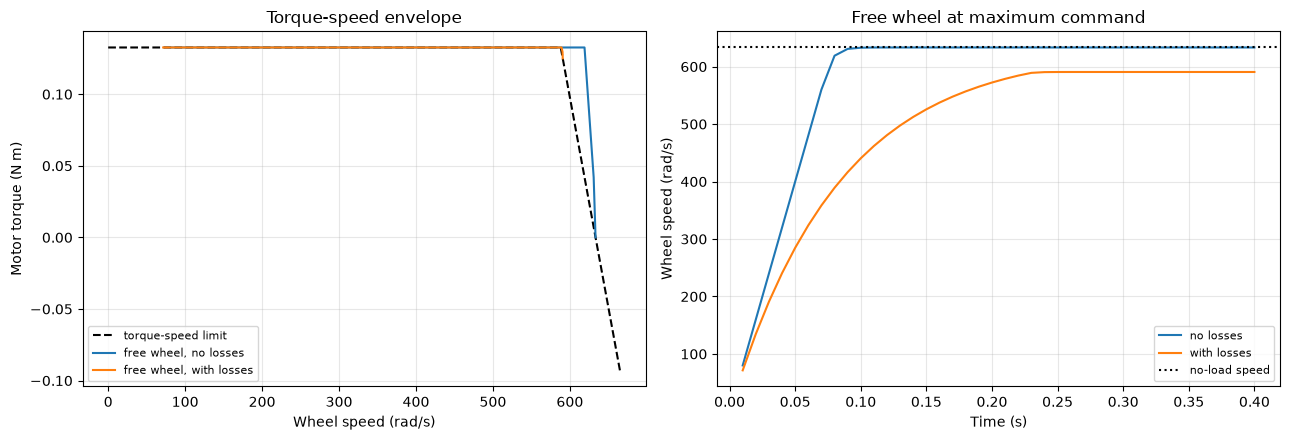

In [10]:
if RUN_PLANT_CHECKS:
    # Motor saturation check: unlimited speed request, wheels spinning freely (friction off).
    stall_torque = rc.MOTOR_KT * rc.IQ_LIMIT
    no_load_speed = rc.MAX_MOTOR_VOLTAGE / rc.MOTOR_KT
    print(f"Motor limits: stall torque K_t*I_max = {stall_torque:.4f} N m; "
          f"no-load speed V_max/K_e = {no_load_speed:.1f} rad/s ({no_load_speed * 60 / (2 * np.pi):.0f} rpm, "
          f"{no_load_speed * rc.WHEEL_RADIUS:.1f} m/s at the rim)")

    def run_saturation(duration_s=0.4, with_losses=False):
        saved = (rc.WHEEL_ROLLING_RESISTANCE_COEFF, rc.WHEEL_BEARING_VISCOUS_DRAG)
        if not with_losses:
            rc.WHEEL_ROLLING_RESISTANCE_COEFF, rc.WHEEL_BEARING_VISCOUS_DRAG = 0.0, 0.0
        try:
            sim = OpenLoopPlant(enable_friction=False)
            speeds, torques = [], []
            for _ in range(int(round(duration_s / SIM_DT_S))):
                state = sim.step(np.full(N_WHEELS, 1e6))
                speeds.append(state["wheel_speeds"].copy())
                torques.append(rc.MOTOR_KT * state["motor_currents"])
            return np.array(speeds), np.array(torques)
        finally:
            rc.WHEEL_ROLLING_RESISTANCE_COEFF, rc.WHEEL_BEARING_VISCOUS_DRAG = saved

    speeds, torques = run_saturation()
    print(f"{OPEN_LOOP_MOTOR_MODE}-driven plant, no losses: peak |torque| {np.max(np.abs(torques)):.4f} N m, "
          f"final wheel speed {speeds[-1].mean():.1f} rad/s ({100 * speeds[-1].mean() / no_load_speed:.1f}% of no-load)")
    assert np.max(np.abs(torques)) <= stall_torque + 1e-9, "Motor torque exceeded K_t * IQ_LIMIT"
    assert np.max(speeds) <= no_load_speed * (1 + 1e-6), "Wheel speed exceeded the no-load speed"
    assert speeds[-1].mean() > 0.98 * no_load_speed, "Free wheel did not reach the no-load speed"
    speeds_loss, torques_loss = run_saturation(with_losses=True)
    print(f"{OPEN_LOOP_MOTOR_MODE}-driven plant, with wheel losses: final wheel speed {speeds_loss[-1].mean():.1f} rad/s "
          f"({100 * speeds_loss[-1].mean() / no_load_speed:.1f}% of no-load)")
    print("PASS: torque never exceeds K_t*I_max, and a free wheel settles at the no-load speed V_max/K_e.")

    envelope_speed = np.linspace(0.0, 1.05 * no_load_speed, 200)
    envelope_state = np.zeros((len(envelope_speed), 10))
    envelope_state[:, 6] = envelope_speed
    envelope_torque = rc.MOTOR_KT * np.array([WheelSlipRobotSimulator.saturate_current(st, np.full(N_WHEELS, 1e6))[0]
                                              for st in envelope_state])
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(envelope_speed, envelope_torque, "k--", label="torque-speed limit")
    axes[0].plot(speeds[:, 0], torques[:, 0], label="free wheel, no losses")
    axes[0].plot(speeds_loss[:, 0], torques_loss[:, 0], label="free wheel, with losses")
    axes[0].set(xlabel="Wheel speed (rad/s)", ylabel="Motor torque (N m)", title="Torque-speed envelope")
    t_sat = np.arange(1, len(speeds) + 1) * SIM_DT_S
    axes[1].plot(t_sat, speeds[:, 0], label="no losses")
    axes[1].plot(t_sat, speeds_loss[:, 0], label="with losses")
    axes[1].axhline(no_load_speed, color="k", linestyle=":", label="no-load speed")
    axes[1].set(xlabel="Time (s)", ylabel="Wheel speed (rad/s)", title="Free wheel at maximum command")
    for ax in axes:
        ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

## 4.2 Simple plant response verification: forward step and stop

A known forward body-velocity command (0.35 m/s) is converted to wheel-speed targets by inverse kinematics; the wheel-speed servo and the plant determine the actual response. The command steps from zero, holds for 1.5 s, then steps back to zero. The test also plots each wheel's d-axis contact slip $v_{d,i}$, the slip used by the contact law.

Expected behaviour: forward velocity rises toward the command, the robot travels straight, and after the zero command the servos brake the wheels and the chassis settles. The layout is mirror-symmetric about body $y$, so lateral velocity and yaw should be zero to round-off.

PASS: forward step-and-stop plant response
  forward displacement at stop: 1.411 m
  additional drift after stop:   0.0999 m
  max chassis speed in settle window: 0.0106 m/s
  max wheel speed in settle window:   0.308 rad/s


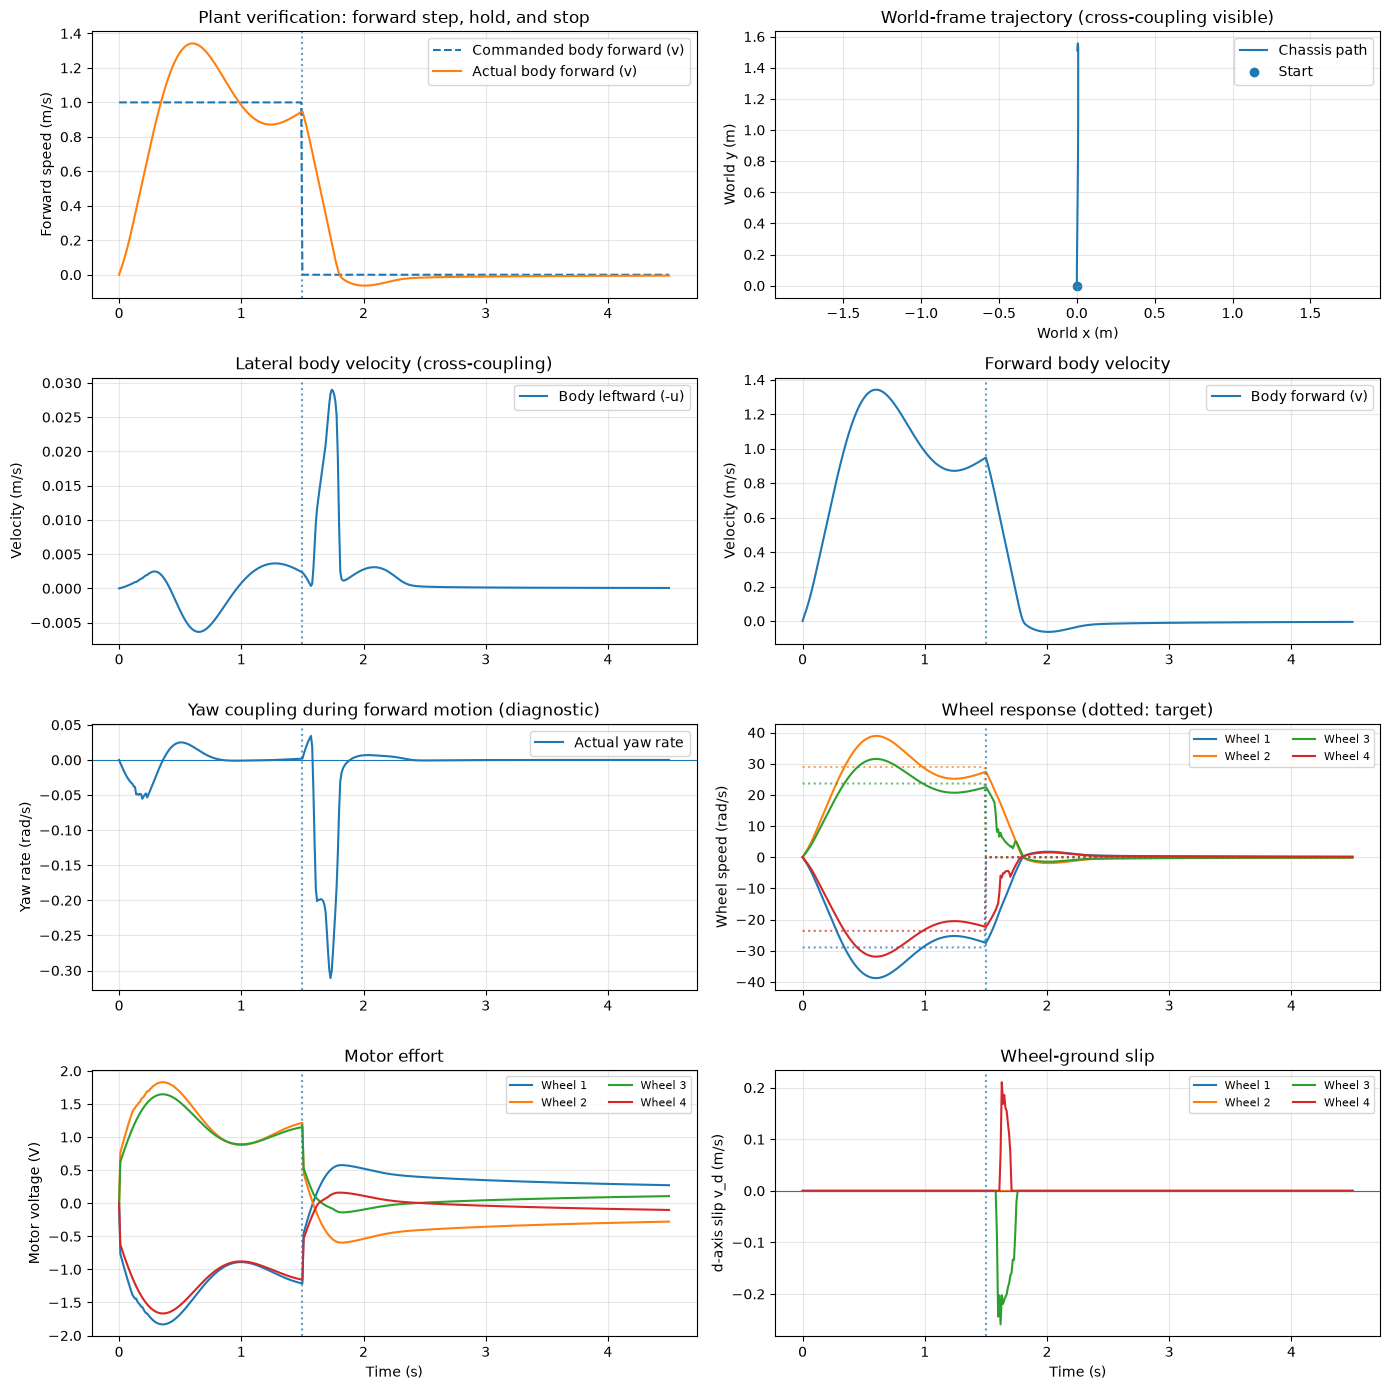

In [11]:
if RUN_PLANT_CHECKS:
    # Controller-independent step-and-stop test for the coupled plant (Dana section 7).
    def run_forward_step_stop_test(dt=SIM_DT_S, step_speed=TEST_FORWARD_SPEED,
                                   step_duration_s=1.5, total_duration_s=4.5):
        """Command forward body speed, then zero; return plant telemetry and assert expected response."""
        if dt <= 0 or step_speed <= 0 or step_duration_s <= 0 or total_duration_s <= step_duration_s:
            raise ValueError("Require dt, step speed, and step duration > 0, and total duration > step duration.")

        # Step to a constant forward body twist, then request zero motion.
        result = run_open_loop_schedule(
            lambda t: body_command(forward=step_speed) if t < step_duration_s else body_command(),
            total_duration_s, dt=dt)
        times, pose, body_velocity = result["time"], result["pose"], result["body_velocity"]

        # Define a settling window after the stop command, excluding the exact switch instant.
        stop_idx = int(np.searchsorted(times, step_duration_s, side="left"))
        settle_start_idx = int(np.searchsorted(times, min(step_duration_s + 1.5, total_duration_s), side="left"))
        final_slice = slice(settle_start_idx, None)
        lateral_max = float(np.max(np.abs(body_velocity[:, RIGHT_AXIS])))
        yaw_rate_max = float(np.max(np.abs(body_velocity[:, 2])))
        final_speed_max = float(np.max(np.abs(body_velocity[final_slice, :2])))
        final_yaw_rate_max = float(np.max(np.abs(body_velocity[final_slice, 2])))
        final_wheel_speed_max = float(np.max(np.abs(result["wheel_speeds"][final_slice])))
        forward_displacement = float(pose[stop_idx, FORWARD_AXIS] - pose[0, FORWARD_AXIS])
        post_stop_drift = float(np.linalg.norm(pose[-1, :2] - pose[stop_idx, :2]))

        # Assertions test intended behavior, not exact time histories.
        assert forward_displacement > 0.25, f"Expected clear forward motion; got {forward_displacement:.3f} m."
        # Sideways drift and yaw are judged relative to the command: the real CoG offset and the
        # unequal wheel loads make a forward command drift and turn a little (it would not on a
        # symmetric robot). Yaw is compared at the wheels, omega L.
        assert lateral_max < 0.1 * step_speed, f"Lateral body velocity {lateral_max:.4f} m/s exceeds 10% of the command."
        assert yaw_rate_max * rc.WHEEL_ROBOT_DIST < 0.1 * step_speed, (
            f"Yaw rate {yaw_rate_max:.3f} rad/s ({yaw_rate_max * rc.WHEEL_ROBOT_DIST:.3f} m/s at the wheels) exceeds 10% of the command.")
        assert final_speed_max < 0.03, f"Chassis did not settle after stop: {final_speed_max:.4f} m/s."
        assert final_yaw_rate_max < 0.02, f"Yaw rate did not settle: {final_yaw_rate_max:.4f} rad/s."
        assert final_wheel_speed_max < 1.0, f"Wheels did not settle after stop: {final_wheel_speed_max:.3f} rad/s."
        assert np.all(np.isfinite(pose)) and np.all(np.isfinite(body_velocity)), "Non-finite state detected."
        assert np.all(np.abs(result["motor_voltages"]) <= rc.MAX_MOTOR_VOLTAGE + 1e-10), "Motor voltage limit violated."
        assert np.all(np.abs(result["motor_currents"]) <= rc.IQ_LIMIT + 1e-3), "Motor current limit violated."
        assert np.all(np.abs(result["ground_forces"][1:]) <= result["friction_limits"][1:] + 1e-8), "Contact force cap violated."

        result.update({
            "step_duration_s": step_duration_s,
            "forward_displacement_m": forward_displacement,
            "post_stop_drift_m": post_stop_drift,
            "settle_speed_max_mps": final_speed_max,
            "settle_wheel_speed_max_rad_s": final_wheel_speed_max,
        })
        return result

    step_stop_result = run_forward_step_stop_test()
    print("PASS: forward step-and-stop plant response")
    print(f"  forward displacement at stop: {step_stop_result['forward_displacement_m']:.3f} m")
    print(f"  additional drift after stop:   {step_stop_result['post_stop_drift_m']:.4f} m")
    print(f"  max chassis speed in settle window: {step_stop_result['settle_speed_max_mps']:.4f} m/s")
    print(f"  max wheel speed in settle window:   {step_stop_result['settle_wheel_speed_max_rad_s']:.3f} rad/s")

    # Plot command tracking, world path, body-axis coupling, wheels, motor effort, and slip
    # (same layout as the lateral test).
    t = step_stop_result["time"]
    stop_t = step_stop_result["step_duration_s"]
    fig, axes = plt.subplots(4, 2, figsize=(14, 14))
    axes[0,0].plot(t, step_stop_result["body_command"][:, FORWARD_AXIS], "--", label="Commanded body forward (v)")
    axes[0,0].plot(t, step_stop_result["body_velocity"][:, FORWARD_AXIS], label="Actual body forward (v)")
    axes[0,0].set_ylabel("Forward speed (m/s)")
    axes[0,0].set_title("Plant verification: forward step, hold, and stop")
    axes[0,0].legend()
    axes[0,1].plot(step_stop_result["pose"][:,0], step_stop_result["pose"][:,1], label="Chassis path")
    axes[0,1].scatter([step_stop_result["pose"][0,0]], [step_stop_result["pose"][0,1]], marker="o", label="Start")
    axes[0,1].set_xlabel("World x (m)"); axes[0,1].set_ylabel("World y (m)")
    axes[0,1].set_title("World-frame trajectory (cross-coupling visible)"); axes[0,1].axis("equal"); axes[0,1].legend()
    axes[1,0].plot(t, -step_stop_result["body_velocity"][:, RIGHT_AXIS], label="Body leftward (-u)")
    axes[1,0].set_ylabel("Velocity (m/s)"); axes[1,0].set_title("Lateral body velocity (cross-coupling)"); axes[1,0].legend()
    axes[1,1].plot(t, step_stop_result["body_velocity"][:, FORWARD_AXIS], label="Body forward (v)")
    axes[1,1].set_ylabel("Velocity (m/s)"); axes[1,1].set_title("Forward body velocity"); axes[1,1].legend()
    axes[2,0].plot(t, step_stop_result["body_velocity"][:,2], label="Actual yaw rate")
    axes[2,0].axhline(0, linewidth=0.8); axes[2,0].set_ylabel("Yaw rate (rad/s)"); axes[2,0].set_title("Yaw coupling during forward motion (diagnostic)"); axes[2,0].legend()
    for i in range(4):
        axes[2,1].plot(t, step_stop_result["wheel_speeds"][:,i], label=f"Wheel {i+1}")
        axes[2,1].plot(t, step_stop_result["wheel_command"][:,i], linestyle=":", alpha=0.7, color=axes[2,1].lines[-1].get_color())
    axes[2,1].set_ylabel("Wheel speed (rad/s)"); axes[2,1].set_title("Wheel response (dotted: target)"); axes[2,1].legend(ncol=2, fontsize=8)
    for i in range(4):
        axes[3,0].plot(t, step_stop_result["motor_voltages"][:,i], label=f"Wheel {i+1}")
    axes[3,0].set_xlabel("Time (s)"); axes[3,0].set_ylabel("Motor voltage (V)"); axes[3,0].set_title("Motor effort"); axes[3,0].legend(ncol=2, fontsize=8)
    for i in range(4):
        axes[3,1].plot(t, step_stop_result["slip_speeds"][:,i], label=f"Wheel {i+1}")
    axes[3,1].axhline(0, linewidth=0.8); axes[3,1].set_xlabel("Time (s)"); axes[3,1].set_ylabel("d-axis slip v_d (m/s)"); axes[3,1].set_title("Wheel-ground slip"); axes[3,1].legend(ncol=2, fontsize=8)
    for ax in axes.flat:
        if ax is not axes[0,1]:
            ax.axvline(stop_t, linestyle=":", alpha=0.7)
        ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

## 4.3 Lateral step response: left → right → stop

This mirrors the forward test for sideways motion: 0.25 m/s left for 1 s, 0.25 m/s right for 1 s, then zero for 2 s. Left is body $-x$ here. The front (30°) and rear (45°) wheel angles differ, so yaw and forward cross-coupling are measured and reported rather than assumed to be zero.

PASS: lateral left -> right -> stop step response
  peak leftward velocity during left command:  0.122 m/s
  peak leftward velocity during right command: -0.134 m/s
  world leftward change during left phase:  0.050 m
  world leftward change during right phase: -0.010 m
  settle-window planar speed max:    0.0068 m/s
  settle-window yaw-rate max (coupling diagnostic): 0.0072 rad/s
  settle-window wheel-speed max:     0.1987 rad/s


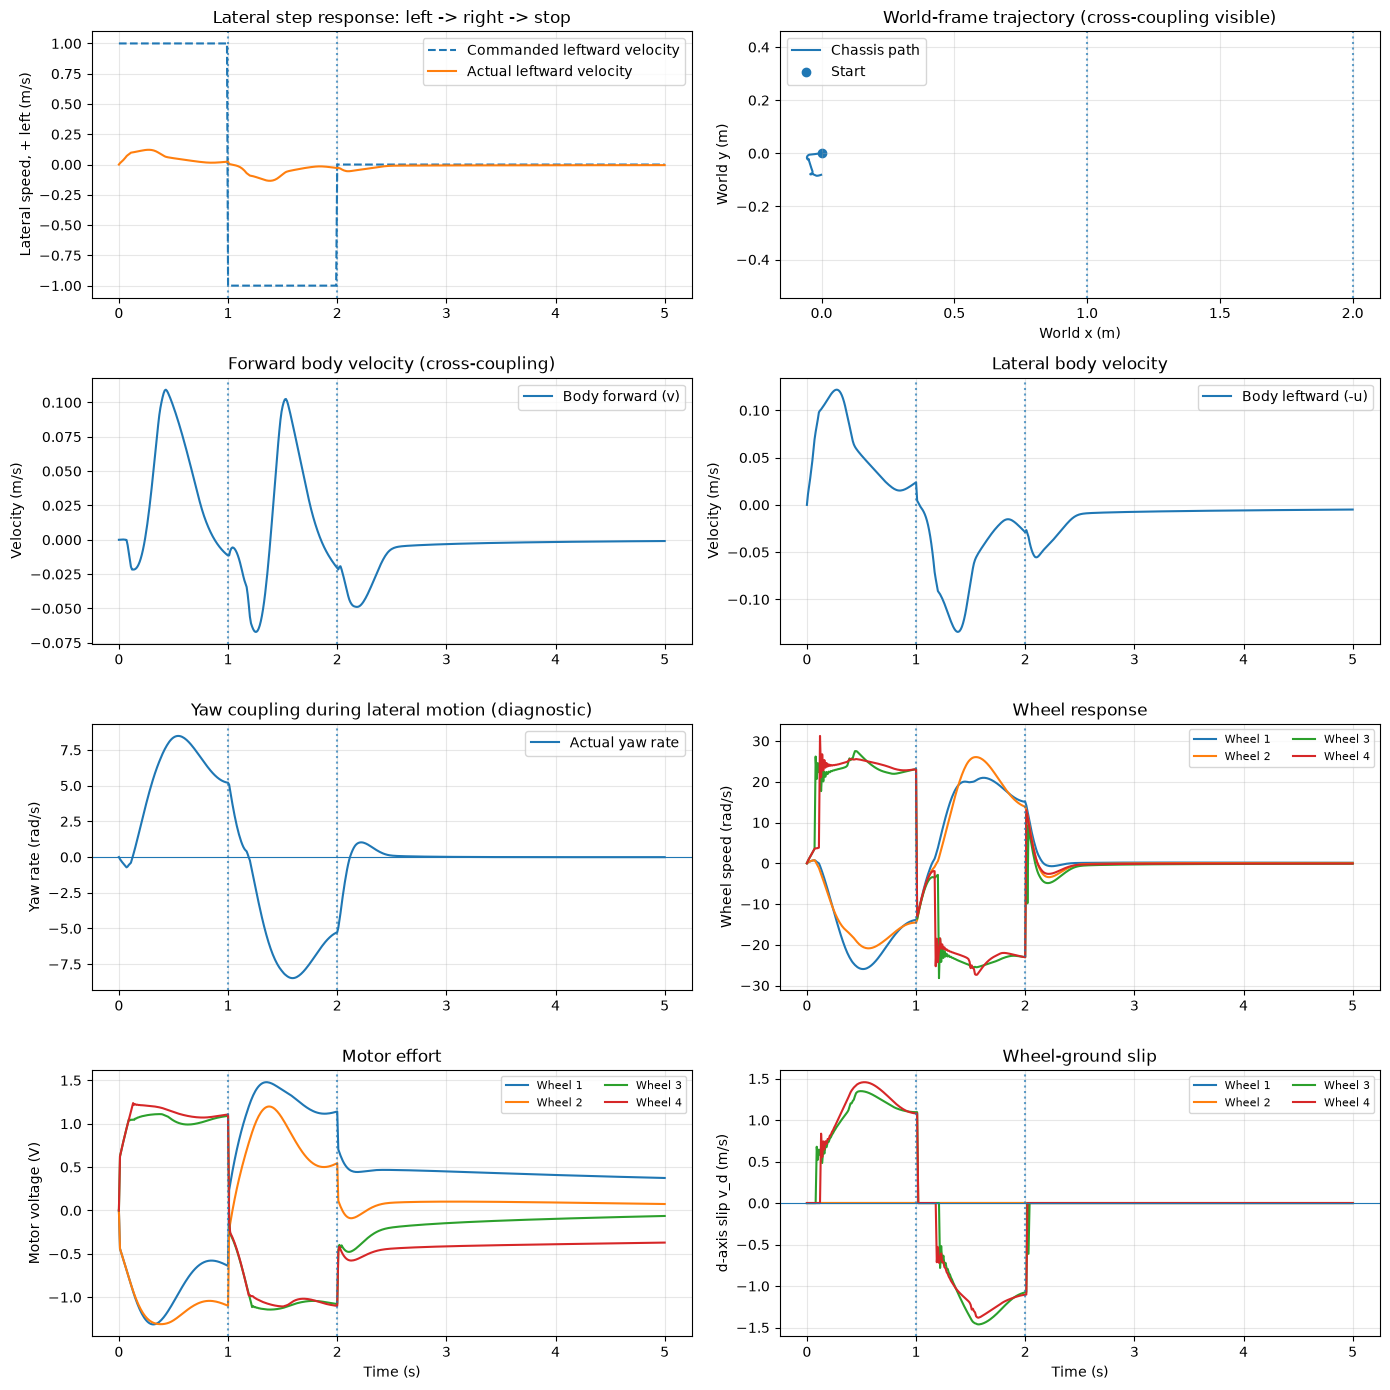

In [12]:
if RUN_PLANT_CHECKS:
    # Controller-independent lateral step response: left -> right -> stop (Dana section 7.1).
    def run_lateral_left_right_stop_test(dt=SIM_DT_S, lateral_speed=TEST_LATERAL_SPEED,
                                        left_duration_s=1.0, right_duration_s=1.0,
                                        stop_duration_s=3.0):
        """Command left body velocity, then right, then stop. Left is body -x in this notebook."""
        if dt <= 0 or lateral_speed <= 0 or min(left_duration_s, right_duration_s, stop_duration_s) <= 0:
            raise ValueError("dt, lateral_speed, and all phase durations must be positive.")
        total_duration_s = left_duration_s + right_duration_s + stop_duration_s

        def command(t):
            if t < left_duration_s:
                return body_command(left=lateral_speed)        # left
            if t < left_duration_s + right_duration_s:
                return body_command(left=-lateral_speed)       # right
            return body_command()                              # stop

        result = run_open_loop_schedule(command, total_duration_s, dt=dt)
        times, pose, body_velocity = result["time"], result["pose"], result["body_velocity"]
        left_velocity = -body_velocity[:, RIGHT_AXIS]

        left_mask = times < left_duration_s
        right_mask = (times >= left_duration_s) & (times < left_duration_s + right_duration_s)
        settle_start = left_duration_s + right_duration_s + min(1.5, stop_duration_s * 0.5)
        settle_mask = times >= settle_start
        peak_left_vy = float(np.max(left_velocity[left_mask]))
        peak_right_vy = float(np.min(left_velocity[right_mask]))
        final_xy_speed_max = float(np.max(np.linalg.norm(body_velocity[settle_mask, :2], axis=1)))
        final_yaw_rate_max = float(np.max(np.abs(body_velocity[settle_mask, 2])))
        final_wheel_speed_max = float(np.max(np.abs(result["wheel_speeds"][settle_mask])))
        left_end_idx = int(np.argmin(np.abs(times - left_duration_s)))
        right_end_idx = int(np.argmin(np.abs(times - (left_duration_s + right_duration_s))))
        # World "left" at the start pose is world -x.
        left_world_change = float(-(pose[left_end_idx, 0] - pose[0, 0]))
        right_world_change = float(-(pose[right_end_idx, 0] - pose[left_end_idx, 0]))

        assert np.all(np.isfinite(pose)) and np.all(np.isfinite(body_velocity)), "Non-finite state detected."
        assert peak_left_vy > 0.08, f"Left command did not produce leftward velocity (peak {peak_left_vy:.3f} m/s)."
        assert peak_right_vy < -0.08, f"Right command did not reverse lateral velocity (peak {peak_right_vy:.3f} m/s)."
        assert left_world_change > 0.03, f"Expected leftward world movement in left phase; got {left_world_change:.3f} m."
        assert final_xy_speed_max < 0.08, f"Robot did not settle after stop: final planar speed max={final_xy_speed_max:.3f} m/s."
        assert final_yaw_rate_max < 0.50, f"Yaw cross-coupling became unexpectedly large: settle-window yaw-rate max={final_yaw_rate_max:.3f} rad/s."
        assert final_wheel_speed_max < 1.0, f"Wheels did not settle after stop: {final_wheel_speed_max:.3f} rad/s."
        assert np.all(np.abs(result["motor_voltages"]) <= rc.MAX_MOTOR_VOLTAGE + 1e-10), "Motor voltage limit violated."
        assert np.all(np.abs(result["motor_currents"]) <= rc.IQ_LIMIT + 1e-3), "Motor current limit violated."
        assert np.all(np.abs(result["ground_forces"][1:]) <= result["friction_limits"][1:] + 1e-8), "Contact force cap violated."

        result.update({
            "left_velocity": left_velocity,
            "left_duration_s": left_duration_s, "right_duration_s": right_duration_s,
            "left_world_change_m": left_world_change,
            "right_world_change_m": right_world_change,
            "peak_left_vy_mps": peak_left_vy, "peak_right_vy_mps": peak_right_vy,
            "settle_planar_speed_max_mps": final_xy_speed_max,
            "settle_yaw_rate_max_rad_s": final_yaw_rate_max,
            "settle_wheel_speed_max_rad_s": final_wheel_speed_max,
        })
        return result

    lateral_result = run_lateral_left_right_stop_test()
    print("PASS: lateral left -> right -> stop step response")
    print(f"  peak leftward velocity during left command:  {lateral_result['peak_left_vy_mps']:.3f} m/s")
    print(f"  peak leftward velocity during right command: {lateral_result['peak_right_vy_mps']:.3f} m/s")
    print(f"  world leftward change during left phase:  {lateral_result['left_world_change_m']:.3f} m")
    print(f"  world leftward change during right phase: {lateral_result['right_world_change_m']:.3f} m")
    print(f"  settle-window planar speed max:    {lateral_result['settle_planar_speed_max_mps']:.4f} m/s")
    print(f"  settle-window yaw-rate max (coupling diagnostic): {lateral_result['settle_yaw_rate_max_rad_s']:.4f} rad/s")
    print(f"  settle-window wheel-speed max:     {lateral_result['settle_wheel_speed_max_rad_s']:.4f} rad/s")

    # Plot command tracking, world path, body-axis coupling, wheels, motor effort, and slip.
    t = lateral_result["time"]
    t_left = lateral_result["left_duration_s"]
    t_right = t_left + lateral_result["right_duration_s"]
    fig, axes = plt.subplots(4, 2, figsize=(14, 14))
    axes[0,0].plot(t, -lateral_result["body_command"][:, RIGHT_AXIS], "--", label="Commanded leftward velocity")
    axes[0,0].plot(t, lateral_result["left_velocity"], label="Actual leftward velocity")
    axes[0,0].set_ylabel("Lateral speed, + left (m/s)")
    axes[0,0].set_title("Lateral step response: left -> right -> stop")
    axes[0,0].legend()
    axes[0,1].plot(lateral_result["pose"][:,0], lateral_result["pose"][:,1], label="Chassis path")
    axes[0,1].scatter([lateral_result["pose"][0,0]], [lateral_result["pose"][0,1]], marker="o", label="Start")
    axes[0,1].set_xlabel("World x (m)"); axes[0,1].set_ylabel("World y (m)")
    axes[0,1].set_title("World-frame trajectory (cross-coupling visible)"); axes[0,1].axis("equal"); axes[0,1].legend()
    axes[1,0].plot(t, lateral_result["body_velocity"][:, FORWARD_AXIS], label="Body forward (v)")
    axes[1,0].set_ylabel("Velocity (m/s)"); axes[1,0].set_title("Forward body velocity (cross-coupling)"); axes[1,0].legend()
    axes[1,1].plot(t, lateral_result["left_velocity"], label="Body leftward (-u)")
    axes[1,1].set_ylabel("Velocity (m/s)"); axes[1,1].set_title("Lateral body velocity"); axes[1,1].legend()
    axes[2,0].plot(t, lateral_result["body_velocity"][:,2], label="Actual yaw rate")
    axes[2,0].axhline(0, linewidth=0.8); axes[2,0].set_ylabel("Yaw rate (rad/s)"); axes[2,0].set_title("Yaw coupling during lateral motion (diagnostic)"); axes[2,0].legend()
    for i in range(4):
        axes[2,1].plot(t, lateral_result["wheel_speeds"][:,i], label=f"Wheel {i+1}")
    axes[2,1].set_ylabel("Wheel speed (rad/s)"); axes[2,1].set_title("Wheel response"); axes[2,1].legend(ncol=2, fontsize=8)
    for i in range(4):
        axes[3,0].plot(t, lateral_result["motor_voltages"][:,i], label=f"Wheel {i+1}")
    axes[3,0].set_xlabel("Time (s)"); axes[3,0].set_ylabel("Motor voltage (V)"); axes[3,0].set_title("Motor effort"); axes[3,0].legend(ncol=2, fontsize=8)
    for i in range(4):
        axes[3,1].plot(t, lateral_result["slip_speeds"][:,i], label=f"Wheel {i+1}")
    axes[3,1].axhline(0, linewidth=0.8); axes[3,1].set_xlabel("Time (s)"); axes[3,1].set_ylabel("d-axis slip v_d (m/s)"); axes[3,1].set_title("Wheel-ground slip"); axes[3,1].legend(ncol=2, fontsize=8)
    for ax in axes.flat:
        ax.axvline(t_left, linestyle=":", alpha=0.7)
        ax.axvline(t_right, linestyle=":", alpha=0.7)
        ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

## 4.4 Additional independent plant verification checks

1. **Zero-input equilibrium:** with zero initial velocity and a zero wheel-speed command, the robot stays at rest.
2. **Lateral and yaw step responses:** each body axis separately (0.25 m/s left, 0.8 rad/s yaw), with cross-axis leakage plotted.
3. **Right → left → stop:** −0.6 rad/s for 1 s, +0.6 rad/s for 1 s, then zero. Checks yaw-rate sign reversal, heading change both ways, and residual motion after stopping.
4. **Friction ablation:** the same forward command with contact friction on and off. With friction off, the wheels spin and the chassis does not move.
5. **Timestep convergence:** the forward step/stop at `dt` = 10, 5, 2.5 and 1.25 ms. Large changes with `dt` indicate numerical error, not physics.

These are model-consistency checks, not validation against measured hardware data.

PASS: zero-input equilibrium — pose, chassis velocity, and wheel speeds remain zero.
lateral step: 0.081 m travelled sideways in the body frame; heading change +305.8 deg
PASS: lateral/yaw response is finite and produces the commanded-axis motion.
  lateral test peak |yaw rate| (cross-axis diagnostic): 8.481 rad/s
  yaw test final heading: 7.002 rad; final translation: 0.0017 m


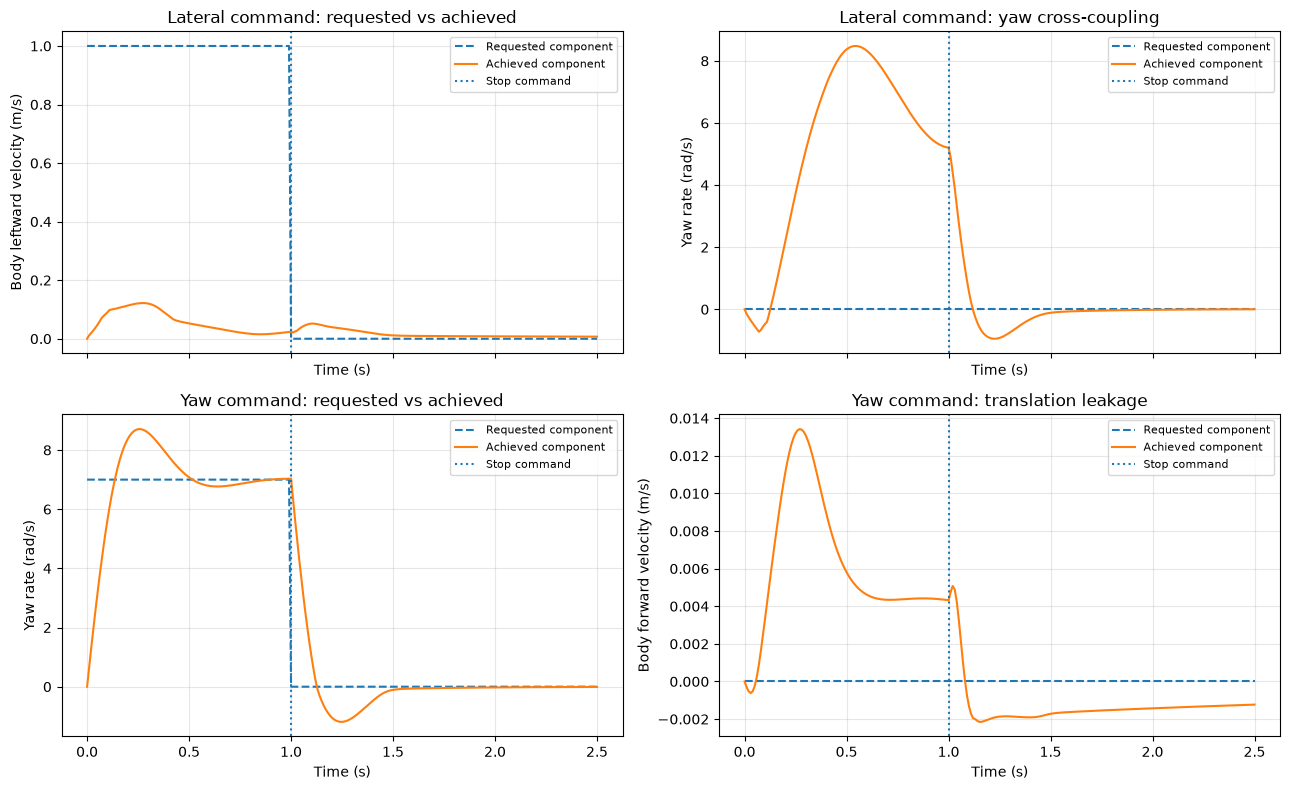

PASS: right -> left -> stop — yaw direction reverses, heading responds both ways, and motion settles.
  peak yaw rate during right command: -8.708 rad/s
  peak yaw rate during left command:  10.182 rad/s
  heading after right: -6.905 rad; after left: -0.183 rad; final: -0.082 rad
  final body-speed norm: 0.0022; max final wheel speed: 0.0558 rad/s


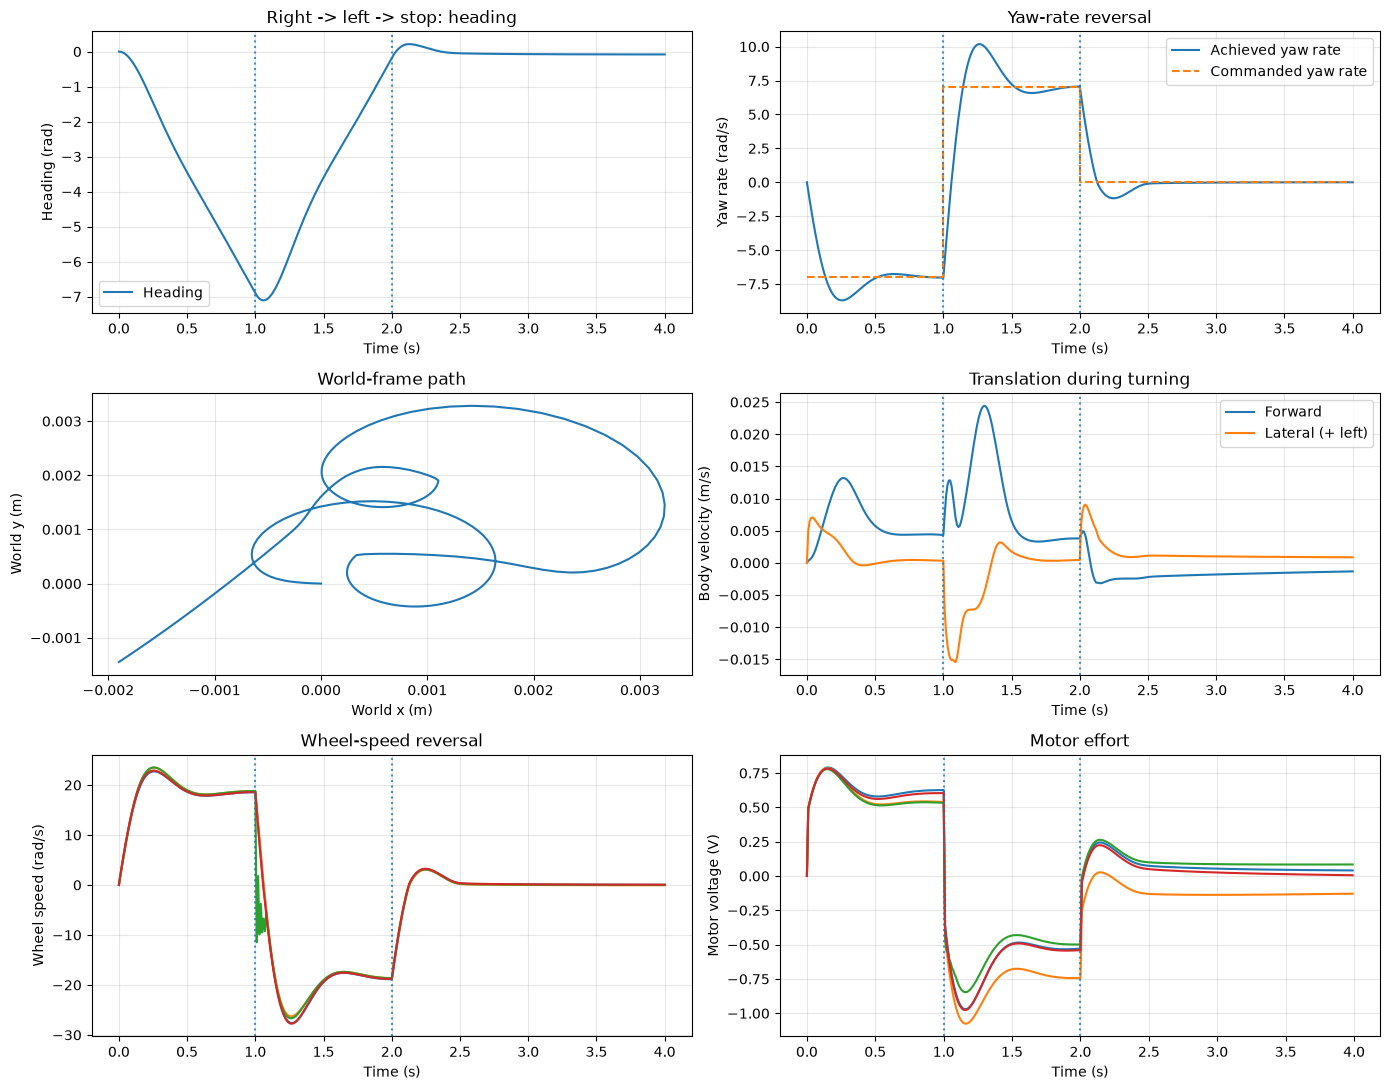

PASS: friction ablation — traction moves the chassis; friction-off wheels spin without chassis motion.


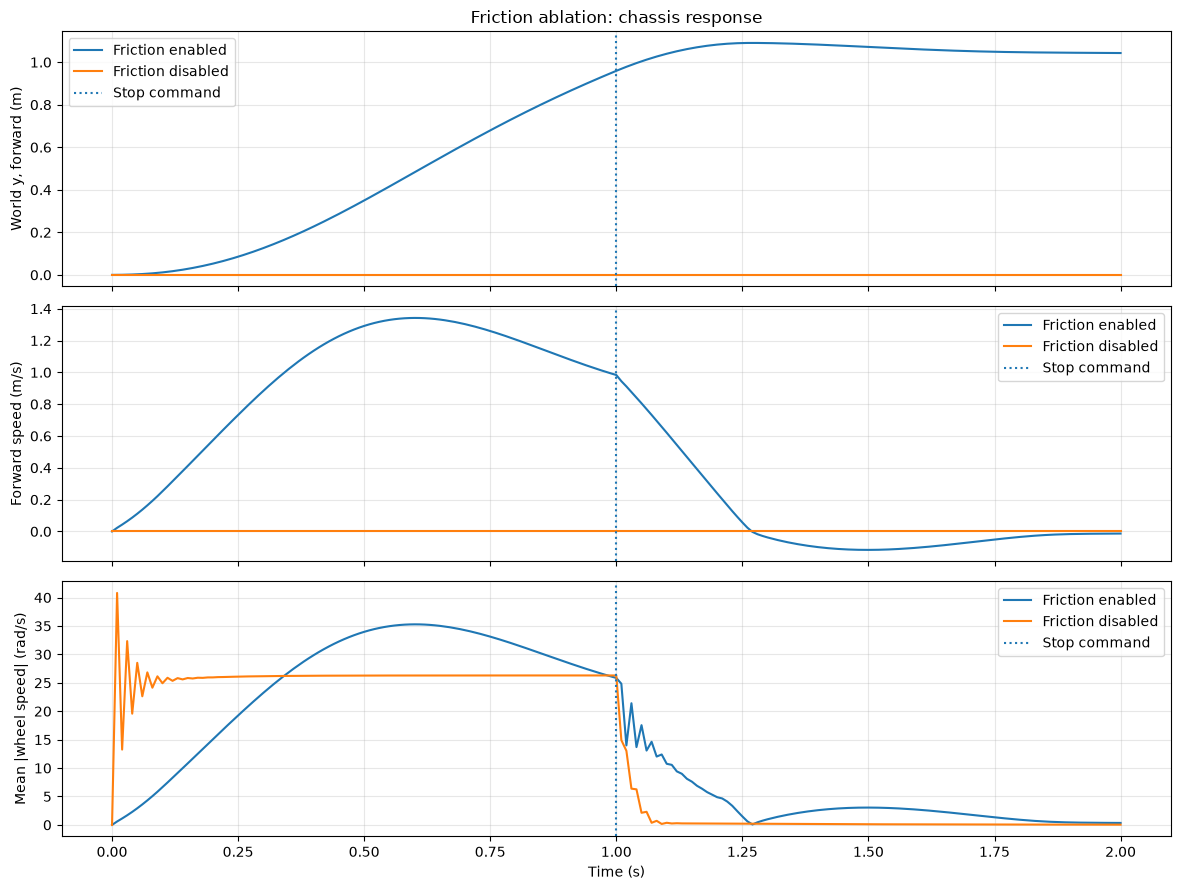

  dt=0.01000 s | forward at stop=1.41139 m | post-stop drift=0.10627 m | peak |yaw rate|=0.31087 rad/s | displacement delta vs finest=0.00159 m
  dt=0.00500 s | forward at stop=1.41058 m | post-stop drift=0.10877 m | peak |yaw rate|=0.35820 rad/s | displacement delta vs finest=0.00078 m
  dt=0.00250 s | forward at stop=1.40999 m | post-stop drift=0.10985 m | peak |yaw rate|=0.37262 rad/s | displacement delta vs finest=0.00019 m
  dt=0.00125 s | forward at stop=1.40980 m | post-stop drift=0.11046 m | peak |yaw rate|=0.38572 rad/s | displacement delta vs finest=0.00000 m
PASS: finest-step displacement converges within 2 mm; coarse-step deviation is reported above.


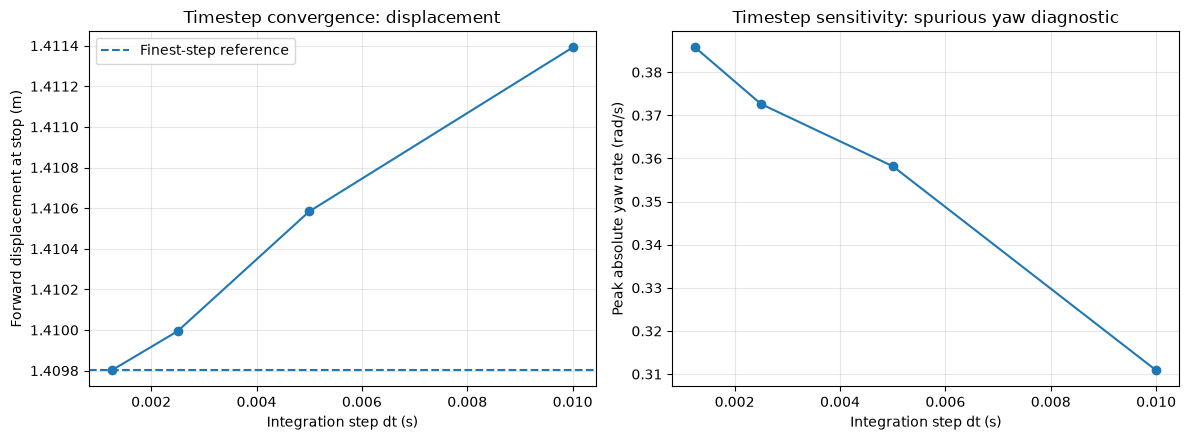

In [13]:
if RUN_PLANT_CHECKS:
    # Verification helpers and tests (Dana section 7.1, additional checks). Keep these separate from PID/MPC.
    def run_open_loop_body_step(command, duration_s=2.5, step_duration_s=1.0,
                                dt=SIM_DT_S, enable_friction=True, load_model=None):
        """Apply a body-twist step through inverse kinematics and the wheel-speed servo/plant."""
        if dt <= 0 or duration_s <= step_duration_s or step_duration_s <= 0:
            raise ValueError("Require dt > 0 and duration_s > step_duration_s > 0.")
        command = np.asarray(command, dtype=float)
        result = run_open_loop_schedule(
            lambda t: command if t < step_duration_s else body_command(),
            duration_s, dt=dt, enable_friction=enable_friction, load_model=load_model)
        result["velocity"] = result["body_velocity"]
        result["step_duration_s"] = step_duration_s
        return result

    # Check 1: zero-input equilibrium (no controller and no external disturbance).
    zero_sim = OpenLoopPlant()
    zero_pose0 = zero_sim.state[0:3].copy()
    for _ in range(500):
        zero_state = zero_sim.step(np.zeros(4))
    assert np.allclose(zero_state["pose"], zero_pose0, atol=1e-12)
    assert np.allclose(zero_state["body_velocity"], 0.0, atol=1e-12)
    assert np.allclose(zero_state["wheel_speeds"], 0.0, atol=1e-12)
    print("PASS: zero-input equilibrium — pose, chassis velocity, and wheel speeds remain zero.")

    # Check 2: lateral and yaw responses. Lateral cross-coupling is measured, not hidden.
    LATERAL_STEP_SPEED = TEST_LATERAL_SPEED
    YAW_STEP_RATE = TEST_YAW_RATE
    lateral_step_result = run_open_loop_body_step(body_command(left=LATERAL_STEP_SPEED))
    yaw_result = run_open_loop_body_step(body_command(yaw_rate=YAW_STEP_RATE))
    assert np.all(np.isfinite(lateral_step_result["pose"])) and np.all(np.isfinite(lateral_step_result["velocity"]))
    assert np.all(np.isfinite(yaw_result["pose"])) and np.all(np.isfinite(yaw_result["velocity"]))
    # Sideways distance travelled in the robot's own frame (left = body -x). In the world frame it can be
    # small: with the real CoG a sideways command also turns the robot.
    left_speed, step_time = -lateral_step_result["velocity"][:, RIGHT_AXIS], lateral_step_result["time"]
    lateral_travel = float(np.sum(0.5 * (left_speed[1:] + left_speed[:-1]) * np.diff(step_time)))
    print(f"lateral step: {lateral_travel:.3f} m travelled sideways in the body frame; heading change "
          f"{np.degrees(lateral_step_result['pose'][-1, 2]):+.1f} deg")
    # Open loop nothing holds the heading: with the real CoG the rear wheels slide and a sideways
    # command turns into a spin, so the check is on the first 0.1 s (before the spin builds up).
    initial_left = float(np.mean(left_speed[(step_time > 0.0) & (step_time <= 0.1)]))
    assert initial_left > 0.0, "Lateral command did not start moving the robot sideways."
    assert abs(yaw_result["pose"][-1, 2]) > 0.50, "Yaw command produced too little heading change."
    yaw_translation = float(np.linalg.norm(yaw_result["pose"][-1, :2]))
    assert yaw_translation < 0.05, f"Pure-yaw command caused unexpectedly large translation ({yaw_translation:.3f} m)."
    lat_cross_yaw = float(np.max(np.abs(lateral_step_result["velocity"][:, 2])))
    print("PASS: lateral/yaw response is finite and produces the commanded-axis motion.")
    print(f"  lateral test peak |yaw rate| (cross-axis diagnostic): {lat_cross_yaw:.3f} rad/s")
    print(f"  yaw test final heading: {yaw_result['pose'][-1, 2]:.3f} rad; final translation: {yaw_translation:.4f} m")

    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
    for ax, result, axis, sign, requested, title, ylabel in [
        (axes[0,0], lateral_step_result, RIGHT_AXIS, -1.0, LATERAL_STEP_SPEED,
         "Lateral command: requested vs achieved", "Body leftward velocity (m/s)"),
        (axes[0,1], lateral_step_result, 2, 1.0, 0.0, "Lateral command: yaw cross-coupling", "Yaw rate (rad/s)"),
        (axes[1,0], yaw_result, 2, 1.0, YAW_STEP_RATE, "Yaw command: requested vs achieved", "Yaw rate (rad/s)"),
        (axes[1,1], yaw_result, FORWARD_AXIS, 1.0, 0.0, "Yaw command: translation leakage", "Body forward velocity (m/s)")]:
        tt = result["time"]
        command_trace = np.where(tt < result["step_duration_s"], requested, 0.0)
        ax.plot(tt, command_trace, linestyle="--", label="Requested component")
        ax.plot(tt, sign * result["velocity"][:, axis], label="Achieved component")
        ax.axvline(result["step_duration_s"], linestyle=":", label="Stop command")
        ax.set_title(title); ax.set_ylabel(ylabel); ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    for ax in axes.flat: ax.set_xlabel("Time (s)")
    plt.tight_layout(); plt.show()

    # Check 3: right turn -> left turn -> stop. This is an open-loop body-command test,
    # with the same inverse kinematics, wheel-speed PI, current limit, and plant as other checks.
    right_duration_s = 1.0
    left_duration_s = 1.0
    turn_stop_duration_s = 2.0
    turn_total_s = right_duration_s + left_duration_s + turn_stop_duration_s
    turn_rate_cmd = TEST_YAW_RATE  # rad/s; right is negative yaw, left is positive yaw by convention

    def turn_command(t):
        if t < right_duration_s:
            return body_command(yaw_rate=-turn_rate_cmd)
        if t < right_duration_s + left_duration_s:
            return body_command(yaw_rate=turn_rate_cmd)
        return body_command()

    turn_result = run_open_loop_schedule(turn_command, turn_total_s)
    turn_time = turn_result["time"]
    turn_poses = turn_result["pose"]
    turn_velocities = turn_result["body_velocity"]
    turn_wheels = turn_result["wheel_speeds"]
    turn_voltages = turn_result["motor_voltages"]
    turn_commands = turn_result["body_command"][:-1]
    right_mask = turn_time[:-1] < right_duration_s
    left_mask = (turn_time[:-1] >= right_duration_s) & (turn_time[:-1] < right_duration_s + left_duration_s)
    right_peak_yaw = float(np.min(turn_velocities[:-1, 2][right_mask]))
    left_peak_yaw = float(np.max(turn_velocities[:-1, 2][left_mask]))
    heading_after_right = float(turn_poses[np.argmin(np.abs(turn_time-right_duration_s)), 2])
    heading_after_left = float(turn_poses[np.argmin(np.abs(turn_time-(right_duration_s+left_duration_s))), 2])
    final_speed = float(np.linalg.norm(turn_velocities[-1]))
    final_wheel_speed = float(np.max(np.abs(turn_wheels[-1])))
    assert np.all(np.isfinite(turn_poses)) and np.all(np.isfinite(turn_velocities))
    assert right_peak_yaw < -0.10, f"Right-turn command did not produce negative yaw rate (peak {right_peak_yaw:.3f} rad/s)."
    assert left_peak_yaw > 0.10, f"Left-turn command did not reverse yaw rate (peak {left_peak_yaw:.3f} rad/s)."
    assert heading_after_right < -0.10, f"Heading did not change in the right-turn direction ({heading_after_right:.3f} rad)."
    assert heading_after_left > heading_after_right + 0.10, "Heading did not reverse direction during the left-turn phase."
    assert final_speed < 0.08, f"Robot did not settle after stop: final body-speed norm={final_speed:.3f} m/s/rad/s."
    assert final_wheel_speed < 1.0, f"Wheel speeds remain high after stop: {final_wheel_speed:.3f} rad/s."
    print("PASS: right -> left -> stop — yaw direction reverses, heading responds both ways, and motion settles.")
    print(f"  peak yaw rate during right command: {right_peak_yaw:.3f} rad/s")
    print(f"  peak yaw rate during left command:  {left_peak_yaw:.3f} rad/s")
    print(f"  heading after right: {heading_after_right:.3f} rad; after left: {heading_after_left:.3f} rad; final: {turn_poses[-1,2]:.3f} rad")
    print(f"  final body-speed norm: {final_speed:.4f}; max final wheel speed: {final_wheel_speed:.4f} rad/s")

    fig, axes = plt.subplots(3, 2, figsize=(14, 11))
    axes[0,0].plot(turn_time, turn_poses[:,2], label="Heading")
    axes[0,0].set_ylabel("Heading (rad)"); axes[0,0].set_title("Right -> left -> stop: heading"); axes[0,0].legend()
    axes[0,1].plot(turn_time, turn_velocities[:,2], label="Achieved yaw rate")
    axes[0,1].step(turn_time[:-1], turn_commands[:,2], where="post", linestyle="--", label="Commanded yaw rate")
    axes[0,1].set_ylabel("Yaw rate (rad/s)"); axes[0,1].set_title("Yaw-rate reversal"); axes[0,1].legend()
    axes[1,0].plot(turn_poses[:,0], turn_poses[:,1])
    axes[1,0].set_xlabel("World x (m)"); axes[1,0].set_ylabel("World y (m)"); axes[1,0].set_title("World-frame path")
    axes[1,1].plot(turn_time, turn_velocities[:,FORWARD_AXIS], label="Forward")
    axes[1,1].plot(turn_time, -turn_velocities[:,RIGHT_AXIS], label="Lateral (+ left)")
    axes[1,1].set_ylabel("Body velocity (m/s)"); axes[1,1].set_title("Translation during turning"); axes[1,1].legend()
    axes[2,0].plot(turn_time, turn_wheels)
    axes[2,0].set_ylabel("Wheel speed (rad/s)"); axes[2,0].set_title("Wheel-speed reversal")
    axes[2,1].plot(turn_time[:-1], turn_voltages[:-1])
    axes[2,1].set_ylabel("Motor voltage (V)"); axes[2,1].set_title("Motor effort")
    for ax in axes.flat:
        if ax is not axes[1,0]:
            ax.axvline(right_duration_s, linestyle=":", alpha=0.8)
            ax.axvline(right_duration_s + left_duration_s, linestyle=":", alpha=0.8)
        ax.grid(True, alpha=0.3)
    for ax in (axes[0,0], axes[0,1], axes[1,1], axes[2,0], axes[2,1]): ax.set_xlabel("Time (s)")
    plt.tight_layout(); plt.show()

    # Check 4: friction ablation. Identical command, only contact-force transmission differs.
    friction_on = run_open_loop_body_step(body_command(forward=TEST_FORWARD_SPEED), duration_s=2.0,
                                          step_duration_s=1.0, enable_friction=True)
    friction_off = run_open_loop_body_step(body_command(forward=TEST_FORWARD_SPEED), duration_s=2.0,
                                           step_duration_s=1.0, enable_friction=False)
    assert abs(friction_on["pose"][-1, FORWARD_AXIS]) > 0.10, "With friction enabled, forward traction should move the chassis."
    assert np.max(np.abs(friction_off["pose"][:, :])) < 1e-12, "Friction-off ablation should transmit no chassis force."
    assert np.max(np.abs(friction_off["wheel_speeds"])) > 1.0, "With friction off, wheel motors should still spin the wheels."
    print("PASS: friction ablation — traction moves the chassis; friction-off wheels spin without chassis motion.")

    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    for result, label in [(friction_on, "Friction enabled"), (friction_off, "Friction disabled")]:
        tt = result["time"]
        axes[0].plot(tt, result["pose"][:, FORWARD_AXIS], label=label)
        axes[1].plot(tt, result["velocity"][:, FORWARD_AXIS], label=label)
        axes[2].plot(tt, np.mean(np.abs(result["wheel_speeds"]), axis=1), label=label)
    for ax in axes:
        ax.axvline(1.0, linestyle=":", label="Stop command")
        ax.grid(True, alpha=0.3); ax.legend()
    axes[0].set_ylabel("World y, forward (m)"); axes[0].set_title("Friction ablation: chassis response")
    axes[1].set_ylabel("Forward speed (m/s)")
    axes[2].set_ylabel("Mean |wheel speed| (rad/s)"); axes[2].set_xlabel("Time (s)")
    plt.tight_layout(); plt.show()

    # Check 5: integration-step sensitivity using the same command schedule and parameters.
    # Here dt is the servo/hold interval; the plant solver inside each interval is adaptive with max_step = dt.
    # Deliberately do not use run_forward_step_stop_test's pass/fail thresholds here:
    # this is a numerical convergence experiment, including a coarser step that may be inaccurate.
    dt_values = [0.01, 0.005, 0.0025, 0.00125]
    convergence_rows = []
    convergence_runs = {}
    for dt_test in dt_values:
        r = run_open_loop_body_step(body_command(forward=TEST_FORWARD_SPEED), duration_s=3.5,
                                    step_duration_s=1.5, dt=dt_test, enable_friction=True)
        stop_idx = int(np.argmin(np.abs(r["time"] - 1.5)))
        displacement_at_stop = float(r["pose"][stop_idx, FORWARD_AXIS] - r["pose"][0, FORWARD_AXIS])
        post_stop_drift = float(np.linalg.norm(r["pose"][-1, :2] - r["pose"][stop_idx, :2]))
        peak_yaw_rate = float(np.max(np.abs(r["velocity"][:, 2])))
        convergence_rows.append((dt_test, displacement_at_stop, post_stop_drift, peak_yaw_rate))
        convergence_runs[dt_test] = r
    reference_displacement = convergence_rows[-1][1]
    for row in convergence_rows:
        print(f"  dt={row[0]:.5f} s | forward at stop={row[1]:.5f} m | post-stop drift={row[2]:.5f} m | peak |yaw rate|={row[3]:.5f} rad/s | displacement delta vs finest={abs(row[1]-reference_displacement):.5f} m")
    assert abs(convergence_rows[-2][1] - convergence_rows[-1][1]) < 0.002, \
        "The two finest time steps did not converge within 2 mm; inspect integration stability/model stiffness."
    print("PASS: finest-step displacement converges within 2 mm; coarse-step deviation is reported above.")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot([row[0] for row in convergence_rows], [row[1] for row in convergence_rows], marker="o")
    axes[0].axhline(reference_displacement, linestyle="--", label="Finest-step reference")
    axes[0].set_xlabel("Integration step dt (s)"); axes[0].set_ylabel("Forward displacement at stop (m)")
    axes[0].set_title("Timestep convergence: displacement"); axes[0].grid(True, alpha=0.3); axes[0].legend()
    axes[1].plot([row[0] for row in convergence_rows], [row[3] for row in convergence_rows], marker="o")
    axes[1].set_xlabel("Integration step dt (s)"); axes[1].set_ylabel("Peak absolute yaw rate (rad/s)")
    axes[1].set_title("Timestep sensitivity: spurious yaw diagnostic"); axes[1].grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

### Wheel directions and the equal-command check

Dana's suggested check: equal current on all four wheels should drive the robot straight, with the wheel angles cancelling in yaw. That holds for her sign convention, not for this one. Both conventions are self-consistent; they differ in what "positive" means for each motor:

- **This notebook:** every drive direction $\hat{\mathbf d}_i$ is the CCW tangent ($\hat{\mathbf a}_i$ rotated +90°), so every yaw lever is $+L$. Positive current on every wheel spins the robot. The table below shows that, plus inverse kinematics: forward motion needs the sign pattern $[-,+,+,-]$, and pure yaw needs equal speeds on all four wheels. This matches identical motors all mounted with their shafts pointing outward.
- **Dana's notebook:** the left and right drive directions are mirrored, so her yaw levers come in ± pairs (her Jacobian's third column is $[-0.52, 0.52, -2, 2]$) and equal commands cancel in yaw.

The check below therefore tests the equivalent statement in this convention, in both motor models. Equal commands must give mainly yaw, and the forward sign pattern must drive straight with zero yaw and zero lateral velocity. Which convention the firmware uses for each motor is a hardware question; switching would only flip the sign of individual wheels.

In [14]:
if RUN_PLANT_CHECKS:
    # Wheel directions and equal-command check.
    drive, axle = wheel_directions_body()
    radius = wheel_positions_body()
    print("wheel          alpha   position r_i [m] (x right, y fwd)   drive d_i          yaw lever r_i x d_i [m]")
    for i, name in enumerate(rc.WHEEL_NAMES):
        lever = radius[0, i] * drive[1, i] - radius[1, i] * drive[0, i]
        print(f"{name:12s} {rc.WHEEL_ALPHA_DEG[i]:6.0f}   [{radius[0, i]:+.4f}, {radius[1, i]:+.4f}]"
              f"                [{drive[0, i]:+.3f}, {drive[1, i]:+.3f}]   {lever:+.4f}")
    for label, twist in [(f"forward {TEST_FORWARD_SPEED} m/s", body_command(forward=TEST_FORWARD_SPEED)),
                         (f"left {TEST_LATERAL_SPEED} m/s", body_command(left=TEST_LATERAL_SPEED)),
                         (f"yaw +{TEST_YAW_RATE} rad/s (CCW)", body_command(yaw_rate=TEST_YAW_RATE))]:
        print(f"inverse kinematics, {label:18s}: wheel speeds {inverse_kinematics(twist)} rad/s")

    forward_pattern = np.sign(inverse_kinematics(body_command(forward=1.0)))

    def hold_command(motor_mode, pattern, duration_s=0.3, centred=True):
        """Hold the same command magnitude on every wheel with a sign pattern; return the body twist.

        centred=True puts the CoG at P with equal wheel loads, so the check isolates the wheel
        directions. centred=False uses the configured CoG and load model: a CoG off to one side,
        or unequal rolling resistance on unequally loaded wheels, then turns the robot.
        """
        saved_cog = (rc.COG_OFFSET[0] * 1e3, rc.COG_OFFSET[1] * 1e3, rc.COG_HEIGHT * 1e3)
        load_model = "equal" if centred else None
        if centred:
            rc.set_center_of_gravity(0.0, 0.0, saved_cog[2])
        try:
            if motor_mode == "current":
                plant, command = WheelSlipRobotSimulator(dt=DT, initial_state=np.zeros(10), load_model=load_model), 2.0 * pattern   # A
            else:
                plant, command = VoltageDrivenSlipSimulator(dt=DT, initial_state=np.zeros(14), load_model=load_model), 1.0 * pattern  # V
        finally:
            rc.set_center_of_gravity(*saved_cog)
        state = plant.state.copy()
        for _ in range(int(round(duration_s / DT))):
            state = plant.discrete_map(state, command, np.zeros(3))
        return np.r_[world_to_body(state[3:5], state[2]), state[5]]

    for motor_mode, unit in (("current", "2 A"),):
        equal = hold_command(motor_mode, np.ones(N_WHEELS))
        straight = hold_command(motor_mode, forward_pattern)
        print(f"{motor_mode} mode, {unit} on every wheel for 0.3 s:          [u, v, omega] = {equal}")
        print(f"{motor_mode} mode, {unit} with forward pattern {forward_pattern}: [u, v, omega] = {straight}")
        assert abs(equal[2]) > 10 * np.max(np.abs(equal[:2])), "Equal commands should give mainly yaw in this convention"
        assert straight[FORWARD_AXIS] > 0 and abs(straight[2]) < 1e-6 and abs(straight[RIGHT_AXIS]) < 1e-6, \
            "Forward sign pattern should drive straight forward without yaw"
        configured = hold_command(motor_mode, forward_pattern, centred=False)
        print(f"{motor_mode} mode, forward pattern with the configured CoG {COG_POSITION_MM} mm and "
              f"'{WHEEL_LOAD_MODEL}' loads: [u, v, omega] = {configured}")
    print("PASS (CoG centred, equal loads): equal commands spin the robot (all d_i are CCW tangents); "
          "the forward sign pattern drives straight, no yaw.")
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

wheel          alpha   position r_i [m] (x right, y fwd)   drive d_i          yaw lever r_i x d_i [m]
front-right      30   [+0.0688, +0.0397]                [-0.500, +0.866]   +0.0795
front-left      150   [-0.0688, +0.0397]                [-0.500, -0.866]   +0.0795
back-left       225   [-0.0562, -0.0562]                [+0.707, -0.707]   +0.0795
back-right      315   [+0.0562, -0.0562]                [+0.707, +0.707]   +0.0795
inverse kinematics, forward 1.0 m/s   : wheel speeds [-28.94992424  28.94992424  23.63751416 -23.63751416] rad/s
inverse kinematics, left 1.0 m/s      : wheel speeds [-16.71424656 -16.71424656  23.63751416  23.63751416] rad/s
inverse kinematics, yaw +7.0 rad/s (CCW): wheel speeds [-18.59944642 -18.59944642 -18.59944642 -18.59944642] rad/s
current mode, 2 A on every wheel for 0.3 s:          [u, v, omega] = [-1.19586813e-03 -2.24049408e-04 -1.74603162e+01]
current mode, 2 A with forward pattern [-1.  1.  1. -1.]: [u, v, omega] = [-1.06929033e-14  2.12197472e-01

### Wheel-angle sweep: lateral yaw coupling

Dana's suggestion: repeat the lateral step with front/rear wheel angles 45/45, 40/45 and 30/45. Every drive force has the yaw lever $+L$, so a lateral push turns the robot in proportion to $\sum_i d_{x,i}$, which is zero when the front and rear angles match. Expected: no yaw at 45/45, and a yaw rate that grows as the front angle departs from the rear. Real robots show the same sideways-motion yaw. The sweep sets `rc.WHEEL_ALPHA_DEG` temporarily and restores it afterwards. It runs twice: with the CoG at $P$ and equal wheel loads, so only the wheel angles act (the checks use this case), and with the configured CoG and load model. With the CoG ahead of $P$, a sideways push at $P$ also turns the robot through the mass matrix's $-mc_y$ term, even at 45/45.

CoG at P, equal loads:
  front 45.0 deg / rear 45.0 deg: sum_i d_x,i = -0.000; peak |yaw rate| 0.000 rad/s; final heading -0.00 deg; peak leftward speed 1.315 m/s
  front 40.0 deg / rear 45.0 deg: sum_i d_x,i = +0.129; peak |yaw rate| 0.403 rad/s; final heading -1.67 deg; peak leftward speed 1.300 m/s
  front 30.0 deg / rear 45.0 deg: sum_i d_x,i = +0.414; peak |yaw rate| 1.424 rad/s; final heading -10.72 deg; peak leftward speed 1.208 m/s
CoG (0.597, 10.206, 61.146) mm, 'quasi_static' loads:
  front 45.0 deg / rear 45.0 deg: sum_i d_x,i = -0.000; peak |yaw rate| 3.837 rad/s; final heading +78.87 deg; peak leftward speed 1.062 m/s
  front 40.0 deg / rear 45.0 deg: sum_i d_x,i = +0.129; peak |yaw rate| 7.355 rad/s; final heading +256.16 deg; peak leftward speed 0.637 m/s
  front 30.0 deg / rear 45.0 deg: sum_i d_x,i = +0.414; peak |yaw rate| 8.481 rad/s; final heading +305.78 deg; peak leftward speed 0.122 m/s
PASS (CoG at P, equal loads): lateral yaw coupling is zero for 45/45 and grow

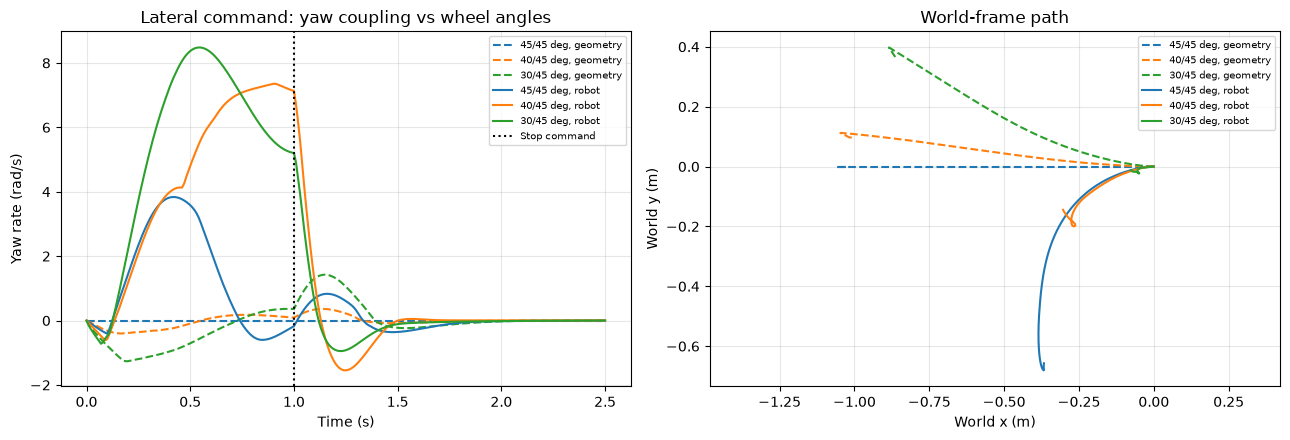

In [15]:
if RUN_PLANT_CHECKS:
    # Wheel-angle sweep (Dana's suggestion): the same lateral step with front/rear angles 45/45, 40/45, 30/45.
    # WHEEL_ALPHA_DEG = [front, 180 - front, 180 + rear, 360 - rear]; restored afterwards.
    # Run twice: "geometry" puts the CoG at P with equal loads, so only the wheel angles act (the
    # checks use it); "robot" uses the configured CoG and load model.
    ANGLE_SWEEP = [(45.0, 45.0), (40.0, 45.0), (30.0, 45.0)]  # (front, rear) [deg]
    nominal_alpha = list(rc.WHEEL_ALPHA_DEG)
    nominal_position = list(rc.WHEEL_POSITION_DEG)
    saved_cog = (rc.COG_OFFSET[0] * 1e3, rc.COG_OFFSET[1] * 1e3, rc.COG_HEIGHT * 1e3)
    sweep_results = {"geometry": {}, "robot": {}}
    try:
        for case in sweep_results:
            if case == "geometry":
                rc.set_center_of_gravity(0.0, 0.0, saved_cog[2])
            else:
                rc.set_center_of_gravity(*saved_cog)
            for front, rear in ANGLE_SWEEP:
                rc.WHEEL_ALPHA_DEG = [front, 180.0 - front, 180.0 + rear, 360.0 - rear]
                rc.WHEEL_POSITION_DEG = list(rc.WHEEL_ALPHA_DEG)  # tangential layout
                drive_sweep, _ = wheel_directions_body()
                result = run_open_loop_body_step(body_command(left=LATERAL_STEP_SPEED),
                                                 load_model="equal" if case == "geometry" else None)
                sweep_results[case][(front, rear)] = (result, float(drive_sweep[0].sum()))
    finally:
        rc.WHEEL_ALPHA_DEG = nominal_alpha
        rc.WHEEL_POSITION_DEG = nominal_position
        rc.set_center_of_gravity(*saved_cog)

    for case, label in (("geometry", "CoG at P, equal loads"),
                        ("robot", f"CoG {COG_POSITION_MM} mm, '{WHEEL_LOAD_MODEL}' loads")):
        print(f"{label}:")
        for (front, rear), (result, sum_dx) in sweep_results[case].items():
            yaw = result["velocity"][:, 2]
            print(f"  front {front:4.1f} deg / rear {rear:4.1f} deg: sum_i d_x,i = {sum_dx:+.3f}; "
                  f"peak |yaw rate| {np.max(np.abs(yaw)):.3f} rad/s; final heading {np.degrees(result['pose'][-1, 2]):+.2f} deg; "
                  f"peak leftward speed {np.max(-result['velocity'][:, RIGHT_AXIS]):.3f} m/s")
    symmetric = sweep_results["geometry"][(45.0, 45.0)][0]
    assert np.max(np.abs(symmetric["velocity"][:, 2])) < 1e-6, "45/45 layout should give no yaw for a lateral command"
    peaks = [np.max(np.abs(sweep_results["geometry"][key][0]["velocity"][:, 2])) for key in ANGLE_SWEEP]
    assert peaks[0] < peaks[1] < peaks[2], "Yaw coupling should grow as the front angle departs from the rear angle"
    print("PASS (CoG at P, equal loads): lateral yaw coupling is zero for 45/45 and grows as the front/rear angles differ. "
          "With the robot's CoG ahead of P, a sideways push at P also turns the robot, even at 45/45.")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for case, style in (("geometry", "--"), ("robot", "-")):
        for index, ((front, rear), (result, _)) in enumerate(sweep_results[case].items()):
            axes[0].plot(result["time"], result["velocity"][:, 2], f"C{index}" + style, label=f"{front:.0f}/{rear:.0f} deg, {case}")
            axes[1].plot(result["pose"][:, 0], result["pose"][:, 1], f"C{index}" + style, label=f"{front:.0f}/{rear:.0f} deg, {case}")
    axes[0].axvline(symmetric["step_duration_s"], linestyle=":", color="k", label="Stop command")
    axes[0].set(xlabel="Time (s)", ylabel="Yaw rate (rad/s)", title="Lateral command: yaw coupling vs wheel angles")
    axes[1].set(xlabel="World x (m)", ylabel="World y (m)", title="World-frame path")
    axes[1].axis("equal")
    for ax in axes:
        ax.grid(True, alpha=0.3); ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

### Open-loop drift with the friction disturbance (Dana's question)

The forward step and stop from section 4.2, run again with `disturbances=True` so the configuration switches apply. Each seed is one realisation of the disturbances (friction offset and load vibration). The ideal plant (disturbances off) is the reference. With the disturbance on, an open-loop forward command no longer travels exactly straight; the spread across seeds shows how much it drifts, which is what a closed-loop controller has to correct.

Disturbance switches: friction offset True, load vibration True
  ideal           : end x    -0.0 mm, y 1.508 m, heading  +0.00 deg; friction scale 1.000 to 1.000, load multiplier 1.000 to 1.000
  ideal, robot CoG: end x    +2.9 mm, y 1.517 m, heading  -2.70 deg; friction scale 1.000 to 1.000, load multiplier 1.000 to 1.000
  seed 1          : end x  +125.2 mm, y 1.511 m, heading -17.50 deg; friction scale 0.935 to 1.041, load multiplier 0.500 to 1.423
  seed 2          : end x    +4.3 mm, y 1.523 m, heading  +4.40 deg; friction scale 0.878 to 1.009, load multiplier 0.570 to 1.430
  seed 3          : end x   -70.7 mm, y 1.522 m, heading  -8.30 deg; friction scale 0.872 to 1.102, load multiplier 0.577 to 1.425
  seed 4          : end x   +12.5 mm, y 1.516 m, heading  +0.73 deg; friction scale 0.967 to 1.083, load multiplier 0.577 to 1.424
  seed 5          : end x   +19.5 mm, y 1.518 m, heading  -1.69 deg; friction scale 0.934 to 1.021, load multiplier 0.578 to 1.426


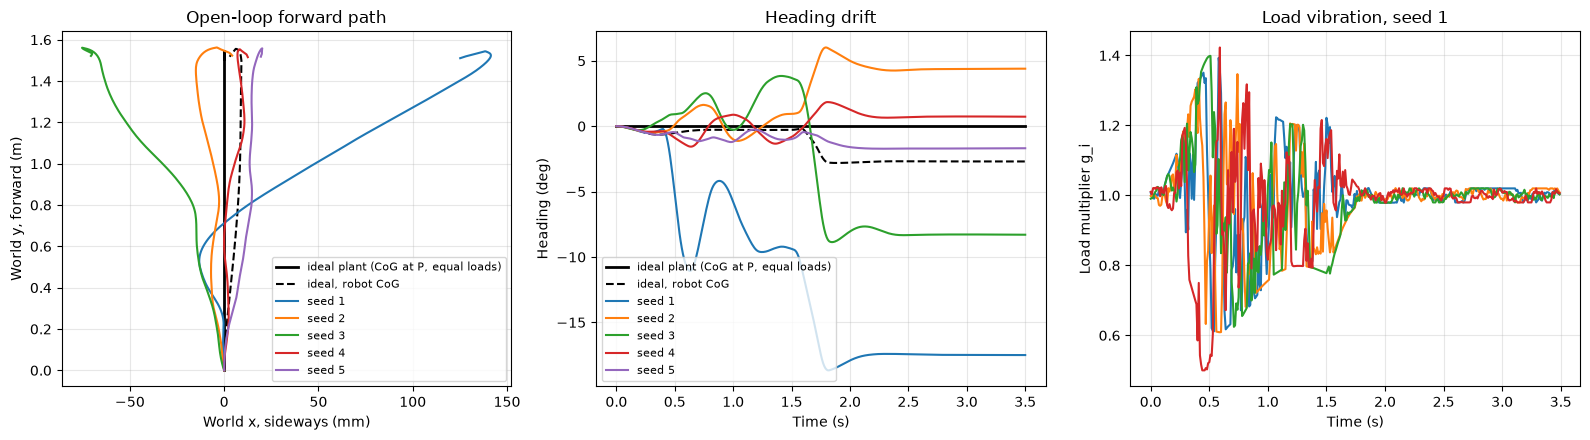

In [16]:
if RUN_PLANT_CHECKS:
    # Open-loop forward step and stop: ideal plant versus several disturbance seeds.
    DRIFT_SEEDS = (1, 2, 3, 4, 5)
    drift_command = lambda t: body_command(forward=TEST_FORWARD_SPEED) if t < 1.5 else body_command()
    print(f"Disturbance switches: friction offset {ENABLE_FRICTION_OFFSET}, load vibration {ENABLE_LOAD_VIBRATION}")
    # "ideal": no disturbance, CoG at P, equal loads, so it must drive straight. "ideal, robot CoG":
    # no disturbance but the configured CoG and load model, which turn and shift the robot slightly.
    with centred_cog():
        drift_runs = {"ideal": run_open_loop_schedule(drift_command, 3.5, disturbances=False, load_model="equal")}
    drift_runs["ideal, robot CoG"] = run_open_loop_schedule(drift_command, 3.5, disturbances=False)
    for seed in DRIFT_SEEDS:
        drift_runs[seed] = run_open_loop_schedule(drift_command, 3.5, disturbances=True, disturbance_seed=seed)
    for name, result in drift_runs.items():
        end = result["pose"][-1]
        friction = result["friction_scale"][:-1]
        load_scale = result["load_scale"][:-1]
        print(f"  {name if isinstance(name, str) else f'seed {name}':16s}: end x {end[0] * 1e3:+7.1f} mm, "
              f"y {end[1]:.3f} m, heading {np.degrees(end[2]):+6.2f} deg; "
              f"friction scale {friction.min():.3f} to {friction.max():.3f}, "
              f"load multiplier {load_scale.min():.3f} to {load_scale.max():.3f}")
    ideal = drift_runs["ideal"]
    assert abs(ideal["pose"][-1, 0]) < 1e-6 and abs(ideal["pose"][-1, 2]) < 1e-6, "Ideal plant should travel straight"

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    for name, result in drift_runs.items():
        if name == "ideal":
            style = dict(color="k", linewidth=2, label="ideal plant (CoG at P, equal loads)")
        elif isinstance(name, str):
            style = dict(color="k", linestyle="--", label=name)
        else:
            style = dict(label=f"seed {name}")
        axes[0].plot(result["pose"][:, 0] * 1e3, result["pose"][:, 1], **style)
        axes[1].plot(result["time"], np.degrees(result["pose"][:, 2]), **style)
    first = drift_runs[DRIFT_SEEDS[0]]
    axes[2].plot(first["time"][:-1], first["load_scale"][:-1])
    axes[0].set(xlabel="World x, sideways (mm)", ylabel="World y, forward (m)", title="Open-loop forward path")
    axes[1].set(xlabel="Time (s)", ylabel="Heading (deg)", title="Heading drift")
    axes[2].set(xlabel="Time (s)", ylabel="Load multiplier g_i", title=f"Load vibration, seed {DRIFT_SEEDS[0]}")
    axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
    for ax in axes:
        ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

## 4.5 Where the yaw comes from, and why it does not stop: model diagnosis

Dana's observation was that the yaw is a problem and the robot never stops spinning after the current drops. The cell below checks the equations first, then separates *what creates* yaw from *what fails to remove* it.

### The rolling d-force equation is correct

For a gripping wheel the contact force is whatever holds $\dot v_{d,i} = -k_g v_{d,i}$:
$$
F_{d,i} = \underbrace{-\tau_i/R_w}_{\text{motor + loss}} \;\underbrace{-\,(J_w/R_w^2)\,\mathbf H_i^T\dot{\mathbf q}}_{\text{wheel inertia}} \;\underbrace{-\,k_g v_{d,i}}_{\text{grip restoring}} .
$$
The check below is independent of that derivation. With the servo running and the robot moving, it compares $dE_{kin}/dt$ with motor power plus a-axis friction power plus d-axis sliding power. They agree to about $10^{-9}$, so the force, wheel-torque, and body equations are consistent. The signs are consistent too: contact power $F_{d,i}v_{d,i}$ is zero while gripping and negative while sliding.

### What creates the yaw: unequal d-forces from the wheel-speed servo

Every drive force has the same yaw lever, $\mathbf r_i\times\hat{\mathbf d}_i = +L$. The yaw moment is therefore $M_z = L\sum_i F_{d,i}$: **any set of four d-forces that does not sum to zero turns the robot.**

For a lateral command, inverse kinematics gives unequal wheel speeds, because the front wheels project $|d_x| = 0.5$ of the lateral velocity and the rear wheels $|d_x| = 0.707$ (targets −4.18, −4.18, +5.91, +5.91 rad/s). Each servo's current is proportional to its own speed error, so the forces have the same 0.5 : 0.707 ratio and do not cancel. At the first step, $\sum_i F_{d,i} = -0.29$ N and $M_z = -0.023$ N m. A moment-free lateral push needs equal-magnitude forces (`pinv(H)` gives ±0.414 N per 1 N of push), and independent wheel-speed servos do not produce that.

The plant amplifies this. Translation must first overcome the a-axis roller friction: $\sum_i\mu_{a}N|a_{x,i}|$ = 4.2 N (static) to 6.7 N (dynamic) for lateral motion. Because `K_SMOOTH_A` = 200 reaches most of that force at about 1 cm/s, the law behaves almost like Coulomb friction. Yaw, by contrast, has **zero** resistance (below), so for the first 0.2 s the robot spins up to −0.4 rad/s while moving sideways at only about 1 cm/s. The servo then sees the yaw as a common error on all four wheels and slowly removes it. The forward direction has no such problem: $\sum_i d_{y,i} = 0$, so the forward forces cancel in yaw exactly.

A second, much smaller source acts during a current-off coast. The inertia term $-(J_w/R_w^2)\,d_{x,i}\dot u$ is again proportional to each wheel's own $d_x$. As the roller friction stops a lateral slide, those forces sum to a net yaw moment, and the yaw rate *grows* during the coast ($M_{\mathrm{eff}}[u,\omega] = (J_w/R_w^2)L\sum_i d_{x,i} = 6.1\times10^{-4}$ kg m).

### Why the yaw did not stop with the wheel losses at zero

1. **Roller (a-axis) friction never acts on yaw.** The wheel position is defined along its own axle, $\mathbf r_i = L\,\hat{\mathbf a}_i$, so every a-axis force passes through the centre ($\mathbf r_i\times\hat{\mathbf a}_i = 0$), and pure spin produces zero a-axis slip. The a-axis law is the plant's main dissipation and it is blind to yaw. Translation stops after the current goes to zero; rotation does not.
2. **The d-axis contact does no work while gripping.** The Williams law dissipates only while a wheel slides, and $K_tI_{\max}/R_w$ = 4.43 N < $\mu_{d,\mathrm{stat}}N$ = 5.96 N, so the motors cannot make a wheel slide.
3. **No wheel losses.** `WHEEL_ROLLING_RESISTANCE_COEFF` and `WHEEL_BEARING_VISCOUS_DRAG` were 0. They now have assumed values (below).
4. **No motor torque at $I_q = 0$.** In current mode there is no back-EMF braking. With a speed command (sections 4.2–4.4), the servo actively brakes the wheels, which is why yaw does stop in Dana's tests.

With current and wheel losses at zero, the yaw subsystem is exactly conservative: the kinetic energy stays constant.

### Voltage mode: back-EMF braking

With the voltage-driven motor, releasing the motors by $V_m = 0$ shorts the windings. The back-EMF then brakes every wheel with $-(K_tK_e/R)\dot\theta_i$. Through the rolling constraint, that becomes a yaw damping with time constant $I_{\mathrm{eff}} / (4K_tK_e/R\,(L/R_w)^2) \approx 0.1$ s. Releasing by holding $i = 0$ ($V_m = K_e\dot\theta$) cancels the back-EMF, so only the wheel losses act, exactly as in the current-input plant with $I_q = 0$. This is the motor term in the models of Kalmár-Nagy et al. ($f = \alpha U - \beta v$) and the SJTU four-wheel model ($k_2k_3/R_a$).

### Friction on the wheel

Three different friction effects act on a wheel:

1. **Ground contact friction in d (static, while gripping).** This *is* the load force $F_{\mathrm{required}}$. It does act while the wheel slows down. When back-EMF brakes the wheel, the ground pushes on it to keep it rolling, and that same force decelerates the chassis. It transmits the braking; it dissipates nothing, because the contact does not slip ($F_d v_d = 0$). With no torque on the wheel there is nothing to transmit, so it is zero.
2. **Rolling resistance of the X-rings** (hysteresis of the deforming contact): a real loss, $\tau = -C_{rr}N_iR_w\,\mathrm{sign}(\dot\theta_i)$.
3. **Bearing and drive friction** inside the wheel and motor: a real loss, $\tau = -b_w\dot\theta_i$ (plus any Coulomb part).

Items 2 and 3 are in `wheel_loss_torque()`, and they are separate parameters from `MU_D_*` and `MU_A_*`. Those coefficients set the force limit and the force once a contact *slides*; rolling resistance and bearing drag act while the contact *rolls*. Neither can be measured on this project, so both are estimated:
- $C_{rr} = 0.025$, switched by `INCLUDE_ESTIMATED_ROLLING_RESISTANCE` in the configuration cell. Duda et al. (2025) measured a 125 mm polyurethane-roller omniwheel on hard floors: 0.008–0.010 rolling in the drive direction, and 0.044–0.047 rolling along the axle (rollers turning). Scaling for our 60 mm wheel and carpet gives about 0.025. Applying their drive/axle ratio (about 0.2) to our measured $\mu_{a,\mathrm{stat}}$ of 0.1–0.2 gives 0.02–0.04. $\mu_{a,\mathrm{stat}}$ is an upper bound, because it also contains roller-bushing friction.
- $b_w = 2\times10^{-4}$ N m s/rad: the same value as `WHEEL_VISCOUS_DRAG_NM_S_RAD` in Dana's `robot22102026D.ipynb`.

For scale, Conceição et al. (2008) identified rotational friction on a 2.34 kg four-wheel omni robot with a 5:1 gearbox, equivalent to $b_w \approx 4.7\times10^{-4}$ and $C_{rr} \approx 0.07$. With these values, a free yaw coast decelerates at $4LC_{rr}N/I_{\mathrm{eff}} \approx 6.4$ rad/s² plus $0.69\,\omega$ per second, and stops from 3 rad/s in roughly 0.5 s (the cell below prints the simulated time). That holds in both motor models; shorting the windings ($V_m = 0$) roughly halves it.

**Comparison with Dana's plant.** With her motor torque forced to zero and her `WHEEL_VISCOUS_DRAG` set to 0, her robot also coasts: 3.000 → 2.999 rad/s after 2 s. The rolling slip there is about $2\times10^{-6}$ m/s, so her slip-based contact force is about zero too. Her default model brakes because of that drag term, which is the same physics as $b_w$ here. With her transverse friction switched on, her robot does stop from contact friction alone. That happens because her wheel positions are on a ±45° grid while her front rolling directions are at 30°, so her front axles do not point at the centre and pure yaw scrubs them sideways (0.058 m/s per rad/s). In this notebook each wheel sits on its own axle line (radial axles), so pure yaw has no scrub. Which layout matches the robot is a CAD question.

If hardware becomes available, a yaw coast-down at zero current would replace both assumptions: a linear decay of $\omega$ indicates $C_{rr}$, an exponential decay indicates $b_w$.

Moment arm of a-axis (roller) force, r_i x a_i [m]: [0. 0. 0. 0.]
Moment arm of d-axis (drive) force,  r_i x d_i [m]: [0.079485 0.079485 0.079485 0.079485]
a-axis slip for pure yaw at 7.0 rad/s [m/s]: [ 2.77555756e-17 -2.77555756e-17  0.00000000e+00  0.00000000e+00]
sum of drive directions sum_i d_i: [ 4.14213562e-01 -4.44089210e-16]
wheel-inertia coupling M_eff[u, omega] = -2.693e-02 kg m (M_eff[omega, omega] = 8.194e-03 kg m^2)
motor-only drive force K_t*I_max/R_w = 4.43 N; static grip at rest MU_D_STAT*N_i = [8.31 8.18 3.62 3.72] N ('quasi_static' loads, CoG (0.597, 10.206, 61.146) mm): ['back-left', 'back-right'] can slide in d at full current
Lateral servo, first step: currents [-1.83856712 -1.83856712  2.60012656  2.60012656] A -> F_d [ 1.64060417  1.64097396 -2.25047426 -2.25077619] N; sum F_d = -1.220 N, yaw moment about P, sum_i (r_i x d_i) F_d,i = -0.0969 N m
PASS energy balance over 1 s of the lateral servo test: worst relative error 4.9e-08
Moment-free allocation for a 1 N 

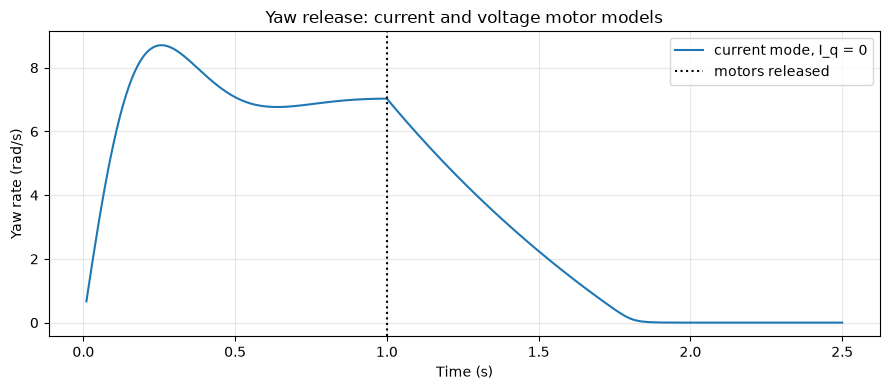

In [17]:
if RUN_PLANT_CHECKS:
    # Yaw diagnosis: which plant terms can create or remove a yaw moment.
    drive, axle = wheel_directions_body()
    radius = wheel_positions_body()
    axial_moment_arm = radius[0] * axle[1] - radius[1] * axle[0]
    drive_moment_arm = radius[0] * drive[1] - radius[1] * drive[0]
    print("Moment arm of a-axis (roller) force, r_i x a_i [m]:", axial_moment_arm)
    print("Moment arm of d-axis (drive) force,  r_i x d_i [m]:", drive_moment_arm)
    pure_yaw_rate = TEST_YAW_RATE
    _, pure_yaw_slip_a = wheel_slip_velocities(
        np.zeros(2), pure_yaw_rate, inverse_kinematics(body_command(yaw_rate=pure_yaw_rate)))
    print(f"a-axis slip for pure yaw at {pure_yaw_rate} rad/s [m/s]:", pure_yaw_slip_a)

    probe = WheelSlipRobotSimulator(dt=DT, initial_state=np.zeros(10))
    effective_mass = probe.body_mass + (rc.WHEEL_INERTIA / rc.WHEEL_RADIUS**2) * (probe.H @ probe.H.T)
    print("sum of drive directions sum_i d_i:", drive.sum(axis=1))
    print(f"wheel-inertia coupling M_eff[u, omega] = {effective_mass[0, 2]:.3e} kg m "
          f"(M_eff[omega, omega] = {effective_mass[2, 2]:.3e} kg m^2)")
    motor_force = rc.MOTOR_KT * rc.IQ_LIMIT / rc.WHEEL_RADIUS
    static_caps = rc.MU_D_STAT * probe.static_loads
    can_slide = [rc.WHEEL_NAMES[i] for i in np.flatnonzero(static_caps < motor_force)]
    print(f"motor-only drive force K_t*I_max/R_w = {motor_force:.2f} N; static grip at rest MU_D_STAT*N_i = "
          f"{np.round(static_caps, 2)} N ('{probe.load_model}' loads, CoG {COG_POSITION_MM} mm): "
          + (f"{can_slide} can slide in d at full current" if can_slide else "no wheel can slide in d from the motor alone"))


    # Independent check of the current-mode equations: dE_kin/dt must equal motor power + wheel-loss
    # power + a-axis friction power + d-axis sliding power (F_d * v_d, zero while gripping) at every instant.
    def kinetic_energy(state):
        return (chassis_kinetic_energy(state, energy_sim.plant)
                + 0.5 * rc.WHEEL_INERTIA * float(state[6:10] @ state[6:10]))

    energy_sim = OpenLoopPlant(motor_mode="current")
    lateral_targets = inverse_kinematics(body_command(left=TEST_LATERAL_SPEED))
    worst_energy_error = 0.0
    for k in range(int(round(1.0 / SIM_DT_S))):
        state0 = energy_sim.state.copy()
        current = energy_sim._servo_command(lateral_targets)
        _, _, force_d, force_a, slip_d, slip_a, *_ = energy_sim.plant._contact_wrenches(state0, current, np.zeros(3))
        if k == 0:
            print(f"Lateral servo, first step: currents {current} A -> F_d {force_d} N; "
                  f"sum F_d = {force_d.sum():+.3f} N, yaw moment about P, sum_i (r_i x d_i) F_d,i = {energy_sim.plant.H[2] @ force_d:+.4f} N m")
        loads = energy_sim.plant._force_selection_diagnostics["normal_loads"]
        loss_power = wheel_loss_torque(state0[6:10], loads) @ state0[6:10]
        # The plant limits the servo's request; the power uses the current the motor delivers.
        power = rc.MOTOR_KT * energy_sim.plant.saturate_current(state0, current) @ state0[6:10] + loss_power + force_a @ slip_a + force_d @ slip_d
        derivative = energy_sim.plant.physical_dynamics(state0, current, np.zeros(3))[0]
        eps = 1e-7
        energy_rate = (kinetic_energy(state0 + eps * derivative) - kinetic_energy(state0 - eps * derivative)) / (2 * eps)
        worst_energy_error = max(worst_energy_error, abs(energy_rate - power) / max(abs(power), 1e-9))
        energy_sim.state = energy_sim.plant.discrete_map(state0, current, np.zeros(3))
    assert worst_energy_error < 1e-6, f"Energy balance violated: relative error {worst_energy_error:.2e}"
    print(f"PASS energy balance over 1 s of the lateral servo test: worst relative error {worst_energy_error:.1e}")
    moment_free = np.linalg.pinv(probe.H) @ np.array([-1.0, 0.0, 0.0])
    print(f"Moment-free allocation for a 1 N left push, pinv(H): {moment_free} N (sum {moment_free.sum():+.1e})")

    # Yaw release: spin up to 3 rad/s through the servo, then set I_q = 0 (the voltage-driven release
    # cases, including back-EMF braking with V_m = 0, are in robot_model_voltage.ipynb).
    #   current mode, I_q = 0         : no motor torque; only the wheel losses act.
    #   voltage mode, i = 0 hold      : V_m = K_e*theta_dot cancels the back-EMF; same as I_q = 0.
    #   voltage mode, V_m = 0 (short) : back-EMF drives a braking current, on top of the losses.
    RELEASES = [("current", "zero_current", "current mode, I_q = 0")]

    def run_release(motor_mode, release, spin_rate=TEST_YAW_RATE, spin_s=1.0, coast_s=1.5):
        sim = OpenLoopPlant(motor_mode=motor_mode)
        target = inverse_kinematics(body_command(yaw_rate=spin_rate))
        times, omega = [], []
        for k in range(int(round((spin_s + coast_s) / SIM_DT_S))):
            if k * SIM_DT_S < spin_s:
                sim.step(target)
            else:
                if motor_mode == "current":
                    command = np.zeros(N_WHEELS)
                elif release == "short":
                    command = np.zeros(N_WHEELS)
                else:
                    command = rc.MOTOR_KT * sim.state[6:10]
                sim.state = sim.plant.discrete_map(sim.state, command, np.zeros(3))
            times.append((k + 1) * SIM_DT_S); omega.append(sim.state[5])
        return np.array(times), np.array(omega), spin_s

    # Prediction for a free coast with the wheel losses alone (rolling constraint, pure yaw about P).
    # With l_i = r_i x d_i the yaw lever of wheel i and N_i its load:
    #   I_eff domega/dt = -C_rr sum_i |l_i| N_i - b_w sum_i (l_i/R_w)^2 omega
    # Approximate when the CoG is off P, because the spin then also moves P.
    yaw_levers = probe.H[2]
    loss_coulomb_decel = rc.WHEEL_ROLLING_RESISTANCE_COEFF * np.sum(np.abs(yaw_levers) * probe.normal_loads) / effective_mass[2, 2]
    loss_viscous_rate = rc.WHEEL_BEARING_VISCOUS_DRAG * np.sum((yaw_levers / rc.WHEEL_RADIUS) ** 2) / effective_mass[2, 2]
    print(f"Wheel losses: C_rr = {rc.WHEEL_ROLLING_RESISTANCE_COEFF}, b_w = {rc.WHEEL_BEARING_VISCOUS_DRAG} N m s/rad "
          f"-> yaw deceleration {loss_coulomb_decel:.2f} rad/s^2 + {loss_viscous_rate:.2f}/s * omega "
          "(with both at 0 a free coast conserves kinetic energy exactly)")

    release_runs = {}
    for motor_mode, release, label in RELEASES:
        tt, omega, spin_s = run_release(motor_mode, release)
        release_runs[label] = (tt, omega)
        k_rel = int(round(spin_s / SIM_DT_S)) - 1
        stopped = np.flatnonzero(np.abs(omega[k_rel:]) < 0.01)
        stop_text = f"{(tt[k_rel + stopped[0]] - spin_s) * 1e3:.0f} ms" if stopped.size else "not within 1.5 s"
        print(f"  {label:30s}: omega {omega[k_rel]:.3f} rad/s at release, below 0.01 rad/s after {stop_text}")
    if loss_coulomb_decel > 0 or loss_viscous_rate > 0:
        omega0 = release_runs[RELEASES[0][2]][1][int(round(1.0 / SIM_DT_S)) - 1]
        if loss_viscous_rate > 0:
            predicted_stop = np.log(1 + loss_viscous_rate * omega0 / loss_coulomb_decel) / loss_viscous_rate if loss_coulomb_decel > 0 else np.inf
        else:
            predicted_stop = omega0 / loss_coulomb_decel
        print(f"  predicted free-coast stop time from the loss terms alone: {predicted_stop * 1e3:.0f} ms "
              "(the tanh smoothing of C_rr lengthens the last few rad/s)")

    fig, ax = plt.subplots(figsize=(9, 4))
    for label, (tt, omega) in release_runs.items():
        ax.plot(tt, omega, label=label)
    ax.axvline(1.0, linestyle=":", color="k", label="motors released")
    ax.set_xlabel("Time (s)"); ax.set_ylabel("Yaw rate (rad/s)"); ax.set_title("Yaw release: current and voltage motor models")
    ax.grid(True, alpha=0.3); ax.legend(); plt.tight_layout(); plt.show()
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

## 4.6 Wheel loads from the centre of gravity

`WHEEL_LOAD_MODEL` (configuration cell) selects the wheel normal loads $N_i$. They set each wheel's grip limit $\mu_{d,s}N_i$, its friction forces, and its rolling resistance, so the least-loaded wheel slips first. `COG_POSITION_MM` places the centre of gravity. By default it is the real robot's (CAD): (0.597, 10.206, 61.146) mm from the robot centre $P$, 10.2 mm toward the front. `(0, 0, h)` centres it (Dana's simplification).

**Contact points.** Wheel $i$ touches the floor at $\mathbf p_i = L(\cos\beta_i,\ \sin\beta_i)$, with $L$ = `WHEEL_ROBOT_DIST` = 79.485 mm and $\beta$ = `WHEEL_POSITION_DEG` (equal to `WHEEL_ALPHA_DEG` for tangential wheels):

| wheel | $\beta_i$ | $x_i$ (mm) | $y_i$ (mm) |
|---|---|---|---|
| front-right | 30° | +68.84 | +39.74 |
| front-left | 150° | −68.84 | +39.74 |
| back-left | 225° | −56.20 | −56.20 |
| back-right | 315° | +56.20 | −56.20 |

The front wheels sit 39.74 mm ahead of $P$ and the rear wheels 56.20 mm behind it, so the layout is not symmetric front to back.

**Balance at rest.** Let $\mathbf r_i = \mathbf p_i - \mathbf c$ be the contact point measured from the CoG. The chassis is in equilibrium when

$$
\sum_i N_i = mg,\qquad \sum_i N_i\,r_{y,i} = 0\ \text{(pitch)},\qquad \sum_i N_i\,r_{x,i} = 0\ \text{(roll)}.
$$

Both front wheels share $y_f = +39.74$ mm and both rear wheels share $y_r = -56.20$ mm. The pitch balance therefore involves only the front total $N_F$ and the rear total $N_R$, like a beam on two supports:

$$
N_F\,(y_f - c_y) + N_R\,(y_r - c_y) = 0,\quad N_F + N_R = mg
\;\;\Rightarrow\;\;
N_F = mg\,\frac{c_y - y_r}{y_f - y_r},\qquad N_R = mg\,\frac{y_f - c_y}{y_f - y_r}.
$$

| CoG $c_y$ | $N_F/mg$ | per front wheel | per rear wheel |
|---|---|---|---|
| CAD, 10.206 mm | 66.41 / 95.94 = 69.2% | 9.16 N | 4.07 N |
| centred, 0 mm | 56.20 / 95.94 = 58.6% | 7.75 N | 5.48 N |
| midway between the contact lines, −8.23 mm | 50% | 6.62 N | 6.62 N |

The split is even only when the CoG sits midway between the front and rear contact lines. A centred CoG is already 8.2 mm ahead of that midpoint, and the CAD CoG is 18.4 mm ahead. The total, $mg$ = 26.47 N, does not change. The front/rear split needs only statics.

Four wheels and three equations leave the split *within* a pair (left vs right) undetermined. `"static"` closes it by treating the chassis as a rigid plane on four equal contact springs, so $N_i = c_0 + c_1x_i + c_2y_i$. With $c_x$ = 0.6 mm that split is small (9.23 vs 9.09 N).

**Consequence.** A motor can push $K_tI_{\max}/R_w$ = 4.43 N. At rest, a rear wheel grips up to $\mu_{d,s}N_R/2$:
- centred CoG: 0.9 × 5.48 = 4.93 N, just enough;
- CAD CoG: 0.9 × 4.07 = 3.66 N, so a rear wheel can slip at full current.

With equal loads, every wheel grips up to 5.96 N.

**Load transfer (`"quasi_static"`).** When the robot accelerates, the horizontal contact force $\mathbf F$ acts at the floor, $h$ = `COG_HEIGHT` below the CoG. The moment balances become $\sum_i N_i r_{y,i} = -hF_y$ and $\sum_i N_i r_{x,i} = -hF_x$, so accelerating forward moves load from the front wheels to the rear ones. The loads and the contact forces depend on each other. The plant breaks that loop with a one-step lag: each step's loads come from the contact force at the end of the previous step (DT = 10 ms) and are held over the step. A load that would go negative is set to zero (wheel lifted).

**Mass matrix.** The CoG offset also couples translation and yaw: $M_b$ (section 4) has the off-diagonal terms $-mc_y$ and $mc_x$. With the friction off, a spinning robot's CoG must move in a straight line while $P$ circles it at radius $|\mathbf c|$.

Contact points from P [mm]:
  front-right  x =  +68.84  y =  +39.74
  front-left   x =  -68.84  y =  +39.74
  back-left    x =  -56.20  y =  -56.20
  back-right   x =  +56.20  y =  -56.20
CoG from P [mm]: [ 0.597 10.206 61.146]
Hand calculation: N_F = m g (c_y - y_r)/(y_f - y_r) = 26.467 x (10.206 + 56.204) / 95.947 = 18.320 N, N_R = 8.148 N
  equal        N = [6.617 6.617 6.617 6.617] N; front 13.234 N, rear 13.234 N, sum 26.467 N
  static       N = [9.229 9.091 4.018 4.13 ] N; front 18.320 N, rear 8.148 N, sum 26.467 N
  quasi_static N = [9.229 9.091 4.018 4.13 ] N; front 18.320 N, rear 8.148 N, sum 26.467 N
CoG centred at P:                     N = [7.752 7.752 5.482 5.482] N
CoG midway between the contact lines: N = [6.617 6.617 6.617 6.617] N
CoG at the real (CAD) position:       N = [9.229 9.091 4.018 4.13 ] N
PASS load transfer: force and moment balances hold to 2.5e-14 (500 random forces)
PASS free spin (friction off): CoG on a straight line to 4.1e-14 m while P circles it at 1

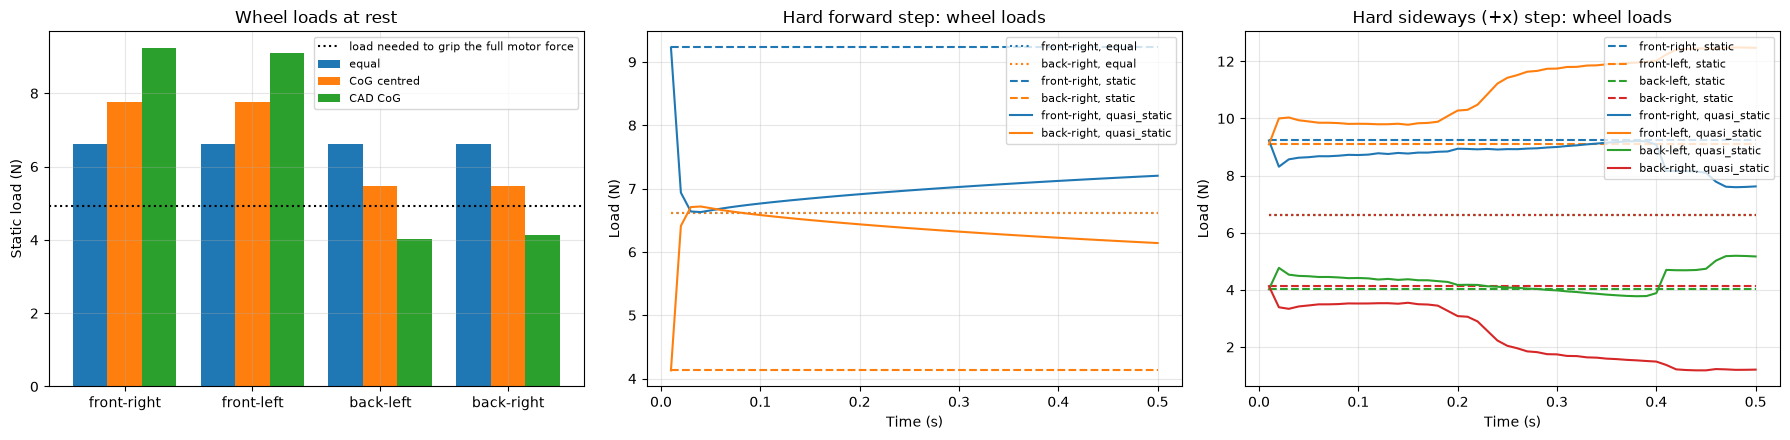

In [18]:
if RUN_PLANT_CHECKS:
    # 4.6 Wheel loads from the centre of gravity: hand calculation vs the plant, and the effect on slip.
    LOAD_MODELS = ("equal", "static", "quasi_static")
    load_probe = OpenLoopPlant(load_model="static").plant
    weight = rc.ROBOT_MASS * rc.GRAVITY
    contact = load_probe.positions
    print("Contact points from P [mm]:")
    for name, (x, y) in zip(rc.WHEEL_NAMES, contact.T * 1e3):
        print(f"  {name:12s} x = {x:+7.2f}  y = {y:+7.2f}")
    print(f"CoG from P [mm]: {np.round(np.r_[load_probe.cog_offset, load_probe.cog_height] * 1e3, 3)}")

    # 1. Hand calculation of the front/rear split (beam on two supports) vs the plant.
    y_front, y_rear = contact[1, 0], contact[1, 2]
    # The two-support hand calculation needs each pair (front, rear) to share one y.
    paired = np.isclose(contact[1, 0], contact[1, 1]) and np.isclose(contact[1, 2], contact[1, 3])
    c_y = load_probe.cog_offset[1]
    front_total = weight * (c_y - y_rear) / (y_front - y_rear)
    print(f"Hand calculation: N_F = m g (c_y - y_r)/(y_f - y_r) = {weight:.3f} x ({c_y * 1e3:.3f} + {-y_rear * 1e3:.3f})"
          f" / {(y_front - y_rear) * 1e3:.3f} = {front_total:.3f} N, N_R = {weight - front_total:.3f} N")
    for model in LOAD_MODELS:
        loads = OpenLoopPlant(load_model=model).plant.normal_loads
        print(f"  {model:12s} N = {np.round(loads, 3)} N; front {loads[:2].sum():.3f} N, "
              f"rear {loads[2:].sum():.3f} N, sum {loads.sum():.3f} N")
    if paired:
        assert np.isclose(load_probe.static_loads[:2].sum(), front_total, atol=1e-9), "Plant front load differs from the hand calculation"
    else:
        print("Front or rear pair at different y: the two-support hand calculation does not apply.")
    assert np.isclose(load_probe.static_loads.sum(), weight, atol=1e-9)

    # 2. Moving the CoG midway between the front and rear contact lines must equalise all four loads.
    saved_cog = (load_probe.cog_offset * 1e3).tolist() + [load_probe.cog_height * 1e3]
    try:
        rc.set_center_of_gravity(0.0, 0.5 * (y_front + y_rear) * 1e3, saved_cog[2])
        midway_loads = OpenLoopPlant(load_model="static").plant.normal_loads
        rc.set_center_of_gravity(0.0, 0.0, saved_cog[2])
        centred_loads = OpenLoopPlant(load_model="static").plant.normal_loads
        rc.set_center_of_gravity(rc.COG_X_MM, rc.COG_Y_MM, rc.COG_Z_MM)
        cad_loads = OpenLoopPlant(load_model="static").plant.normal_loads
    finally:
        rc.set_center_of_gravity(*saved_cog)
    print(f"CoG centred at P:                     N = {np.round(centred_loads, 3)} N")
    print(f"CoG midway between the contact lines: N = {np.round(midway_loads, 3)} N")
    print(f"CoG at the real (CAD) position:       N = {np.round(cad_loads, 3)} N")
    if paired:
        assert np.allclose(midway_loads, weight / 4, atol=1e-9), "A CoG midway between the contact lines must load all wheels equally"

    # 3. Load-transfer balance: random horizontal forces; all three balances must hold
    #    whenever at least three wheels stay on the ground.
    rng = np.random.default_rng(0)
    rx_cog, ry_cog = load_probe.contact_from_cog
    worst_balance = 0.0
    for force in rng.normal(scale=8.0, size=(500, 2)):
        loads = load_probe.quasi_static_loads(force)
        assert np.all(loads >= 0.0)
        if np.count_nonzero(loads) >= 3:
            worst_balance = max(worst_balance, abs(loads.sum() - weight),
                                abs(loads @ ry_cog + load_probe.cog_height * force[1]),
                                abs(loads @ rx_cog + load_probe.cog_height * force[0]))
    assert worst_balance < 1e-9, f"Load-transfer balance violated: {worst_balance:.2e}"
    print(f"PASS load transfer: force and moment balances hold to {worst_balance:.1e} (500 random forces)")

    # 4. Full mass matrix: free spin with the friction off. No horizontal force acts, so the
    #    CoG must move in a straight line at constant velocity while P circles it.
    spin = OpenLoopPlant(enable_friction=False)
    spin.state[5] = 3.0
    cog = spin.plant.cog_offset
    def cog_world(state):
        return state[:2] + body_to_world(cog, state[2])
    cog_velocity0 = spin.state[3:5] + spin.state[5] * body_to_world(np.array([-cog[1], cog[0]]), spin.state[2])
    cog0 = cog_world(spin.state)
    cog_error, p_excursion = 0.0, 0.0
    for k in range(int(round(1.0 / SIM_DT_S))):
        spin.state = spin.plant.discrete_map(spin.state, np.zeros(N_WHEELS), np.zeros(3))
        t = (k + 1) * SIM_DT_S
        cog_error = max(cog_error, np.linalg.norm(cog_world(spin.state) - cog0 - cog_velocity0 * t))
        p_excursion = max(p_excursion, np.linalg.norm(spin.state[:2] - cog0 - cog_velocity0 * t))
    assert cog_error < 1e-6, f"CoG left its straight line: {cog_error:.2e} m"
    print(f"PASS free spin (friction off): CoG on a straight line to {cog_error:.1e} m while P circles it "
          f"at {p_excursion * 1e3:.2f} mm (|c| = {np.linalg.norm(cog) * 1e3:.2f} mm)")

    # 5. Grip at rest vs the motor's maximum drive force.
    motor_force = rc.MOTOR_KT * rc.IQ_LIMIT / rc.WHEEL_RADIUS
    print(f"Grip at rest, mu_d,s N_i = {np.round(rc.MU_D_STAT * load_probe.static_loads, 2)} N vs motor force "
          f"K_t I_max / R_w = {motor_force:.2f} N")

    # 6. Hard forward step (3 m/s request, motors at the current limit) in each load model.
    hard = {model: run_open_loop_schedule(lambda t: body_command(forward=3.0), 0.5, load_model=model)
            for model in LOAD_MODELS}
    print("Hard forward step, first 0.5 s:")
    for model, log in hard.items():
        accel = np.gradient(log["body_velocity"][:, FORWARD_AXIS], log["time"])
        ratio = np.abs(log["ground_forces"][1:]) / np.maximum(log["friction_limits"][1:], 1e-12)
        sliding = ~log["rolling"][1:]
        print(f"  {model:12s} peak a = {accel[1:].max():.2f} m/s^2, speed at 0.5 s {log['body_velocity'][-1, FORWARD_AXIS]:.2f} m/s, "
              f"loads at 0.25 s {np.round(log['normal_loads'][25], 2)} N, max |F_d|/(mu N) = {ratio.max():.2f}, "
              f"sliding samples per wheel {sliding.sum(axis=0)}")

    # 7. Hard sideways step to the right (+x, 3 m/s request), the case where the real robot slips.
    #    Each wheel's drive direction has a different x component (front 0.5, rear 0.707), so the
    #    wheels share the push unequally on top of the unequal loads.
    side = {model: run_open_loop_schedule(lambda t: body_command(left=-3.0), 0.5, load_model=model)
            for model in LOAD_MODELS}
    print("Hard sideways (+x) step, first 0.5 s:")
    for model, log in side.items():
        accel = np.gradient(log["body_velocity"][:, RIGHT_AXIS], log["time"])
        ratio = np.abs(log["ground_forces"][1:]) / np.maximum(log["friction_limits"][1:], 1e-12)
        sliding = ~log["rolling"][1:]
        print(f"  {model:12s} peak a = {accel[1:].max():.2f} m/s^2, speed at 0.5 s {log['body_velocity'][-1, RIGHT_AXIS]:.2f} m/s, "
              f"peak yaw rate {np.abs(log['body_velocity'][:, 2]).max():.2f} rad/s, loads at 0.25 s {np.round(log['normal_loads'][25], 2)} N, "
              f"max |F_d|/(mu N) = {ratio.max():.2f}, sliding samples per wheel {sliding.sum(axis=0)}")

    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    positions = np.arange(N_WHEELS)
    for offset, (label, loads) in zip((-0.27, 0.0, 0.27), (("equal", np.full(N_WHEELS, weight / 4)),
                                                             ("CoG centred", centred_loads),
                                                             ("CAD CoG", cad_loads))):
        axes[0].bar(positions + offset, loads, width=0.27, label=label)
    axes[0].axhline(motor_force / rc.MU_D_STAT, color="k", linestyle=":", label="load needed to grip the full motor force")
    axes[0].set_xticks(positions, rc.WHEEL_NAMES)
    axes[0].set(ylabel="Static load (N)", title="Wheel loads at rest")
    for model, style in zip(LOAD_MODELS, (":", "--", "-")):
        log = hard[model]
        axes[1].plot(log["time"][1:], log["normal_loads"][1:, 0], "C0" + style, label=f"front-right, {model}")
        axes[1].plot(log["time"][1:], log["normal_loads"][1:, 3], "C1" + style, label=f"back-right, {model}")
    axes[1].set(xlabel="Time (s)", ylabel="Load (N)", title="Hard forward step: wheel loads")
    for model, style in zip(LOAD_MODELS, (":", "--", "-")):
        log = side[model]
        for wheel in range(N_WHEELS):
            axes[2].plot(log["time"][1:], log["normal_loads"][1:, wheel], f"C{wheel}" + style,
                         label=f"{rc.WHEEL_NAMES[wheel]}, {model}" if model != "equal" else None)
    axes[2].set(xlabel="Time (s)", ylabel="Load (N)", title="Hard sideways (+x) step: wheel loads")
    for ax in axes:
        ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

## 4.7 Non-tangential wheels

`WHEEL_POSITION_DEG` (where a wheel sits) and `WHEEL_ALPHA_DEG` (which way it points) are separate constants. When they differ, the wheel's drive direction is no longer tangent to the circle:

- its drive yaw lever $\mathbf r_i\times\mathbf d_i$ is no longer $L$, so a translation command produces a yaw moment from the drive forces (crosstalk);
- its roller lever $\mathbf r_i\times\mathbf a_i$ is no longer zero, so a pure spin scrubs the rollers sideways and the roller friction resists yaw.

Example: the wheels stay at 30/150/225/315° but the front wheels are turned to point like 45° wheels (alpha 45/135/225/315°). The checks:
1. Inverse then forward kinematics returns the commanded twist; the plant's $H$ uses the same levers.
2. Open-loop forward, left and yaw commands (CoG at $P$, equal loads, so only the layout acts). While every wheel grips, the chassis twist must equal the forward kinematics of the wheel speeds: the plant's rolling constraint (through $H$) and the kinematics (through the wheel positions) must use the same geometry. How close the wheel-speed servo gets to the command is printed for information.
3. The same commands with the tangential layout, for comparison.

tangential: position [30.0, 150.0, 225.0, 315.0] deg, alpha [30.0, 150.0, 225.0, 315.0] deg
  front-right  r = [+0.0688, +0.0397] m, d = [-0.500, +0.866], drive lever r x d = +0.0795 m, roller lever r x a = +0.0000 m
  front-left   r = [-0.0688, +0.0397] m, d = [-0.500, -0.866], drive lever r x d = +0.0795 m, roller lever r x a = +0.0000 m
  back-left    r = [-0.0562, -0.0562] m, d = [+0.707, -0.707], drive lever r x d = +0.0795 m, roller lever r x a = +0.0000 m
  back-right   r = [+0.0562, -0.0562] m, d = [+0.707, +0.707], drive lever r x d = +0.0795 m, roller lever r x a = +0.0000 m
  forward 1.0 m/s : final twist [u, v, omega] = [-0.      1.0416  0.    ] vs command [-0.  1.  0.] (servo error 4.2%); |twist - FK(wheel speeds)| while gripping 1.5e-10; sliding samples per wheel [0 0 0 0]
  left 1.0 m/s    : final twist [u, v, omega] = [-0.9206 -0.0439 -0.1228] vs command [-1.  0.  0.] (servo error 15.3%); |twist - FK(wheel speeds)| while gripping 2.4e-10; sliding samples per wheel [0 0 

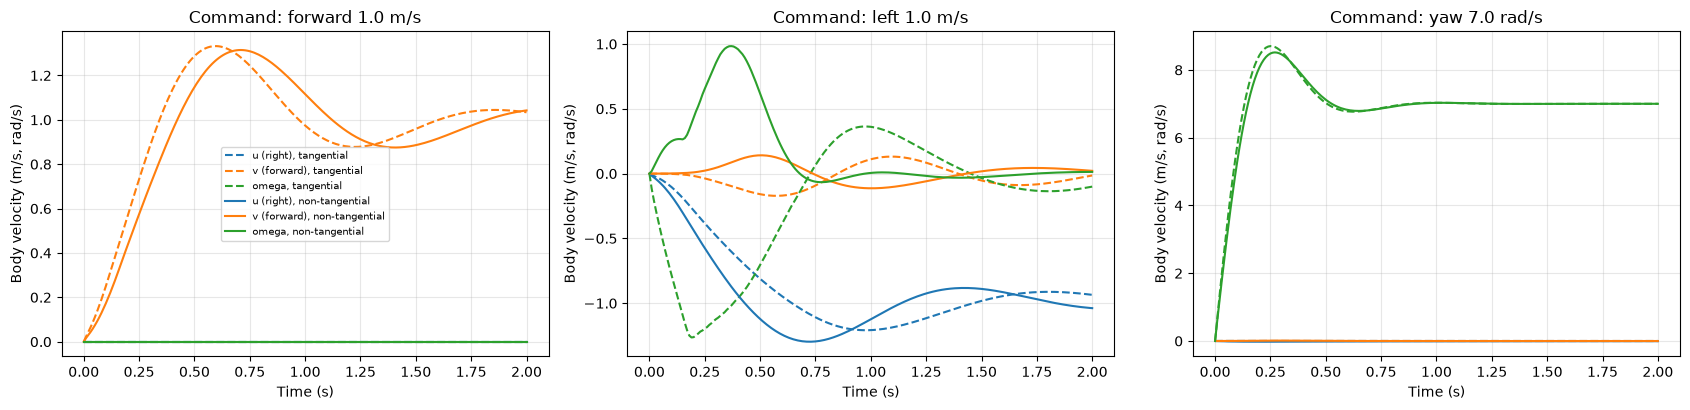

In [19]:
if RUN_PLANT_CHECKS:
    # 4.7 Non-tangential wheels: the same geometry functions, matrices, and kinematics for any layout.
    TOE_LAYOUT = {"position": [30.0, 150.0, 225.0, 315.0], "alpha": [45.0, 135.0, 225.0, 315.0]}
    TOE_COMMANDS = [(f"forward {TEST_FORWARD_SPEED} m/s", body_command(forward=TEST_FORWARD_SPEED)),
                    (f"left {TEST_LATERAL_SPEED} m/s", body_command(left=TEST_LATERAL_SPEED)),
                    (f"yaw {TEST_YAW_RATE} rad/s", body_command(yaw_rate=TEST_YAW_RATE))]
    saved_layout = (list(rc.WHEEL_POSITION_DEG), list(rc.WHEEL_ALPHA_DEG))
    toe_runs = {}
    try:
        for layout in ("tangential", "non-tangential"):
            if layout == "non-tangential":
                rc.WHEEL_POSITION_DEG, rc.WHEEL_ALPHA_DEG = list(TOE_LAYOUT["position"]), list(TOE_LAYOUT["alpha"])
            drive, axle = wheel_directions_body()
            positions = wheel_positions_body()
            drive_levers = positions[0] * drive[1] - positions[1] * drive[0]
            axle_levers = positions[0] * axle[1] - positions[1] * axle[0]
            print(f"{layout}: position {rc.WHEEL_POSITION_DEG} deg, alpha {rc.WHEEL_ALPHA_DEG} deg")
            for i, name in enumerate(rc.WHEEL_NAMES):
                print(f"  {name:12s} r = [{positions[0, i]:+.4f}, {positions[1, i]:+.4f}] m, d = [{drive[0, i]:+.3f}, {drive[1, i]:+.3f}], "
                      f"drive lever r x d = {drive_levers[i]:+.4f} m, roller lever r x a = {axle_levers[i]:+.4f} m")
            # 1. Kinematics round trip, and the plant's H uses the same levers.
            for _, twist in TOE_COMMANDS:
                assert np.allclose(forward_kinematics(inverse_kinematics(twist)), twist, atol=1e-12)
            with centred_cog():
                probe_layout = OpenLoopPlant(load_model="equal").plant
            assert np.allclose(probe_layout.H[2], drive_levers) and np.allclose(probe_layout.positions, positions)
            # 2. Open-loop commands with only the layout acting.
            for label, command in TOE_COMMANDS:
                with centred_cog():
                    log = run_open_loop_schedule(lambda t, c=command: c, 2.0, load_model="equal")
                final = log["body_velocity"][-20:].mean(axis=0)
                toe_runs[(layout, label)] = log
                gripping = log["rolling"][1:].all(axis=1)
                kinematic = np.array([forward_kinematics(w) for w in log["wheel_speeds"][1:][gripping]])
                kinematic_gap = np.max(np.abs(kinematic - log["body_velocity"][1:][gripping])) if gripping.any() else np.nan
                error = np.linalg.norm(final - command) / np.linalg.norm(command)
                print(f"  {label:16s}: final twist [u, v, omega] = {np.round(final, 4)} vs command {command} "
                      f"(servo error {100 * error:.1f}%); |twist - FK(wheel speeds)| while gripping {kinematic_gap:.1e}; "
                      f"sliding samples per wheel {(~log['rolling'][1:]).sum(axis=0)}")
                assert gripping.any() and kinematic_gap < 1e-4, f"{layout}: chassis twist and wheel kinematics disagree for {label}"
    finally:
        rc.WHEEL_POSITION_DEG, rc.WHEEL_ALPHA_DEG = saved_layout
    print("PASS: kinematics, H, and the plant's rolling constraint agree for tangential and non-tangential layouts.")

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
    for ax, (label, command) in zip(axes, TOE_COMMANDS):
        for layout, style in (("tangential", "--"), ("non-tangential", "-")):
            log = toe_runs[(layout, label)]
            for k, (name, color) in enumerate((("u (right)", "C0"), ("v (forward)", "C1"), ("omega", "C2"))):
                ax.plot(log["time"], log["body_velocity"][:, k], color + style, label=f"{name}, {layout}")
        ax.set(xlabel="Time (s)", ylabel="Body velocity (m/s, rad/s)", title=f"Command: {label}")
        ax.grid(True, alpha=0.3)
    axes[0].legend(fontsize=7)
    plt.tight_layout(); plt.show()
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

## 4.8 Wheel-load vibration

The load vibration (section 4) scales each wheel's load by $g_i = 1 + a_i n_i$ and rescales the four to carry $mg$. With the friction offset off and the vibration on, steady forward runs check:
1. the loads sum to $mg$ at every sample;
2. the same seed gives the same loads;
3. the load ripple grows with speed as the geometric term predicts, $a_i \approx$ base $+\ \kappa(\varepsilon/2)(N_{\mathrm{rollers}}v/R_w)^2/g$ at steady speed (capped at `LOAD_VIBRATION_MAX`), and how much $g_i$ changes from one step to the next;
4. its effect on wheel slip, against the same runs without vibration.

PASS weight balance: vibrated loads sum to m g within 1.4e-14 N
PASS repeatability: the same seed gives the same loads
  0.6 m/s command (actual 0.58 m/s): predicted amplitude a = 0.093, std of g_i 0.060, mean step-to-step change 0.025; load std per wheel [0.52 0.57 0.34 0.34] N; sliding wheel-samples 0 without vibration, 0 with
  1.0 m/s command (actual 0.96 m/s): predicted amplitude a = 0.222, std of g_i 0.144, mean step-to-step change 0.059; load std per wheel [1.19 1.32 0.65 0.69] N; sliding wheel-samples 0 without vibration, 0 with
  1.5 m/s command (actual 1.50 m/s): predicted amplitude a = 0.500, std of g_i 0.316, mean step-to-step change 0.130; load std per wheel [2.31 2.69 1.02 1.1 ] N; sliding wheel-samples 0 without vibration, 57 with
PASS: the load ripple grows with speed.


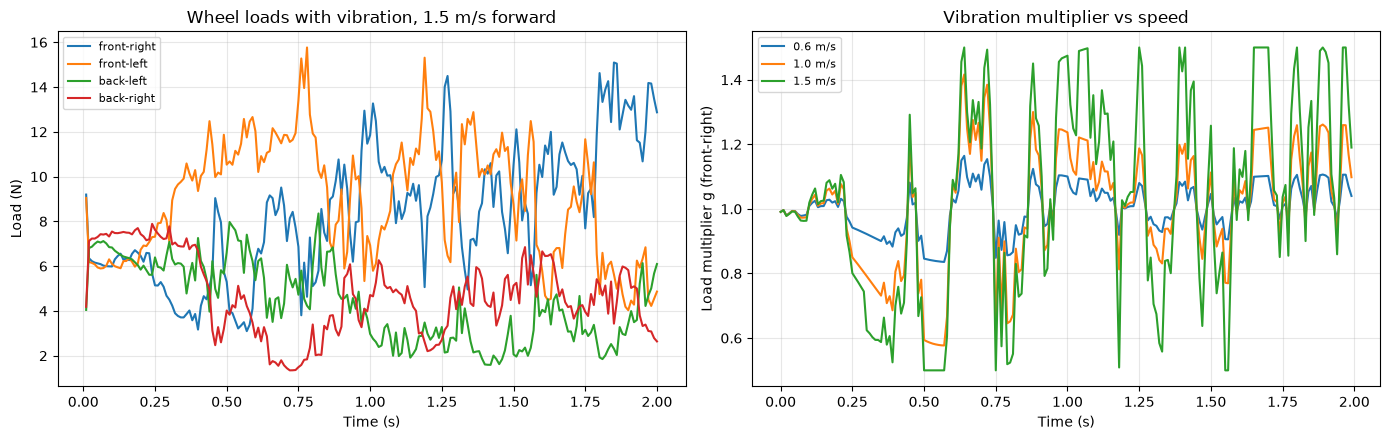

In [20]:
if RUN_PLANT_CHECKS:
    # 4.8 Wheel-load vibration: weight balance, repeatability, growth with speed, effect on slip.
    def vibration_run(speed, vibration=True, seed=DISTURBANCE_SEED, duration_s=2.0):
        """Open-loop forward run with only the load vibration (friction offset off)."""
        global ENABLE_FRICTION_OFFSET, ENABLE_LOAD_VIBRATION
        saved = (ENABLE_FRICTION_OFFSET, ENABLE_LOAD_VIBRATION)
        ENABLE_FRICTION_OFFSET, ENABLE_LOAD_VIBRATION = False, vibration
        try:
            return run_open_loop_schedule(lambda t: body_command(forward=speed), duration_s,
                                          disturbances=True, disturbance_seed=seed)
        finally:
            ENABLE_FRICTION_OFFSET, ENABLE_LOAD_VIBRATION = saved

    VIBRATION_SPEEDS = (0.6, 1.0, 1.5)  # m/s
    weight = rc.ROBOT_MASS * rc.GRAVITY
    vibration_runs = {speed: vibration_run(speed) for speed in VIBRATION_SPEEDS}
    calm_runs = {speed: vibration_run(speed, vibration=False) for speed in VIBRATION_SPEEDS}

    # 1. Weight balance.
    worst_sum = max(np.max(np.abs(log["normal_loads"][1:].sum(axis=1) - weight)) for log in vibration_runs.values())
    assert worst_sum < 1e-9, f"Vibrated loads do not sum to m g: {worst_sum:.2e} N"
    print(f"PASS weight balance: vibrated loads sum to m g within {worst_sum:.1e} N")

    # 2. Repeatability.
    repeat = vibration_run(VIBRATION_SPEEDS[-1])
    assert np.array_equal(repeat["normal_loads"], vibration_runs[VIBRATION_SPEEDS[-1]]["normal_loads"])
    print("PASS repeatability: the same seed gives the same loads")

    # 3. Ripple vs speed, in the last second (steady speed, so the acceleration term is small).
    ripple = []
    for speed in VIBRATION_SPEEDS:
        log = vibration_runs[speed]
        steady = log["time"] >= 1.0
        measured = np.std(log["load_scale"][:-1][steady[:-1]], axis=0).mean()  # g_i of the steps in the window
        contact_speed = np.abs(log["body_velocity"][steady, FORWARD_AXIS]).mean()  # v_total for a straight run
        predicted = min(rc.LOAD_VIBRATION_MAX, rc.LOAD_VIBRATION_BASE + rc.LOAD_VIBRATION_COMPLIANCE * 0.5
                        * rc.WHEEL_ENVELOPE_IRREGULARITY * (rc.N_ROLLERS * contact_speed / rc.WHEEL_RADIUS) ** 2 / rc.GRAVITY)
        ripple.append(measured)
        load_std = np.std(log["normal_loads"][steady], axis=0)
        jump = np.mean(np.abs(np.diff(log["load_scale"][:-1][steady[:-1]], axis=0)))  # step-to-step change of g_i
        calm_slide = (~calm_runs[speed]["rolling"][1:]).sum()
        vibration_slide = (~log["rolling"][1:]).sum()
        print(f"  {speed:.1f} m/s command (actual {contact_speed:.2f} m/s): predicted amplitude a = {predicted:.3f}, "
              f"std of g_i {measured:.3f}, mean step-to-step change {jump:.3f}; load std per wheel {np.round(load_std, 2)} N; "
              f"sliding wheel-samples {calm_slide} without vibration, {vibration_slide} with")
    assert ripple[0] < ripple[1] < ripple[2], "The load ripple should grow with speed"
    print("PASS: the load ripple grows with speed.")

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    log = vibration_runs[VIBRATION_SPEEDS[-1]]
    for wheel in range(N_WHEELS):
        axes[0].plot(log["time"][1:], log["normal_loads"][1:, wheel], label=rc.WHEEL_NAMES[wheel])
    axes[0].set(xlabel="Time (s)", ylabel="Load (N)", title=f"Wheel loads with vibration, {VIBRATION_SPEEDS[-1]} m/s forward")
    for speed in VIBRATION_SPEEDS:
        axes[1].plot(vibration_runs[speed]["time"][:-1], vibration_runs[speed]["load_scale"][:-1, 0], label=f"{speed} m/s")
    axes[1].set(xlabel="Time (s)", ylabel="Load multiplier g (front-right)", title="Vibration multiplier vs speed")
    for ax in axes:
        ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

## 4.10 Drive-friction transitions: breakaway and repeated grip/slide cycles

A wheel grips while the force it needs stays within $\mu_{d,s}N$, and slides otherwise (section 4). These tests check that the switch between the two is clean, for one wheel and for the whole robot (with `"static"` loads at the real CoG, so that the friction law alone decides when a wheel grips), with the three sliding laws side by side: `"switch"` (default), `"continuous"`, and the previous `"atan"`:

1. **The law.** Sign, cap, how fast it reaches the static limit, and the decay to the kinetic value.
2. **Breakaway close-up** at 0.1 ms: how much of the Stribeck force $\mu_d(|v|)N$ each law delivers from the breakaway instant on. At that instant the slip is zero: the slip laws (`"atan"`, `"continuous"`) give zero force there; `"switch"` keeps the static limit (transition band).
3. **Repeated cycles, whole robot.** An open-loop schedule that breaks the wheels loose and lets them re-grip twice: forward 3 m/s, stop, reverse 3 m/s, stop, at 1 ms resolution. Checks: each wheel's grip/slide transitions (no chattering: repeated toggling between grip and slide), the force jump when a wheel re-grips, the solver effort per step (chattering makes it explode), and that the robot ends at rest with every wheel gripping.
4. **Timestep convergence** of the same schedule (1 ms vs 0.5 ms).

In [ ]:
if RUN_PLANT_CHECKS:
    # 4.10 Drive-friction transitions: the law, repeated whole-robot grip/slide cycles, convergence.
    import time

    FRICTION_LAWS = ("atan", "continuous", "switch")
    # The laws are checked at every wheel's actual static load (configured CoG and wheel positions);
    # law_limit is the lightest wheel's grip limit, used for the printout.
    wheel_loads = OpenLoopPlant(load_model="static").plant.static_loads
    law_limit = rc.MU_D_STAT * wheel_loads.min()

    def with_sliding_law(law, function, *args, **kwargs):
        """Run function with DRIVE_SLIDING_LAW set to law, then restore it."""
        global DRIVE_SLIDING_LAW
        saved = DRIVE_SLIDING_LAW
        DRIVE_SLIDING_LAW = law
        try:
            return function(*args, **kwargs)
        finally:
            DRIVE_SLIDING_LAW = saved

    # 1. The law itself, at every wheel's static load (printout for the lightest wheel).
    slip = np.linspace(-0.5, 0.5, 20001)
    for law in FRICTION_LAWS:
        every_wheel = with_sliding_law(law, drive_friction_force, slip[:, None], wheel_loads)
        assert np.all(np.abs(every_wheel) <= rc.MU_D_STAT * wheel_loads + 1e-12), "friction must not exceed each wheel's limit"
        force = every_wheel[:, int(np.argmin(wheel_loads))]
        magnitude = np.abs(force)
        reach = slip[(slip > 0) & (magnitude >= 0.95 * law_limit)]
        print(f"{law:10s}: |F| at 1, 3, 10, 50 mm/s = "
              + ", ".join(f"{np.interp(v, slip, magnitude):.2f}" for v in (0.001, 0.003, 0.01, 0.05))
              + f" N (limit mu_s N = {law_limit:.2f} N); reaches 95% of the limit at "
              + (f"{reach[0] * 1e3:.1f} mm/s" if reach.size else "never")
              + f"; at 0.5 m/s {magnitude[-1]:.2f} N (mu_k N = {rc.MU_D_DYN * wheel_loads.min():.2f} N; "
              + f"lightest wheel, N = {wheel_loads.min():.2f} N)")
        assert np.all(np.sign(force[slip != 0]) == -np.sign(slip[slip != 0])), "friction must oppose slip"
        assert np.all(magnitude <= law_limit + 1e-12), "friction must not exceed the static limit"
    continuous = with_sliding_law("continuous", drive_friction_force, slip, wheel_loads.min())
    assert np.interp(0.005, slip, np.abs(continuous)) >= 0.95 * law_limit, "continuous law must reach the limit within 5 mm/s"
    print("PASS law: opposes slip, never exceeds mu_s N; the continuous law reaches the limit within 5 mm/s.")

    # The transition tests use "static" loads (real CoG): a wheel that breaks loose stays loose until
    # the command changes, so the friction law alone decides the transitions. With "quasi_static" the
    # load transfer arrives one timestep later, so at 0.1 ms it re-grips the wheel almost at once.
    TRANSITION_LOAD_MODEL = "static"

    # 2. Breakaway close-up at 0.1 ms. A hard forward step from rest breaks the rear wheels loose at
    #    once. At the breakaway instant the slip is still zero: the slip laws (atan, continuous) give
    #    zero force there; the transition band of the switch law keeps the static limit.
    def breakaway_closeup(duration_s=0.005, dt=1e-4):
        with cad_cog():  # real CoG: the rear wheels can break loose
            sim = OpenLoopPlant(dt=dt, load_model=TRANSITION_LOAD_MODEL)
        target = inverse_kinematics(body_command(forward=3.0))
        samples = []
        for _ in range(int(round(duration_s / dt))):
            out = sim.step(target)
            loads = sim.plant._force_selection_diagnostics["normal_loads"]
            samples.append((out["rolling"].copy(), out["ground_forces"].copy(), out["slip_speeds"].copy(), loads.copy()))
        return samples

    CLOSEUP_DT = 1e-4
    closeup_ratio = {}
    for law in FRICTION_LAWS:
        samples = with_sliding_law(law, breakaway_closeup, dt=CLOSEUP_DT)
        # Start at the first sample with a sliding wheel (the voltage plant needs ~0.5 ms to build current).
        first = next(k for k, sample in enumerate(samples) if (~sample[0]).any())
        wheel = int(np.flatnonzero(~samples[first][0])[0])
        samples = samples[first:]
        ratio = np.array([abs(force[wheel]) / (load[wheel] * mu_d(abs(slip_v[wheel])))
                          for _, force, slip_v, load in samples])
        closeup_ratio[law] = ratio
        print(f"{law:10s}: {rc.WHEEL_NAMES[wheel]} after breakaway, share of the Stribeck force delivered at "
              + ", ".join(f"{t * 1e3:.1f} ms: {ratio[int(round(t / CLOSEUP_DT))]:.2f}" for t in (0.0, 1e-4, 2e-4, 5e-4, 1e-3, 2e-3))
              + f" (slip then {samples[int(round(2e-3 / CLOSEUP_DT))][2][wheel]:.3f} m/s)")
    assert closeup_ratio["switch"].min() >= 0.95, "the switch law should keep the sliding force from the breakaway instant on"

    # 3. Repeated grip/slide cycles of the whole robot (configured CoG and load model) at 1 ms.
    CYCLE_DT = 1e-3
    def cycle_command(t):
        if t < 0.3:
            return body_command(forward=3.0)
        if t < 0.9:
            return body_command()
        if t < 1.2:
            return body_command(forward=-3.0)
        return body_command()

    def run_cycles(dt=CYCLE_DT, duration_s=2.4):
        with cad_cog():  # real CoG: the rear wheels can break loose
            sim = OpenLoopPlant(dt=dt, load_model=TRANSITION_LOAD_MODEL)
        times = np.arange(0.0, duration_s, dt)
        log = {key: [] for key in ("mode", "force", "limit", "slip", "nfev", "velocity", "required")}
        for t in times:
            out = sim.step(inverse_kinematics(cycle_command(t)))
            diag = sim.plant._force_selection_diagnostics
            log["mode"].append(out["rolling"]); log["force"].append(out["ground_forces"])
            log["limit"].append(out["friction_limits"]); log["slip"].append(out["slip_speeds"])
            log["nfev"].append(sim.plant.last_nfev); log["velocity"].append(out["body_velocity"])
            log["required"].append(diag["force_required"] - diag["grip_restoring_force"])
        log = {key: np.array(value) for key, value in log.items()}
        log["time"] = times + dt
        log["final_state"] = sim.state.copy()
        return log

    def cycle_summary(log):
        mode = log["mode"]
        # Slide episodes per wheel (a wheel already sliding at the first sample counts as one) and re-grips.
        episodes = (mode[:-1] & ~mode[1:]).sum(axis=0) + (~mode[0]).astype(int)
        regrips = (~mode[:-1] & mode[1:]).sum(axis=0)
        flicker = count_chatter(mode)  # repeated grip/slide toggling
        breakaway = np.argwhere(mode[:-1] & ~mode[1:])  # (sample, wheel): a gripping wheel starts to slide
        # Share of the Stribeck force mu_d(|v|) N (limit / mu_d,s * mu_d(|v|)) the wheel has at the first
        # sample after breakaway; the slip may already have grown, and the force decayed with it.
        kept = np.array([abs(log["force"][k + 1, w])
                         / (log["limit"][k + 1, w] / rc.MU_D_STAT * mu_d(abs(log["slip"][k + 1, w])))
                         for k, w in breakaway])
        regrip = np.argwhere(~mode[:-1] & mode[1:])  # (sample, wheel): a sliding wheel grips again
        jumps = np.array([abs(log["force"][k + 1, w] - log["force"][k, w]) / log["limit"][k, w] for k, w in regrip])
        return episodes, regrips, flicker, jumps, kept

    cycles = {}
    for law in FRICTION_LAWS:
        t0 = time.perf_counter()
        cycles[law] = with_sliding_law(law, run_cycles)
        cycles[law]["wall_s"] = time.perf_counter() - t0
    for law, log in cycles.items():
        episodes, regrips, flicker, jumps, kept = cycle_summary(log)
        print(f"{law:10s}: slide episodes per wheel {episodes}, re-grips {regrips}, chatter {flicker}, short grips {count_short_grips(log['mode'])}; force at the breakaway "
              f"sample min {kept.min():.2f} of the Stribeck force ({len(kept)} breakaways); force jump at re-grip "
              f"max {jumps.max():.2f} of the limit ({len(jumps)} re-grips); solver evaluations per 1 ms step "
              f"median {np.median(log['nfev']):.0f}, max {log['nfev'].max()}; run {log['wall_s']:.0f} s; end: speed "
              f"{np.linalg.norm(log['velocity'][-1, :2]) * 1e3:.1f} mm/s, max slip {np.max(np.abs(log['slip'][-1])) * 1e3:.2f} mm/s, "
              f"all gripping {bool(log['mode'][-1].all())}")

    new = cycles["switch"]
    new_episodes, new_regrips, new_flicker, new_jumps, new_kept = cycle_summary(new)
    assert new_kept.min() >= 0.95, f"a wheel lost its force at breakaway (kept {new_kept.min():.2f} of the Stribeck force)"
    assert new_episodes.max() >= 2 and new_regrips.max() >= 2, "the schedule should break wheels loose and re-grip them at least twice"
    assert new_flicker == 0, f"grip/slide chattering: {new_flicker} windows with three mode changes in four samples"
    assert new["mode"][-1].all() and np.linalg.norm(new["velocity"][-1, :2]) < 0.01, "the robot should end at rest, gripping"
    print("PASS cycles: repeated breakaway and re-grip of the whole robot, no chattering, force kept at every breakaway, "
          "ends at rest with every wheel gripping.")
    print("At re-grip the slip reaches zero and the kinetic friction (about mu_k N) is replaced by the force needed to roll:"
          " a physical stick-slip step, not chattering (the slip stays at zero afterwards).")

    # 4. Timestep convergence of the switch law (the default) through the same schedule.
    fine_cycles = run_cycles(dt=CYCLE_DT / 2)
    pose_gap = np.linalg.norm(fine_cycles["final_state"][:2] - new["final_state"][:2])
    print(f"Timestep convergence (1 ms vs 0.5 ms): final position differs by {pose_gap * 1e3:.2f} mm")

    fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
    REAR = 2  # back-left
    for law, style in (("atan", ":"), ("continuous", "--"), ("switch", "-")):
        log = cycles[law]
        axes[0].plot(log["time"], log["force"][:, REAR], "C0" + style, label=f"applied force, {law}")
        axes[1].plot(log["time"], log["slip"][:, REAR] * 1e3, "C1" + style, label=f"slip, {law}")
        axes[2].plot(log["time"], log["velocity"][:, FORWARD_AXIS], "C2" + style, label=f"forward speed, {law}")
    log = cycles["switch"]
    axes[0].plot(log["time"], log["limit"][:, REAR], "k--", linewidth=0.8, label="grip limit")
    axes[0].plot(log["time"], -log["limit"][:, REAR], "k--", linewidth=0.8)
    axes[0].plot(log["time"], log["limit"][:, REAR] * rc.MU_D_DYN / rc.MU_D_STAT, "k-.", linewidth=0.6, label="sliding level")
    axes[0].plot(log["time"], -log["limit"][:, REAR] * rc.MU_D_DYN / rc.MU_D_STAT, "k-.", linewidth=0.6)
    axes[0].plot(log["time"], log["required"][:, REAR], "C3", alpha=0.5, label="force needed to grip (switch)")
    axes[0].set_ylim(-3 * law_limit, 3 * law_limit)
    sliding = ~log["mode"][:, REAR]
    for ax in axes:
        ax.fill_between(log["time"], 0, 1, where=sliding, transform=ax.get_xaxis_transform(), color="C3", alpha=0.08)
        ax.grid(True, alpha=0.3); ax.legend(fontsize=8, loc="upper right")
    axes[0].set(ylabel="Force (N)", title="Back-left wheel through forward / stop / reverse / stop (shaded: sliding, switch law)")
    axes[1].set(ylabel="Slip (mm/s)")
    axes[2].set(xlabel="Time (s)", ylabel="Speed (m/s)")
    plt.tight_layout(); plt.show()
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

## 4.11 Stick-slip benchmark (Leine et al. 1998)

Before trusting the friction logic on the robot, check it on the standard stick-slip problem from the paper that defines the switch model: a mass on a spring, resting on a belt that moves at constant speed,
$$m\ddot x + kx = F_f,\qquad v_{rel} = \dot x - v_{belt},\qquad |F_f| = \frac{F_s}{1 + \delta |v_{rel}|}\ \text{while slipping},$$
with Leine's values $m = k = F_s = 1$, $v_{belt} = 0.2$, $\delta = 3$. It settles on a stick-slip limit cycle: the mass rides on the belt until the spring force reaches $F_s$ ($x = 1$), slips back, and sticks again.

The **reference** is exact: it integrates the slip phases with event detection and switches modes at the true events. The **models under test** use the plant's friction logic as one smooth ODE that decides the mode at every evaluation (stick by force, the transition band, the slip laws), with the plant's integrator and tolerances. They pass if they reproduce the reference's period and amplitude. A force that passes through zero at breakaway shows up as a dip in the friction trace.

exact reference : period 12.0010 s, x from -0.5554 to +1.1339, sticking 65.4% of the cycle
atan            : period 11.2960 s (-5.87%), x max +1.0729 (-5.38%), x min -0.4694, sticking 64.3%; lowest |friction| in the 50 ms after release 0.171 N (F_s = 1.0); 30213 evaluations
continuous      : period 11.9120 s (-0.74%), x max +1.1259 (-0.71%), x min -0.5439, sticking 64.3%; lowest |friction| in the 50 ms after release 0.954 N (F_s = 1.0); 29699 evaluations
switch          : period 12.0000 s (-0.01%), x max +1.1339 (-0.00%), x min -0.5554, sticking 65.3%; lowest |friction| in the 50 ms after release 0.989 N (F_s = 1.0); 28733 evaluations
PASS benchmark: the switch law reproduces the exact stick-slip limit cycle (period and amplitude within 1%).


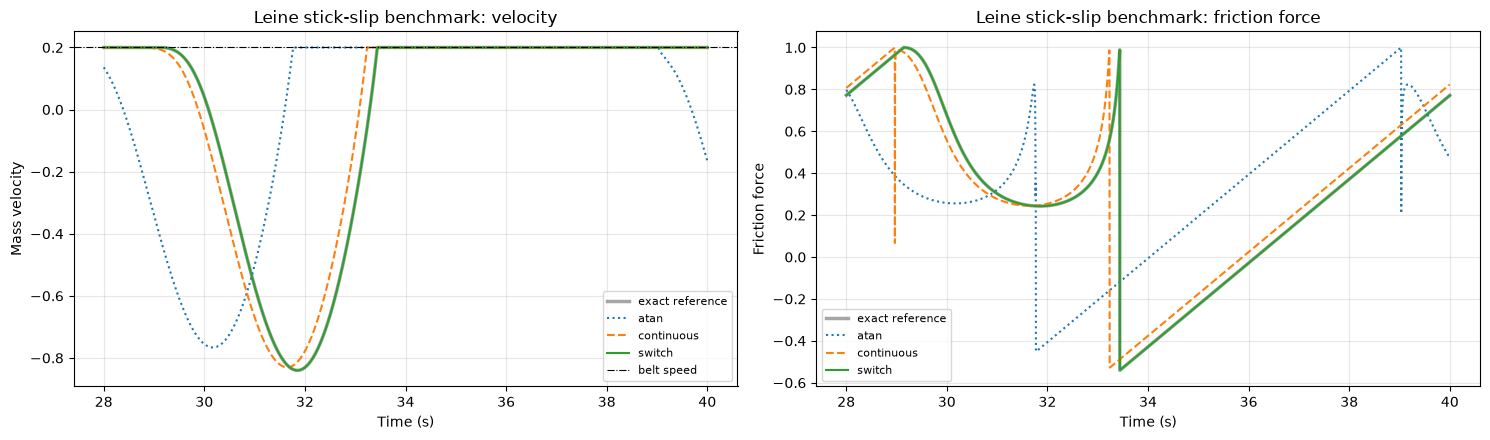

In [22]:
if RUN_PLANT_CHECKS:
    # 4.11 Stick-slip benchmark (Leine, Van Campen & de Kraker 1998): spring-mass on a moving belt.
    BENCH = dict(m=1.0, k=1.0, v_belt=0.2, F_s=1.0, delta=3.0)
    BENCH_RESTORING = 1.0e3  # stick restoring gain [N per m/s], as the plant's -k v_d (time constant m / gain = 1 ms)
    BENCH_T_END = 40.0

    def bench_slip_force(speed):
        """Magnitude of the slipping friction, Leine's curve F_s / (1 + delta |v|)."""
        return BENCH["F_s"] / (1.0 + BENCH["delta"] * speed)

    def bench_exact(t_end=BENCH_T_END):
        """Event-driven reference: slip phases integrated to v_rel = 0, stick phases exact."""
        m, k, vb, fs = BENCH["m"], BENCH["k"], BENCH["v_belt"], BENCH["F_s"]
        t, x, v = 0.0, 0.0, 0.0
        times, xs, vs, forces = [], [], [], []
        released = False  # a stick phase just ended at k x = F_s: the next phase is slip
        while t < t_end - 1e-9:
            if not released and abs(v - vb) < 1e-9 and abs(k * x) <= fs + 1e-12:
                t_release = min(t + (fs / k - x) / vb, t_end)   # the spring force reaches F_s
                grid = np.linspace(t, t_release, 400)
                times += list(grid); xs += list(x + vb * (grid - t)); vs += [vb] * len(grid); forces += list(k * (x + vb * (grid - t)))
                x, t, v = x + vb * (t_release - t), t_release, vb
                released = True
                continue
            released = False
            # Slip until v_rel crosses zero again. At release v_rel = 0 and falls, so detect only the
            # crossing in the other direction.
            heading_down = (k * x > 0) if abs(v - vb) < 1e-9 else (v - vb < 0)
            def rhs(_, y):
                vrel = y[1] - vb
                friction = -np.sign(vrel) * bench_slip_force(abs(vrel)) if vrel != 0 else (fs if heading_down else -fs)
                return [y[1], (-k * y[0] + friction) / m]
            def stick_event(_, y):
                return y[1] - vb
            stick_event.terminal = True
            stick_event.direction = 1.0 if heading_down else -1.0
            sol = solve_ivp(rhs, (t, t_end), [x, v], events=stick_event, max_step=0.01, rtol=1e-10, atol=1e-12, dense_output=True)
            grid = np.linspace(t, sol.t[-1], max(2, int((sol.t[-1] - t) / 0.005)))
            y = sol.sol(grid)
            times += list(grid); xs += list(y[0]); vs += list(y[1])
            forces += [m * a + k * xx for a, xx in zip(np.gradient(y[1], grid), y[0])]
            t, x, v = sol.t[-1], sol.y[0, -1], sol.y[1, -1]
            if sol.status == 1:
                v = vb  # landed on the belt speed; the stick test above decides what happens next
        return np.array(times), np.array(xs), np.array(vs), np.array(forces)

    def bench_friction(x, v, law):
        """The plant's friction logic for the benchmark: stick by force, transition band, slip law."""
        k, vb, fs = BENCH["k"], BENCH["v_belt"], BENCH["F_s"]
        vrel = v - vb
        needed = k * x - BENCH_RESTORING * vrel          # holds v_rel' = 0 and pulls v_rel to zero
        if abs(needed) <= fs:
            return needed, True
        if law == "switch" and abs(vrel) < rc.DRIVE_BREAKAWAY_BAND:
            return np.sign(needed) * bench_slip_force(abs(vrel)), False
        if law == "atan":
            shape = (2.0 / np.pi) * np.arctan(rc.K_SMOOTH_D * vrel)
        else:
            shape = np.tanh(vrel / rc.DRIVE_SLIP_REGULARIZATION)
        return -bench_slip_force(abs(vrel)) * shape, False

    def bench_model(law, t_end=BENCH_T_END):
        m, k = BENCH["m"], BENCH["k"]
        def rhs(_, y):
            force, _ = bench_friction(y[0], y[1], law)
            return [y[1], (-k * y[0] + force) / m]
        sol = solve_ivp(rhs, (0.0, t_end), [0.0, 0.0], method=PLANT_INTEGRATOR, rtol=WheelSlipRobotSimulator.integrator_rtol,
                        atol=WheelSlipRobotSimulator.integrator_atol, max_step=DT, dense_output=True)
        grid = np.arange(0.0, t_end, 0.002)
        y = sol.sol(grid)
        forces = np.array([bench_friction(xx, vv, law)[0] for xx, vv in zip(y[0], y[1])])
        return grid, y[0], y[1], forces, sol.nfev

    def limit_cycle(times, xs, vs):
        """Period, x range, and stick share of the last full cycles (stick starts = v reaching the belt)."""
        sticking = np.abs(vs - BENCH["v_belt"]) < 2e-3
        starts = times[1:][sticking[1:] & ~sticking[:-1]]
        starts = starts[starts > 0.3 * times[-1]]
        window = (times >= starts[0]) & (times <= starts[-1])
        step = np.diff(times, append=times[-1])          # time-weighted: the reference is sampled unevenly
        return (np.diff(starts).mean(), xs[window].max(), xs[window].min(),
                np.sum(step[window & sticking]) / np.sum(step[window]))

    ref_t, ref_x, ref_v, ref_f = bench_exact()
    ref_cycle = limit_cycle(ref_t, ref_x, ref_v)
    print(f"exact reference : period {ref_cycle[0]:.4f} s, x from {ref_cycle[2]:+.4f} to {ref_cycle[1]:+.4f}, sticking {100 * ref_cycle[3]:.1f}% of the cycle")
    bench_runs = {}
    for law in ("atan", "continuous", "switch"):
        t_m, x_m, v_m, f_m, nfev = bench_model(law)
        cycle = limit_cycle(t_m, x_m, v_m)
        bench_runs[law] = (t_m, x_m, v_m, f_m)
        release = np.flatnonzero((np.abs(v_m[:-1] - BENCH["v_belt"]) < 2e-3) & (np.abs(v_m[1:] - BENCH["v_belt"]) >= 2e-3))
        dip = min(np.min(np.abs(f_m[r:r + 25])) for r in release[2:]) if release.size > 2 else np.nan
        print(f"{law:10s}      : period {cycle[0]:.4f} s ({100 * (cycle[0] / ref_cycle[0] - 1):+.2f}%), x max {cycle[1]:+.4f} "
              f"({100 * (cycle[1] / ref_cycle[1] - 1):+.2f}%), x min {cycle[2]:+.4f}, sticking {100 * cycle[3]:.1f}%; "
              f"lowest |friction| in the 50 ms after release {dip:.3f} N (F_s = {BENCH['F_s']}); {nfev} evaluations")
    switch_cycle = limit_cycle(*bench_runs["switch"][:3])
    assert abs(switch_cycle[0] / ref_cycle[0] - 1) < 0.01, "switch law: limit-cycle period off by more than 1%"
    assert abs(switch_cycle[1] / ref_cycle[1] - 1) < 0.01, "switch law: stick-release position off by more than 1%"
    print("PASS benchmark: the switch law reproduces the exact stick-slip limit cycle (period and amplitude within 1%).")

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    show = ref_t > BENCH_T_END - 12
    axes[0].plot(ref_t[show], ref_v[show], "k", linewidth=2.5, alpha=0.35, label="exact reference")
    axes[1].plot(ref_t[show], ref_f[show], "k", linewidth=2.5, alpha=0.35, label="exact reference")
    for law, style in (("atan", ":"), ("continuous", "--"), ("switch", "-")):
        t_m, x_m, v_m, f_m = bench_runs[law]
        show = t_m > BENCH_T_END - 12
        axes[0].plot(t_m[show], v_m[show], style, label=law)
        axes[1].plot(t_m[show], f_m[show], style, label=law)
    axes[0].axhline(BENCH["v_belt"], color="k", linewidth=0.8, linestyle="-.", label="belt speed")
    axes[0].set(xlabel="Time (s)", ylabel="Mass velocity", title="Leine stick-slip benchmark: velocity")
    axes[1].set(xlabel="Time (s)", ylabel="Friction force", title="Leine stick-slip benchmark: friction force")
    for ax in axes:
        ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

## 4.12 Grip-boundary stress tests

The cases that make friction models chatter, run on the whole robot with the default `"switch"` law (static loads at the real CoG, so the friction logic alone decides the modes; 1 ms resolution):

1. **Slow current ramp.** A forward current pattern ramps up slowly, holds, and ramps down, so the rear wheels' demand sits at their grip limit for a long time while they break loose and re-grip.
2. **Load vibration on.** The grip limit itself fluctuates around the demand (forward / stop / reverse / stop schedule).
3. **Fast reversals.** Full forward and full reverse commands alternate every 0.15 s, then stop.
4. **Solver tolerance.** The reversal run again with 100 times tighter tolerances.

Each run checks for chattering (one wheel changing grip/slide mode three or more times within four samples; single short grips are reported separately, because a braked wheel can genuinely stick for a moment as its slip passes through zero), the solver effort per step, and that friction never feeds energy into the robot (friction power $F_d v_d \le 0$, up to the transition band).

In [ ]:
if RUN_PLANT_CHECKS:
    # 4.12 Grip-boundary stress tests of the whole robot with the default friction law.
    STRESS_DT = 1e-3
    STRESS_LOAD_MODEL = "static"
    FORWARD_PATTERN = np.sign(inverse_kinematics(body_command(forward=1.0)))

    def stress_run(duration_s, command_fn=None, current_fn=None, disturbances=False, rtol=None, atol=None):
        """Run the plant at STRESS_DT with wheel-speed targets (command_fn) or motor currents (current_fn)."""
        with cad_cog():  # real CoG: the rear wheels can break loose
            sim = OpenLoopPlant(dt=STRESS_DT, load_model=STRESS_LOAD_MODEL, disturbances=disturbances)
        plant = sim.plant
        if rtol is not None:
            plant.integrator_rtol, plant.integrator_atol = rtol, atol
        voltage_plant = hasattr(plant, "current_to_voltage")
        log = {key: [] for key in ("mode", "force", "limit", "slip", "nfev", "velocity", "needed")}
        for t in np.arange(0.0, duration_s, STRESS_DT):
            if current_fn is None:
                out = sim.step(inverse_kinematics(command_fn(t)))
                mode, force, limit, slip = out["rolling"], out["ground_forces"], out["friction_limits"], out["slip_speeds"]
                needed = out["force_needed"]
            else:
                request = current_fn(t)
                plant.state = sim.state
                plant.update_contact_disturbances()
                applied = sim.state[10:14] if voltage_plant else plant.saturate_current(sim.state, request)
                plant._contact_wrenches(sim.state, applied, np.zeros(3))
                diag = plant._force_selection_diagnostics
                mode, force, limit, slip = diag["rolling_mask"], diag["force_used"], diag["traction_limits"], diag["wheel_slip_d"]
                needed = diag["force_to_roll"]
                command = plant.current_to_voltage(sim.state, request) if voltage_plant else request
                sim.state = plant.discrete_map(sim.state, command, np.zeros(3))
            log["mode"].append(mode.copy()); log["force"].append(force.copy()); log["limit"].append(limit.copy())
            log["slip"].append(slip.copy()); log["nfev"].append(plant.last_nfev); log["needed"].append(np.array(needed).copy())
            log["velocity"].append(np.r_[world_to_body(sim.state[3:5], sim.state[2]), sim.state[5]])
        log = {key: np.array(value) for key, value in log.items()}
        log["time"] = np.arange(len(log["mode"])) * STRESS_DT
        log["final_state"] = sim.state.copy()
        return log

    def stress_summary(name, log):
        mode = log["mode"]
        flicker = count_chatter(mode)
        episodes = (mode[:-1] & ~mode[1:]).sum(axis=0) + (~mode[0]).astype(int)
        regrips = (~mode[:-1] & mode[1:]).sum(axis=0)
        # Friction power of the sliding contacts [W]; a gripping contact does no work (zero slip).
        power = np.where(~mode, log["force"] * log["slip"], 0.0)
        fed = power[power > 0].sum()
        dissipated = -power[power < 0].sum()
        share = fed / dissipated if dissipated > 0 else 0.0
        print(f"  {name:28s}: slide episodes {episodes}, re-grips {regrips}, chatter {flicker}, short grips {count_short_grips(mode)}; solver evaluations per step "
              f"median {np.median(log['nfev']):.0f}, max {log['nfev'].max()}; friction power fed in / dissipated "
              f"{100 * share:.3f}%; end speed {np.linalg.norm(log['velocity'][-1, :2]) * 1e3:.1f} mm/s, "
              f"all gripping {bool(mode[-1].all())}")
        return flicker, share, log["nfev"].max()

    def ramp_current(t):
        """0 -> 5 A over 1.5 s, hold 0.3 s, back to 0 over 1.5 s, then 0 (forward pattern)."""
        level = np.interp(t, [0.0, 1.5, 1.8, 3.3], [0.0, rc.IQ_LIMIT, rc.IQ_LIMIT, 0.0])
        return level * FORWARD_PATTERN

    def stop_go(t):
        if t < 0.3:
            return body_command(forward=3.0)
        if t < 0.9:
            return body_command()
        if t < 1.2:
            return body_command(forward=-3.0)
        return body_command()

    def reversals(t):
        if t < 1.2:
            return body_command(forward=3.0 if int(t / 0.15) % 2 == 0 else -3.0)
        return body_command()

    def with_vibration(function, *args, **kwargs):
        global ENABLE_FRICTION_OFFSET, ENABLE_LOAD_VIBRATION
        saved = (ENABLE_FRICTION_OFFSET, ENABLE_LOAD_VIBRATION)
        ENABLE_FRICTION_OFFSET, ENABLE_LOAD_VIBRATION = False, True
        try:
            return function(*args, **kwargs)
        finally:
            ENABLE_FRICTION_OFFSET, ENABLE_LOAD_VIBRATION = saved

    print(f"Stress tests, sliding law '{DRIVE_SLIDING_LAW}', {STRESS_LOAD_MODEL} loads, {1e3 * STRESS_DT:.0f} ms:")
    stress = {
        "slow current ramp": stress_run(4.0, current_fn=ramp_current),
        "load vibration, stop/go": with_vibration(stress_run, 2.4, command_fn=stop_go, disturbances=True),
        "fast reversals": stress_run(2.0, command_fn=reversals),
        "fast reversals, tight tolerances": stress_run(2.0, command_fn=reversals, rtol=1e-7, atol=1e-9),
    }
    results = {name: stress_summary(name, log) for name, log in stress.items()}
    for name, (flicker, share, max_nfev) in results.items():
        assert flicker == 0, f"{name}: grip/slide chattering ({flicker})"
        assert share < 0.01, f"{name}: friction fed {100 * share:.2f}% of the dissipated energy back in"
    tolerance_gap = np.linalg.norm(stress["fast reversals"]["final_state"][:2] - stress["fast reversals, tight tolerances"]["final_state"][:2])
    print(f"Fast reversals, default vs tight tolerances: final position differs by {tolerance_gap * 1e3:.2f} mm")
    assert tolerance_gap < 2e-3, "the result depends on the solver tolerance"
    assert stress["fast reversals"]["mode"][-1].all() and stress["load vibration, stop/go"]["mode"][-1].all()
    print("PASS stress tests: no chattering, friction never feeds energy in, normal solver effort, tolerance-independent.")

    fig, axes = plt.subplots(len(stress), 1, figsize=(13, 3.2 * len(stress)), sharex=False)
    REAR = 2  # back-left
    for ax, (name, log) in zip(axes, stress.items()):
        plot_force_levels(ax, log["time"], log["force"][:, REAR], log["needed"][:, REAR], log["limit"][:, REAR], "C0", "back-left")
        ax.fill_between(log["time"], 0, 1, where=~log["mode"][:, REAR], transform=ax.get_xaxis_transform(), color="C3", alpha=0.1)
        ax.set(ylabel="Force (N)", title=f"{name} (shaded: back-left sliding; dashed: grip limit, dash-dot: sliding level)")
        ax.set_ylim(-3 * log["limit"][:, REAR].max(), 3 * log["limit"][:, REAR].max())
        ax.grid(True, alpha=0.3); ax.legend(fontsize=8, loc="upper right")
    axes[-1].set_xlabel("Time (s)")
    plt.tight_layout(); plt.show()
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

## 4.13 Aggressive open-loop manoeuvres

Dana's suite (sections 4.2-4.4) commands 0.25-0.35 m/s and 0.6-0.8 rad/s, which barely loads the wheels. These manoeuvres command near the robot's limits, with the motors at the current limit, using the configured CoG and load model and no disturbances. Each command is held for 1 s, then the robot is told to stop for 1.5 s.

Slip is expected here, so the checks are the ones that must hold anyway: the motor limits are respected, the robot moves in the commanded direction, it comes to rest, and the friction law does not chatter between grip and slide (three or more mode changes of one wheel within four samples). The chatter check runs with `"static"` loads, which isolates the friction law from the one-`DT` lag of the `"quasi_static"` load transfer. Single short grips are reported, not failed: a braked wheel's slip can pass through zero, stick for a few milliseconds, and break loose again. Open loop, nothing holds the heading: once the rear wheels slide, a sideways command can turn into a spin (the real-CoG sideways case), so the direction check uses the first 0.1 s of each manoeuvre.

In [ ]:
if RUN_PLANT_CHECKS:
    # 4.13 Aggressive open-loop manoeuvres: near-limit commands, then stop.
    MANOEUVRES = {
        "forward 2.5 m/s": body_command(forward=2.5),
        "sideways (+x) 2.0 m/s": body_command(left=-2.0),
        "diagonal 1.8 + 1.8 m/s": body_command(forward=1.8, left=-1.8),
        "yaw 6 rad/s": body_command(yaw_rate=6.0),
        "forward 2.0 m/s + yaw 3 rad/s": body_command(forward=2.0, yaw_rate=3.0),
    }
    HOLD_S, STOP_S = 1.0, 1.5
    manoeuvre_runs = {}
    print("Aggressive manoeuvres (open loop, configured CoG and load model, no disturbances):")
    for name, command in MANOEUVRES.items():
        schedule = lambda t, c=command: c if t < HOLD_S else body_command()
        log = run_open_loop_schedule(schedule, HOLD_S + STOP_S)
        manoeuvre_runs[name] = log
        # The same manoeuvre with "static" loads isolates the friction law: the "quasi_static" loads
        # lag one DT, and in a hard reversal that lag can let a wheel grip for a single sample.
        static_mode = run_open_loop_schedule(schedule, HOLD_S + STOP_S, load_model="static")["rolling"][1:]
        static_flicker = count_chatter(static_mode)
        held = log["time"] < HOLD_S
        velocity = log["body_velocity"]
        mean_twist = velocity[held].mean(axis=0)
        accel = np.gradient(velocity[:, :2], log["time"], axis=0)
        mode = log["rolling"][1:]
        flicker = count_chatter(mode)
        end_speed = np.linalg.norm(velocity[-1, :2])
        print(f"  {name:30s}: peak speed {np.linalg.norm(velocity[:, :2], axis=1).max():.2f} m/s, peak acceleration "
              f"{np.linalg.norm(accel, axis=1).max():.2f} m/s^2, peak |yaw rate| {np.abs(velocity[:, 2]).max():.2f} rad/s, "
              f"heading at end {np.degrees(log['pose'][-1, 2]):+.1f} deg; sliding samples per wheel {(~mode).sum(axis=0)}, "
              f"chatter {flicker} (static loads: {static_flicker}), short grips {count_short_grips(mode)}; end speed {end_speed * 1e3:.0f} mm/s, yaw rate {velocity[-1, 2]:+.3f} rad/s")
        assert np.all(np.abs(log["motor_currents"]) <= rc.IQ_LIMIT + 1e-3), f"{name}: current limit exceeded"
        assert np.all(np.abs(log["motor_voltages"]) <= rc.MAX_MOTOR_VOLTAGE + 1e-9), f"{name}: voltage limit exceeded"
        commanded = command / max(np.linalg.norm(command), 1e-12)
        # Open loop nothing holds the heading, so a sideways command can turn into a spin once the rear
        # wheels slide. The direction check therefore uses the first 0.1 s, before the spin builds up.
        initial_twist = velocity[(log["time"] > 0.0) & (log["time"] <= 0.1)].mean(axis=0)
        # Translation direction when the command translates (the CoG coupling can briefly turn the robot
        # against a commanded yaw); the yaw sign for a pure yaw command.
        if np.linalg.norm(command[:2]) > 0:
            started = initial_twist[:2] @ command[:2] > 0
        else:
            started = initial_twist[2] * command[2] > 0
        assert started, f"{name}: the robot did not start moving in the commanded direction"
        assert static_flicker == 0, f"{name}: grip/slide chattering with static loads (friction law)"
        assert end_speed < 0.05 and abs(velocity[-1, 2]) < 0.1, f"{name}: the robot did not come to rest"
    print("PASS manoeuvres: limits respected, motion in the commanded direction, no chattering from the friction law, robot comes to rest.")
    print("Short grips are real: a braked wheel's slip passes through zero and it sticks briefly before breaking loose again.")

    fig, axes = plt.subplots(len(MANOEUVRES), 2, figsize=(18, 2.9 * len(MANOEUVRES)), sharex=True)
    for row, (name, log) in zip(axes, manoeuvre_runs.items()):
        ax = row[0]
        for k, (label, color) in enumerate((("u (right)", "C0"), ("v (forward)", "C1"), ("omega", "C2"))):
            ax.plot(log["time"], log["body_velocity"][:, k], color, label=label)
            ax.plot(log["time"], log["body_command"][:, k], color + "--", linewidth=0.8)
        ax.set(ylabel="m/s, rad/s", title=f"{name} (dashed: command)")
        ax = row[1]
        for wheel, color in ((2, "C0"), (3, "C1")):
            plot_force_levels(ax, log["time"][1:], log["ground_forces"][1:, wheel], log["force_needed"][1:, wheel],
                              log["friction_limits"][1:, wheel], color, rc.WHEEL_NAMES[wheel])
        ax.set_ylim(-3 * log["friction_limits"][1:, 2:].max(), 3 * log["friction_limits"][1:, 2:].max())
        over, band, recovering = sliding_breakdown(log["rolling"][1:, 2:], log["force_needed"][1:, 2:], log["friction_limits"][1:, 2:])
        ax.set(ylabel="Force (N)", title=f"{name}: rear wheels (sliding: {100 * over:.0f}% over the grip limit, "
                                         f"{100 * band:.0f}% in the band, {100 * recovering:.0f}% below the sliding level)")
        for ax in row:
            ax.grid(True, alpha=0.3); ax.legend(fontsize=6, loc="upper right")
    axes[-1, 0].set_xlabel("Time (s)"); axes[-1, 1].set_xlabel("Time (s)")
    plt.tight_layout(); plt.show()
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

## 4.14 Grip/slide transitions at speed

The whole robot cruises at 1.5 m/s, gets a sideways burst (the rear wheels break loose), returns to straight cruising (they re-grip at speed), gets a hard push to 3 m/s (they break loose again), and returns to cruise. Commands ramp over 0.1 s between phases, so the transitions are not caused by command steps. Real CoG, `"static"` loads, 1 ms resolution, run with the instant switch (`DRIVE_MODE_BLEND_TIME = 0`) and with the configured blend time.

Checks for the configured blend, at every transition: the robot is moving (faster than 0.5 m/s), no wheel's force exceeds its grip limit, no chattering, and breakaways are smooth (largest 1 ms force change within 5 ms of a breakaway at most 0.2 N). The re-grip step is reported: when a sliding wheel's slip reaches zero it does so within about a millisecond, because the wheel's inertia at the rim is small ($J_w/R_w^2 \approx$ 18.5 g), so the force changes quickly there whatever the blend time.

In [ ]:
if RUN_PLANT_CHECKS:
    # 4.14 Grip/slide transitions at speed: instant switch vs the configured blend (robot level, 1 ms).
    AT_SPEED_DT = 1e-3
    KEY_T = [0.0, 1.0, 1.1, 1.3, 1.4, 2.0, 2.1, 2.3, 2.4, 3.5]
    KEY_FORWARD = [0.0, 1.5, 1.5, 1.5, 1.5, 1.5, 3.0, 3.0, 1.5, 1.5]
    KEY_LEFT = [0.0, 0.0, -1.5, -1.5, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

    def at_speed_command(t):
        return body_command(forward=float(np.interp(t, KEY_T, KEY_FORWARD)), left=float(np.interp(t, KEY_T, KEY_LEFT)))

    def run_at_speed(blend_time):
        global DRIVE_MODE_BLEND_TIME
        saved = DRIVE_MODE_BLEND_TIME
        DRIVE_MODE_BLEND_TIME = blend_time
        try:
            with cad_cog():
                sim = OpenLoopPlant(dt=AT_SPEED_DT, load_model="static")
            rows = {key: [] for key in ("mode", "force", "limit", "slip", "speed", "omega", "needed")}
            for t in np.arange(0.0, KEY_T[-1], AT_SPEED_DT):
                out = sim.step(inverse_kinematics(at_speed_command(t)))
                rows["mode"].append(out["rolling"].copy()); rows["force"].append(out["ground_forces"].copy())
                rows["limit"].append(out["friction_limits"].copy()); rows["slip"].append(out["slip_speeds"].copy())
                rows["speed"].append(np.linalg.norm(out["body_velocity"][:2])); rows["omega"].append(out["body_velocity"][2])
                rows["needed"].append(out["force_needed"].copy())
        finally:
            DRIVE_MODE_BLEND_TIME = saved
        log = {key: np.array(value) for key, value in rows.items()}
        log["time"] = np.arange(len(log["mode"])) * AT_SPEED_DT
        return log

    def transitions(log):
        """(sample, wheel, kind, robot speed, largest 1 ms force change within +/-5 ms)."""
        found = []
        for wheel in range(N_WHEELS):
            for k in np.flatnonzero(log["mode"][1:, wheel] != log["mode"][:-1, wheel]) + 1:
                window = log["force"][max(0, k - 5):k + 6, wheel]
                kind = "breakaway" if log["mode"][k - 1, wheel] else "re-grip"
                found.append((k, wheel, kind, log["speed"][k], float(np.max(np.abs(np.diff(window))))))
        return sorted(found)

    at_speed = {"instant switch": run_at_speed(0.0), f"blend {DRIVE_MODE_BLEND_TIME * 1e3:.0f} ms": run_at_speed(DRIVE_MODE_BLEND_TIME)}
    for label, log in at_speed.items():
        found = transitions(log)
        breakaway = [f[4] for f in found if f[2] == "breakaway"]
        regrip = [f[4] for f in found if f[2] == "re-grip"]
        over = np.max(np.abs(log["force"]) - log["limit"])
        print(f"{label:16s}: {len(found)} transitions at robot speeds {min(f[3] for f in found):.2f}-{max(f[3] for f in found):.2f} m/s; "
              f"largest 1 ms force change at breakaway {max(breakaway):.2f} N, at re-grip {max(regrip):.2f} N; "
              f"force above the grip limit by at most {over:+.3f} N; chatter {count_chatter(log['mode'])}; "
              f"rear sliding samples {(~log['mode'][:, 2:]).sum(axis=0)}; peak |yaw rate| {np.abs(log['omega']).max():.2f} rad/s; "
              f"all rolling at the end {bool(log['mode'][-1].all())}")
        over, band, recovering = sliding_breakdown(log["mode"][:, 2:], log["needed"][:, 2:], log["limit"][:, 2:])
        print(f"{'':16s}  rear sliding samples: {100 * over:.0f}% with the need over the grip limit, {100 * band:.0f}% "
              f"in the band (need between the sliding level and the grip limit), {100 * recovering:.0f}% below the sliding level")
    blended = at_speed[f"blend {DRIVE_MODE_BLEND_TIME * 1e3:.0f} ms"]
    found = transitions(blended)
    assert found and min(f[3] for f in found) > 0.5, "every transition should happen while the robot moves faster than 0.5 m/s"
    assert np.max(np.abs(blended["force"]) - blended["limit"]) <= 1e-6, "a wheel's force exceeded its grip limit"
    assert count_chatter(blended["mode"]) == 0, "grip/slide chattering"
    assert max(f[4] for f in found if f[2] == "breakaway") <= 0.2, "breakaway is not smooth with the blend"
    assert blended["mode"][-1].all(), "the wheels should roll again in the final cruise"
    print("PASS at speed: transitions while moving, force within the grip limit, no chattering, smooth breakaways, rolling at the end.")

    fig, axes = plt.subplots(4, 1, figsize=(13, 13), sharex=True)
    for row, (label, log) in enumerate(at_speed.items()):
        for wheel, color in ((2, "C0"), (3, "C1")):
            plot_force_levels(axes[row], log["time"], log["force"][:, wheel], log["needed"][:, wheel], log["limit"][:, wheel],
                              color, rc.WHEEL_NAMES[wheel])
        axes[row].set_ylim(-3 * log["limit"][:, 2:].max(), 3 * log["limit"][:, 2:].max())
        axes[row].set_title(f"{label}: rear wheels (dotted: needed to roll, dashed: grip limit, dash-dot: sliding level)")
    for (label, log), style in zip(at_speed.items(), (":", "-")):
        for wheel, color in ((2, "C0"), (3, "C1")):
            axes[2].plot(log["time"], log["slip"][:, wheel] * 1e3, color + style, label=f"{rc.WHEEL_NAMES[wheel]}, {label}")
        axes[3].plot(log["time"], log["speed"], "k" + style, label=f"robot speed, {label}")
        axes[3].plot(log["time"], log["omega"], "C2" + style, label=f"yaw rate, {label}")
    for ax, ylabel in zip(axes, ("Force (N)", "Force (N)", "Slip (mm/s)", "m/s, rad/s")):
        for edge in KEY_T[1:-1]:
            ax.axvline(edge, color="k", linewidth=0.5, alpha=0.3)
        ax.set_ylabel(ylabel); ax.grid(True, alpha=0.3); ax.legend(fontsize=7, loc="upper left")
    axes[-1].set_xlabel("Time (s)")
    plt.tight_layout(); plt.show()
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

## 4.15 LuGre vs the switch model

The same open-loop scenarios run with three drive friction models:

- **switch** (the default): a gripping wheel's force comes from the robot-level solve, capped at $\mu_s N$; a sliding wheel follows the Stribeck curve $\mu_d(|v|) N$, with the transition band and the grip/slide blend (`DRIVE_MODE_BLEND_TIME`).
- **switch, no blend**: the same with the blend off. This is the plain static/kinetic (Coulomb-Stribeck) model: the force drops to the curve at breakaway.
- **lugre** (Canudas de Wit et al. 1995): each wheel has a bristle deflection $z$, with
  $\dot z = v - \sigma_0 |v| z / g(v)$, $F = -(\sigma_0 z + \sigma_1 \dot z + \sigma_2 v)$ and $g(v) = \mu_d(|v|) N$.
  There is no grip/slide decision. In steady sliding $F = -\mathrm{sign}(v)\, g(v)$, the same curve as the switch model.

The bristle parameters are not measured:
- $\sigma_0 = \mu_s N / \delta$, with presliding deflection $\delta$ = `LUGRE_PRESLIDING_DEFLECTION` (0.5 mm);
- $\sigma_1$ = `LUGRE_DAMPING_RATIO` × critical damping against the rim inertia $J_w / R_w^2$;
- $\sigma_2 = 0$.

The scenarios are taken from 4.12, 4.13 and 4.14: the slow current ramp, the fast reversals, sideways 2 m/s then stop, and the transitions at speed. All use the real CoG, `"static"` loads and a 1 ms step.

The figures:
1. **Rear-left wheel per scenario, all three models.** Applied force (solid), the force needed if every wheel gripped (dotted), $\pm\mu_s N$ (dashed) and $\pm\mu_k N$ (dash-dot); its slip; the robot speed and yaw rate.
2. **Friction coefficient $F/N$ against slip speed.** Every wheel and sample of every scenario, for each model, against the Stribeck curve $\mu_d(|v|)$ and $\mu_s$. This is the comparison with the static/kinetic (Coulomb) model, full range and near zero slip.
3. **Sensitivity of the at-speed scenario** to $\delta$ and the damping ratio. As $\delta \to 0$, LuGre should approach the switch model without the blend.

The comparisons are reported, not asserted (friction_model_plan.md, section 4.5, gives the targets).

In [ ]:
if RUN_PLANT_CHECKS:
    # 4.15 LuGre vs the switch model (with and without the blend): the same open-loop scenarios.
    import time
    from contextlib import contextmanager

    LUGRE_DT = 1e-3
    LAW_VARIANTS = {
        "switch": dict(law="switch"),
        "switch, no blend": dict(law="switch", blend_time=0.0),
        "lugre": dict(law="lugre"),
    }
    LAW_COLORS = {"switch": "C0", "switch, no blend": "C2", "lugre": "C3"}
    REAR = [2, 3]


    @contextmanager
    def friction_law(law, presliding=None, damping_ratio=None, blend_time=None):
        """Run a block with DRIVE_SLIDING_LAW = law and, optionally, other LuGre parameters or blend time."""
        global DRIVE_SLIDING_LAW, LUGRE_PRESLIDING_DEFLECTION, LUGRE_DAMPING_RATIO, DRIVE_MODE_BLEND_TIME
        saved = (DRIVE_SLIDING_LAW, LUGRE_PRESLIDING_DEFLECTION, LUGRE_DAMPING_RATIO, DRIVE_MODE_BLEND_TIME)
        DRIVE_SLIDING_LAW = law
        if blend_time is not None:
            DRIVE_MODE_BLEND_TIME = blend_time
        if presliding is not None:
            LUGRE_PRESLIDING_DEFLECTION = presliding
        if damping_ratio is not None:
            LUGRE_DAMPING_RATIO = damping_ratio
        try:
            yield
        finally:
            DRIVE_SLIDING_LAW, LUGRE_PRESLIDING_DEFLECTION, LUGRE_DAMPING_RATIO, DRIVE_MODE_BLEND_TIME = saved


    def law_run(law, duration_s, command_fn=None, current_fn=None, presliding=None, damping_ratio=None, blend_time=None):
        """Open-loop run with one friction law: wheel-speed targets (command_fn) or motor currents (current_fn)."""
        with friction_law(law, presliding, damping_ratio, blend_time):
            with cad_cog():  # real CoG: the rear wheels can break loose
                sim = OpenLoopPlant(dt=LUGRE_DT, load_model="static")
            plant = sim.plant
            voltage_plant = hasattr(plant, "current_to_voltage")
            rows = {key: [] for key in ("force", "needed", "limit", "slip", "mode", "twist", "pose", "bristle", "nfev")}
            started = time.perf_counter()
            for t in np.arange(0.0, duration_s, LUGRE_DT):
                rows["bristle"].append(plant.bristle_deflections(sim.state).copy())
                if current_fn is None:
                    out = sim.step(inverse_kinematics(command_fn(t)))
                    values = (out["ground_forces"], out["force_needed"], out["friction_limits"], out["slip_speeds"], out["rolling"])
                else:
                    request = current_fn(t)
                    plant.state = sim.state
                    plant.update_contact_disturbances()
                    applied = sim.state[10:14] if voltage_plant else plant.saturate_current(sim.state, request)
                    plant._contact_wrenches(sim.state, applied, np.zeros(3))
                    diag = plant._force_selection_diagnostics
                    values = (diag["force_used"], diag["force_to_roll"], diag["traction_limits"], diag["wheel_slip_d"], diag["rolling_mask"])
                    command = plant.current_to_voltage(sim.state, request) if voltage_plant else request
                    sim.state = plant.discrete_map(sim.state, command, np.zeros(3))
                for key, value in zip(("force", "needed", "limit", "slip", "mode"), values):
                    rows[key].append(np.array(value, copy=True))
                rows["twist"].append(np.r_[world_to_body(sim.state[3:5], sim.state[2]), sim.state[5]])
                rows["pose"].append(sim.state[:3].copy())
                rows["nfev"].append(plant.last_nfev)
            log = {key: np.array(value) for key, value in rows.items()}
            log["wall_s"] = time.perf_counter() - started
        log["time"] = np.arange(len(log["force"])) * LUGRE_DT
        return log


    LUGRE_FORWARD_PATTERN = np.sign(inverse_kinematics(body_command(forward=1.0)))
    LUGRE_KEY_T = [0.0, 1.0, 1.1, 1.3, 1.4, 2.0, 2.1, 2.3, 2.4, 3.5]
    LUGRE_KEY_FORWARD = [0.0, 1.5, 1.5, 1.5, 1.5, 1.5, 3.0, 3.0, 1.5, 1.5]
    LUGRE_KEY_LEFT = [0.0, 0.0, -1.5, -1.5, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


    def lugre_ramp_current(t):
        """4.12 slow current ramp: 0 -> current limit over 1.5 s, hold 0.3 s, back to 0 over 1.5 s."""
        return np.interp(t, [0.0, 1.5, 1.8, 3.3], [0.0, rc.IQ_LIMIT, rc.IQ_LIMIT, 0.0]) * LUGRE_FORWARD_PATTERN


    def lugre_reversals(t):
        """4.12 fast reversals: forward +-3 m/s, flipping every 0.15 s for 1.2 s, then stop."""
        if t < 1.2:
            return body_command(forward=3.0 if int(t / 0.15) % 2 == 0 else -3.0)
        return body_command()


    def lugre_sideways(t):
        """4.13 sideways (+x) 2 m/s for 1 s, then stop."""
        return body_command(left=-2.0) if t < 1.0 else body_command()


    def lugre_at_speed(t):
        """4.14: cruise at 1.5 m/s, sideways burst, cruise, push to 3 m/s, cruise (0.1 s ramps)."""
        return body_command(forward=float(np.interp(t, LUGRE_KEY_T, LUGRE_KEY_FORWARD)),
                            left=float(np.interp(t, LUGRE_KEY_T, LUGRE_KEY_LEFT)))


    LUGRE_SCENARIOS = {
        "slow current ramp (4.12)": dict(duration_s=4.0, current_fn=lugre_ramp_current),
        "fast reversals (4.12)": dict(duration_s=2.0, command_fn=lugre_reversals),
        "sideways 2 m/s, then stop (4.13)": dict(duration_s=2.5, command_fn=lugre_sideways),
        "transitions at speed (4.14)": dict(duration_s=3.5, command_fn=lugre_at_speed),
    }


    def steady_sliding(log, min_slip=0.02, settle_s=0.1):
        """Samples where a wheel has slid one way faster than min_slip for settle_s (transients over)."""
        fast = np.abs(log["slip"]) >= min_slip
        direction = np.sign(log["slip"])
        window = int(round(settle_s / LUGRE_DT))
        steady = np.zeros_like(fast)
        for k in range(window, len(fast)):
            steady[k] = np.all(fast[k - window:k + 1], axis=0) & np.all(direction[k - window:k + 1] == direction[k], axis=0)
        return steady


    def curve_force(log):
        """Stribeck (static/kinetic) force for each sample's slip: -sign(v) mu_d(|v|) N."""
        return -np.sign(log["slip"]) * mu_d(log["slip"]) * log["limit"] / rc.MU_D_STAT


    def rear_slide_time(log):
        return (~log["mode"][:, REAR]).sum(axis=0) * LUGRE_DT


    lugre_runs = {name: {label: law_run(**LAW_VARIANTS[label], **scenario) for label in LAW_VARIANTS}
                  for name, scenario in LUGRE_SCENARIOS.items()}
    for log in (log for runs in lugre_runs.values() for log in runs.values()):
        assert np.all(np.isfinite(log["force"])) and np.all(np.isfinite(log["pose"])), "a run diverged"

    print("LuGre vs switch, with and without the blend (rear wheels; force as a fraction of mu_s N; reported, not asserted):")
    for name, runs in lugre_runs.items():
        print(f"  {name}:")
        for law, log in runs.items():
            steady = steady_sliding(log)
            error = np.abs(log["force"] - curve_force(log))[steady] / log["limit"][steady]
            steady_text = (f"steady-sliding error vs the Stribeck curve median {100 * np.median(error):.2f}%, "
                           f"95th percentile {100 * np.percentile(error, 95):.2f}% ({steady.sum()} samples)") if steady.any() else "no steady sliding"
            print(f"    {law:16s}: peak force {np.max(np.abs(log['force'][:, REAR]) / log['limit'][:, REAR]):.3f}; "
                  f"rear sliding time {np.round(rear_slide_time(log), 3)} s; peak |yaw rate| {np.abs(log['twist'][:, 2]).max():.2f} rad/s; "
                  f"end pose x {log['pose'][-1, 0]:+.3f} m, y {log['pose'][-1, 1]:+.3f} m, heading {np.degrees(log['pose'][-1, 2]):+.1f} deg; "
                  f"{steady_text}; peak |z| {1e3 * np.abs(log['bristle']).max():.2f} mm; "
                  f"solver evaluations per step median {np.median(log['nfev']):.0f}, max {log['nfev'].max()}; run {log['wall_s']:.0f} s")
        lugre_end = runs["lugre"]["pose"][-1]
        for label in ("switch", "switch, no blend"):
            end = runs[label]["pose"][-1]
            print(f"    lugre vs {label} at the end: position {1e3 * np.linalg.norm(lugre_end[:2] - end[:2]):.0f} mm, "
                  f"heading {np.degrees(lugre_end[2] - end[2]):+.1f} deg")

    # Sensitivity of the at-speed scenario to the unmeasured bristle parameters.
    SENSITIVITY = [(0.05e-3, 1.0), (0.1e-3, 1.0), (0.5e-3, 1.0), (2.0e-3, 1.0), (0.5e-3, 0.5), (0.5e-3, 2.0)]
    at_speed_scenario = LUGRE_SCENARIOS["transitions at speed (4.14)"]
    references = {label: lugre_runs["transitions at speed (4.14)"][label] for label in ("switch", "switch, no blend")}
    sensitivity_runs = {}
    print("Sensitivity, transitions at speed:")
    for label, log in references.items():
        print(f"  {label}: rear sliding time {np.round(rear_slide_time(log), 3)} s, peak |yaw rate| {np.abs(log['twist'][:, 2]).max():.2f} rad/s")
    for presliding, damping_ratio in SENSITIVITY:
        if (presliding, damping_ratio) == (LUGRE_PRESLIDING_DEFLECTION, LUGRE_DAMPING_RATIO):
            log = lugre_runs["transitions at speed (4.14)"]["lugre"]
        else:
            log = law_run("lugre", presliding=presliding, damping_ratio=damping_ratio, **at_speed_scenario)
        sensitivity_runs[(presliding, damping_ratio)] = log
        end = log["pose"][-1]
        ends = "; ".join(f"vs {label}: position {1e3 * np.linalg.norm(end[:2] - ref['pose'][-1, :2]):.0f} mm, "
                         f"heading {np.degrees(end[2] - ref['pose'][-1, 2]):+.1f} deg" for label, ref in references.items())
        print(f"  lugre, presliding {1e3 * presliding:4.2f} mm, damping ratio {damping_ratio:.1f}: peak force {np.max(np.abs(log['force'][:, REAR]) / log['limit'][:, REAR]):.3f} of mu_s N, "
              f"rear sliding time {np.round(rear_slide_time(log), 3)} s, peak |yaw rate| {np.abs(log['twist'][:, 2]).max():.2f} rad/s; end {ends}; "
              f"solver evaluations per step median {np.median(log['nfev']):.0f}, max {log['nfev'].max()}; run {log['wall_s']:.0f} s")

    # Figure 1: rear-left wheel and robot motion per scenario, all three models.
    WHEEL = 2
    fig, axes = plt.subplots(len(lugre_runs), 3, figsize=(19, 3.3 * len(lugre_runs)))
    for row, (name, runs) in zip(axes, lugre_runs.items()):
        limit = runs["switch"]["limit"][:, WHEEL]
        time_s = runs["switch"]["time"]
        for sign in (1, -1):
            row[0].plot(time_s, sign * limit, "k--", linewidth=0.7)
            row[0].plot(time_s, sign * limit * rc.MU_D_DYN / rc.MU_D_STAT, "k-.", linewidth=0.6, alpha=0.6)
        for law, log in runs.items():
            color = LAW_COLORS[law]
            row[0].plot(log["time"], log["force"][:, WHEEL], color, label=f"applied, {law}")
            row[0].plot(log["time"], log["needed"][:, WHEEL], color, linestyle=":", linewidth=1.8, label=f"needed to roll, {law}")
            row[1].plot(log["time"], 1e3 * log["slip"][:, WHEEL], color, label=law)
            row[2].plot(log["time"], np.linalg.norm(log["twist"][:, :2], axis=1), color, label=f"speed (m/s), {law}")
            row[2].plot(log["time"], log["twist"][:, 2], color, linestyle="--", label=f"yaw rate (rad/s), {law}")
        row[0].set_ylim(-3 * limit.max(), 3 * limit.max())
        row[0].set(ylabel="Force (N)", title=f"{name}: {rc.WHEEL_NAMES[WHEEL]} force (dashed mu_s N, dash-dot mu_k N)")
        row[1].set(ylabel="Slip (mm/s)", title=f"{name}: {rc.WHEEL_NAMES[WHEEL]} slip")
        row[2].set(ylabel="m/s, rad/s", title=f"{name}: robot motion")
        for ax in row:
            ax.grid(True, alpha=0.3); ax.legend(fontsize=6, loc="upper right")
    for ax in axes[-1]:
        ax.set_xlabel("Time (s)")
    plt.tight_layout(); plt.show()

    # Figure 2: friction coefficient F/N against slip speed, every wheel and sample, against the Stribeck curve.
    fig, axes = plt.subplots(2, len(LAW_VARIANTS), figsize=(21, 9))
    speeds = np.linspace(-3.0, 3.0, 2001)
    for column, law in enumerate(LAW_COLORS):
        for row, span in enumerate((3.0, 0.03)):
            ax = axes[row, column]
            for index, (name, runs) in enumerate(lugre_runs.items()):
                log = runs[law]
                ax.plot(log["slip"].ravel(), (log["force"] / (log["limit"] / rc.MU_D_STAT)).ravel(), ".", markersize=1.5,
                        color=f"C{index + 1}", alpha=0.5, label=name)
            ax.plot(speeds, -np.sign(speeds) * mu_d(speeds), "k", linewidth=1.2, label="Stribeck curve -sign(v) mu_d(|v|)")
            for sign in (1, -1):
                ax.axhline(sign * rc.MU_D_STAT, color="k", linestyle="--", linewidth=0.7)
                ax.axhline(sign * rc.MU_D_DYN, color="k", linestyle="-.", linewidth=0.6, alpha=0.6)
            ax.set_xlim(-span, span); ax.set_ylim(-1.2 * rc.MU_D_STAT, 1.2 * rc.MU_D_STAT)
            ax.set(xlabel="Drive slip v (m/s)", ylabel="F / N",
                   title=f"{law}: friction coefficient vs slip ({'full range' if row == 0 else 'near zero slip'})")
            ax.grid(True, alpha=0.3)
            if row == 0:
                ax.legend(fontsize=7, markerscale=6, loc="upper right")
    plt.tight_layout(); plt.show()

    # Figure 3: sensitivity of the at-speed scenario.
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    for (label, ref), style in zip(references.items(), ("-", ":")):
        axes[0].plot(ref["time"], ref["twist"][:, 2], "k", linestyle=style, linewidth=2, label=label)
        axes[1].plot(ref["time"], 1e3 * ref["slip"][:, WHEEL], "k", linestyle=style, linewidth=2, label=label)
    for index, ((presliding, damping_ratio), log) in enumerate(sensitivity_runs.items()):
        label = f"lugre, presliding {1e3 * presliding:.2f} mm, damping ratio {damping_ratio:.1f}"
        axes[0].plot(log["time"], log["twist"][:, 2], color=f"C{index + 1}", label=label)
        axes[1].plot(log["time"], 1e3 * log["slip"][:, WHEEL], color=f"C{index + 1}", label=label)
    axes[0].set(ylabel="Yaw rate (rad/s)", title="Transitions at speed (4.14): sensitivity to the bristle parameters")
    axes[1].set(ylabel=f"{rc.WHEEL_NAMES[WHEEL]} slip (mm/s)", xlabel="Time (s)")
    for ax in axes:
        ax.grid(True, alpha=0.3); ax.legend(fontsize=7, loc="upper right")
    plt.tight_layout(); plt.show()
else:
    print("Plant check skipped (RUN_PLANT_CHECKS = False).")

## 5. PID controller and inverse dynamics

The translational PID produces a desired world-frame acceleration using position error, velocity error, integral error, and trajectory feed-forward. The acceleration is rotated into body coordinates and corrected for the rotating frame to form a desired body-twist derivative. A wheel-force pseudoinverse allocates the corresponding drive wrench; motor currents then account for wheel inertia and contact torque. This is a feed-forward allocation around the current state, followed by nonlinear plant-feasibility scaling, not an exact inverse of the nonlinear slip law.

Heading control is cascaded: heading error produces a yaw-rate target, and yaw-rate error produces the requested yaw acceleration. The resulting translation/yaw request is combined before current and plant-limit checks.

In [25]:
class PositionPIDController:
    """Position PID plus a cascaded heading-to-omega PID baseline.

    The outer heading loop turns heading error into a desired yaw rate. The
    inner omega PID uses omega_ref - omega as its error, and its output is the
    yaw acceleration request that the motor/current model must realize.
    Translation and yaw requests are converted to wheel currents, then scaled if
    traction, acceleration, velocity, or yaw-rate limits would be exceeded. The motor
    current and voltage limits are enforced by the plant, not here. On the
    voltage-driven plant the currents are sent as the motor voltages that produce them.
    """

    # Trial tuning for the current figure-eight: stronger position correction with damping.
    def __init__(self, kp=(12.0, 12.0), ki=(0.5, 0.5), kd=(6.0, 6.0),
                 kp_heading=5.0, ki_heading=0.2,
                 kp_omega=4.0, ki_omega=0.2, kd_omega=0.05):
        self.kp = np.asarray(kp, dtype=float)
        self.ki = np.asarray(ki, dtype=float)
        self.kd = np.asarray(kd, dtype=float)
        # Outer loop: heading error -> correction to the reference yaw rate.
        self.kp_heading = float(kp_heading)
        self.ki_heading = float(ki_heading)
        # Inner loop: explicit PID gains on yaw-rate error, omega_ref - omega.
        # These are starting values and still need tuning against robot data.
        self.kp_omega = float(kp_omega)
        self.ki_omega = float(ki_omega)
        self.kd_omega = float(kd_omega)
        self.integral = np.zeros(4)  # x, y, heading, and omega error integrals
        self.previous_omega_error = None
        # Progress is projected from the actual robot position each step. The
        # target therefore follows the plant instead of advancing on a clock.
        self.path_arc_progress = 0.0  # measured robot progress along the route
        self.reference_arc_progress = 0.0  # moving target progress, kept near the robot
        self.target_lead_time = 0.25  # seconds of dynamically reachable lookahead

    def _local_path_reference(self, plant):
        """Build a route target from measured position and dynamically limited speed."""
        state = plant.state
        position = state[:2]
        velocity_world = state[3:5]
        progress_tangent = np.array([
            np.interp(self.path_arc_progress, PATH_ARC, PATH_TANGENT[:, 0]),
            np.interp(self.path_arc_progress, PATH_ARC, PATH_TANGENT[:, 1]),
        ])
        speed_along_path = float(np.dot(velocity_world, progress_tangent))

        # Search a small arc-length window around the last projection. Keeping
        # this window local prevents the figure-eight crossing from jumping to
        # its other branch, and prevents a distant future point becoming target.
        back_window = 0.08
        forward_window = max(0.25, 0.15 + 0.15 * abs(speed_along_path))
        lower_arc = max(0.0, self.path_arc_progress - back_window)
        upper_arc = min(PATH_ARC[-1], self.path_arc_progress + forward_window)
        first = max(0, int(np.searchsorted(PATH_ARC, lower_arc, side="left")))
        last = min(len(PATH_ARC), int(np.searchsorted(PATH_ARC, upper_arc, side="right")))
        candidate_points = _route_points[first:last]
        if len(candidate_points) == 0:
            candidate_points = _route_points[-1:]
            first = len(PATH_ARC) - 1
        nearest = int(np.argmin(np.sum((candidate_points - position) ** 2, axis=1)))
        projected_index = first + nearest
        # Progress is monotone so noise near the crossing cannot send the robot
        # backward or switch it onto the other half of the figure-eight.
        self.path_arc_progress = max(self.path_arc_progress, float(PATH_ARC[projected_index]))
        actual_arc = self.path_arc_progress

        # The speed envelope respects route curvature and stopping distance. Its
        # command is rate-limited from measured speed, so it cannot jump ahead in
        # velocity. Look ahead one control step to avoid a zero-speed deadlock at
        # the start of the route.
        forward_speed = max(speed_along_path, 0.0)
        profile_step = max(
            0.01,
            forward_speed * plant.dt + 0.5 * TANGENTIAL_ACCEL_LIMIT * plant.dt**2,
        )
        speed_cap = float(np.interp(
            min(PATH_ARC[-1], actual_arc + profile_step), PATH_ARC, PATH_SPEED
        ))
        speed_step = TANGENTIAL_ACCEL_LIMIT * plant.dt
        if forward_speed <= speed_cap:
            speed_ref_scalar = min(speed_cap, forward_speed + speed_step)
        else:
            speed_ref_scalar = max(speed_cap, forward_speed - speed_step)
        tangential_acceleration = float(np.clip(
            (speed_ref_scalar - speed_along_path) / plant.dt,
            -TANGENTIAL_ACCEL_LIMIT, TANGENTIAL_ACCEL_LIMIT,
        ))

        # Advance a separate moving target with the speed command, but bound its
        # lead by distance the robot could cover in target_lead_time. If plant
        # dynamics slow the robot, this clamp pulls the target back toward it.
        reachable_lead = (
            forward_speed * self.target_lead_time
            + 0.5 * TANGENTIAL_ACCEL_LIMIT * self.target_lead_time**2
        )
        max_reference_arc = min(PATH_ARC[-1], actual_arc + reachable_lead)
        next_reference_arc = self.reference_arc_progress + speed_ref_scalar * plant.dt
        self.reference_arc_progress = float(np.clip(
            next_reference_arc, actual_arc, max_reference_arc
        ))
        arc = self.reference_arc_progress

        position_ref = np.array([
            np.interp(arc, PATH_ARC, _route_points[:, 0]),
            np.interp(arc, PATH_ARC, _route_points[:, 1]),
        ])
        tangent = np.array([
            np.interp(arc, PATH_ARC, PATH_TANGENT[:, 0]),
            np.interp(arc, PATH_ARC, PATH_TANGENT[:, 1]),
        ])
        tangent /= max(np.linalg.norm(tangent), 1e-9)
        normal = np.array([-tangent[1], tangent[0]])
        curvature = float(np.interp(arc, PATH_ARC, PATH_CURVATURE))
        velocity_ref = speed_ref_scalar * tangent
        acceleration_ref = (
            tangential_acceleration * tangent
            + speed_ref_scalar**2 * curvature * normal
        )
        heading_ref = plant.heading_ref(plant.index * plant.dt)
        yaw_rate_ref = (
            curvature * speed_ref_scalar
            if HEADING_MODE in ("front_body", "sideways_body")
            else 0.0
        )
        return position_ref, velocity_ref, acceleration_ref, heading_ref, yaw_rate_ref

    def compute(self, plant, wrench_body, model):
        time_s = plant.index * plant.dt
        (position_ref, velocity_ref, acceleration_ref,
         heading_ref, yaw_rate_ref) = self._local_path_reference(plant)
        state = plant.state
        position_error = position_ref - state[:2]
        velocity_error = velocity_ref - state[3:5]
        # P position + D velocity + I accumulated position error, plus route
        # acceleration feed-forward. Repulsion is a PID heuristic, not a guarantee.
        acceleration_world = (
            acceleration_ref + self.kp * position_error
            + self.ki * self.integral[:2] + self.kd * velocity_error
            + pid_obstacle_repulsion(state[:2], time_s)
        )
        heading_error = wrap_angle(heading_ref - state[2])
        # Outer loop: convert local path-heading error into a desired yaw rate.
        omega_ref = yaw_rate_ref + self.kp_heading * heading_error
        omega_ref += self.ki_heading * self.integral[2]
        omega_ref = float(np.clip(omega_ref, -MAX_YAW_RATE, MAX_YAW_RATE))
        omega_error = omega_ref - state[5]

        # Inner loop: PID error is omega_ref - omega. Its output is a yaw
        # acceleration request because wheel torque changes the body's omega
        # through the rotational dynamics. The derivative is taken on the omega
        # error itself; no wheel-angle signal is used to form this command.
        omega_error_rate = 0.0
        if self.previous_omega_error is not None:
            omega_error_rate = (omega_error - self.previous_omega_error) / plant.dt
        yaw_acceleration = (
            self.kp_omega * omega_error
            + self.ki_omega * self.integral[3]
            + self.kd_omega * omega_error_rate
        )
        velocity_body = world_to_body(state[3:5], state[2])
        acceleration_body = world_to_body(acceleration_world, state[2])
        omega = state[5]
        generalized_acceleration = np.array([
            acceleration_body[0] + omega * velocity_body[1],
            acceleration_body[1] - omega * velocity_body[0],
            yaw_acceleration,
        ])
        coriolis = plant.coriolis(np.r_[velocity_body, omega], rc.ROBOT_MASS)
        # Allocate desired chassis wrench across the actual wheel/contact model.
        # The feed-forward wheel acceleration is kinematic, but actual wheel
        # speeds remain independent states and can depart from rolling under slip.
        requested_current = plant.inverse_dynamics_current(
            generalized_acceleration, state, wrench_body, nominal=PID_USES_NOMINAL_MODEL
        )
        scale, feasible = plant.largest_feasible_current_scale(
            requested_current, state, wrench_body, model
        )
        current = scale * requested_current
        # The plant enforces the motor limits. If it will not apply this command
        # (current or bus-voltage limit), freeze the integrators as well.
        voltage = None
        if hasattr(plant, "current_to_voltage"):
            voltage = plant.current_to_voltage(state, current)
            driver_limited = bool(np.any(np.abs(plant.applied_voltage(state, voltage) - voltage) > 1e-9))
        else:
            driver_limited = bool(np.any(np.abs(plant.saturate_current(state, current) - current) > 1e-9))
        decision = {
            "current": current,
            "requested_current": requested_current,
            "tracking_error": np.r_[position_error, heading_error, omega_error],
            "omega_ref": omega_ref,
            "omega_error": omega_error,
            # Save the actual online targets so the plots show what PID followed.
            "position_ref": position_ref.copy(),
            "velocity_ref": velocity_ref.copy(),
            "acceleration_ref": acceleration_ref.copy(),
            "heading_ref": heading_ref,
            "yaw_rate_ref": yaw_rate_ref,
            "path_arc_progress": self.path_arc_progress,
            "reference_arc_progress": self.reference_arc_progress,
            "saturation_scale": scale,
            "feasible_ray": feasible,
            "freeze_integrator": scale < 1.0 - 1e-9 or driver_limited,
            "driver_limited": driver_limited,
        }
        if voltage is not None:
            decision["voltage"] = voltage
        return decision

    def observe(self, snapshot):
        if not snapshot["decision"]["freeze_integrator"]:
            self.integral += snapshot["dt"] * snapshot["decision"]["tracking_error"]
        self.integral = np.clip(self.integral, -1.5, 1.5)
        # Save the last omega error for the inner PID's derivative term.
        self.previous_omega_error = float(snapshot["decision"]["omega_error"])

## 6. Convex MPC: prediction model, objective, and constraints

The MPC decision variables contain the active plant states at $N+1$ samples (10 for the slip plant), controller integral-error variables, and four wheel currents at each of the $N$ control intervals. At each stage, finite differences of the nonlinear RK45-integrated slip-plant map form

$$
\mathbf x_{k+1}=A_k\mathbf x_k+B_k\mathbf I_{q,k}+E_k\mathbf w_k+\mathbf c_k.
$$

The affine offset makes the local model match the nonlinear map at its nominal point. The quadratic objective penalizes tracking error, integral error, acceleration-reference error, current magnitude, current slew, and terminal error. Linear constraints enforce current, computed contact-force capacity, acceleration, speed, yaw-rate, integral, and obstacle limits. The QP is a local approximation; the first action is checked against the nonlinear plant map before application.

Only the first current vector is applied. The optimization is solved again at the next sample, which is the receding-horizon loop.

In [26]:
class ConvexMPCController:
    """Receding-horizon convex QP over wheel currents and predicted robot states.

    Position, velocity, and heading references are fixed data at each stage.
    Integral error is predicted controller memory, not an extra plant state.
    """

    def __init__(self, horizon=20, weights=None):
        self.horizon = int(horizon)
        if self.horizon < 1:
            raise ValueError("horizon must be positive")
        self.integral = np.zeros(3)
        self.planned_integrals = None
        self.weights = weights or {
            "position": 60.0, "velocity": 8.0, "heading": 8.0,
            "integral": 0.05, "integral_slack": 1000.0,
            "acceleration": 2.0, "current": 0.02, "slew": 0.15,
            "terminal_position": 120.0, "terminal_velocity": 16.0,
            "terminal_heading": 20.0,
        }

    def _continuous_heading_reference(self, plant, time_s):
        return plant.state[2] + wrap_angle(plant.heading_ref(time_s) - plant.state[2])

    def compute(self, plant, wrench_body, first_model):
        import cvxpy as cp

        requested_horizon = self.horizon
        horizon = self.horizon
        # One column per prediction sample, using the active plant's full state.
        # The slip plant state: chassis states and wheel speeds.
        states = cp.Variable((plant.state.size, horizon + 1))
        integrals = cp.Variable((3, horizon + 1))
        integral_slack = cp.Variable((3, horizon), nonneg=True)
        # Obstacle clearance is softened so an already unsafe state or a changed
        # waypoint cannot make the whole QP infeasible for one short time step.
        # A large penalty makes the optimizer satisfy clearance whenever feasible.
        obstacle_slacks = []
        currents = cp.Variable((N_WHEELS, horizon))
        constraints = [states[:, 0] == plant.state, integrals[:, 0] == self.integral]
        objective = 0

        for offset in range(horizon):
            index = plant.index + offset
            next_time = (index + 1) * plant.dt
            model = first_model if offset == 0 else plant.linear_model(index, np.zeros(3))
            # These are desired targets at this future time, not variables. For a
            # receive-pass event the terminal target is the goal with zero velocity.
            position_ref, velocity_ref, acceleration_ref = trajectory_reference(next_time)
            heading_ref = self._continuous_heading_reference(plant, next_time)
            stage_wrench = wrench_body if offset == 0 else np.zeros(3)
            current = currents[:, offset]
            # The local affine maps express acceleration and required wheel
            # traction as functions of predicted state and candidate currents.
            acceleration = (
                model["acceleration_x"] @ states[:, offset]
                + model["acceleration_u"] @ current
                + model["acceleration_w"] @ stage_wrench
                + model["acceleration_c"]
            )
            traction = (
                model["traction_x"] @ states[:, offset]
                + model["traction_u"] @ current
                + model["traction_w"] @ stage_wrench
                + model["traction_c"]
            )
            # Matrix state update: x[k+1] = A*x[k] + B*Iq[k] + E*w + c.
            # The next two equalities accumulate position and heading error.
            constraints += [
                states[:, offset + 1] == model["A"] @ states[:, offset]
                    + model["B"] @ current + model["E"] @ stage_wrench + model["c"],
                integrals[:2, offset + 1] == integrals[:2, offset]
                    + plant.dt * (position_ref - states[:2, offset]),
                integrals[2, offset + 1] == integrals[2, offset]
                    + plant.dt * (heading_ref - states[2, offset]),
                integrals[:, offset + 1] <= 1.5 + integral_slack[:, offset],
                -integrals[:, offset + 1] <= 1.5 + integral_slack[:, offset],
                current <= plant.current_limit,
                -current <= plant.current_limit,
                # The bounded project contact-force law stays within this capacity.
                *([] if ALLOW_DRIVE_TRACTION_OVERLOAD else [
                    traction <= plant.wheel_traction_limits,
                    -traction <= plant.wheel_traction_limits,
                ]),
                # Facets make polygonal (therefore linear) bounds for acceleration
                # and speed instead of nonlinear Euclidean-norm constraints.
                plant.facets @ acceleration <= plant.acceleration_limit_poly,
                plant.facets @ states[3:5, offset + 1] <= plant.velocity_limit_poly,
                cp.abs(states[5, offset + 1]) <= plant.max_yaw_rate,
            ]
            # Every obstacle has one preselected safe side. Its separating line
            # is fixed data for this solve, so the added constraint is affine.
            # The obstacle side and separating hyperplane are constants for this
            # QP stage, selected from the nominal reference and predicted obstacle pose.
            for _, obstacle_vertices, obstacle_clearance in obstacle_polygons_at(next_time):
                normal, bound = obstacle_safe_halfspace(
                    position_ref, obstacle_vertices, clearance=obstacle_clearance
                )
                clearance_slack = cp.Variable(nonneg=True)
                obstacle_slacks.append(clearance_slack)
                constraints.append(
                    normal @ states[:2, offset + 1] + clearance_slack >= bound
                )
                # Squared nonnegative slack keeps this a convex QP. It allows a
                # temporary clearance shortfall only when the hard plant limits
                # prevent clearing the obstacle at this sample.
                objective += 1e4 * cp.square(clearance_slack)
            # Quadratic tracking costs target pose/velocity; current and slew
            # penalties regularize effort without changing convexity.
            objective += self.weights["position"] * cp.sum_squares(states[:2, offset + 1] - position_ref)
            objective += self.weights["velocity"] * cp.sum_squares(states[3:5, offset + 1] - velocity_ref)
            objective += self.weights["heading"] * cp.square(states[2, offset + 1] - heading_ref)
            objective += self.weights["integral"] * cp.sum_squares(integrals[:, offset + 1])
            objective += self.weights["integral_slack"] * cp.sum_squares(integral_slack[:, offset])
            objective += self.weights["acceleration"] * cp.sum_squares(acceleration - acceleration_ref)
            objective += self.weights["current"] * cp.sum_squares(current)
            previous = plant.history[-1]["current"] if offset == 0 and plant.history else np.zeros(N_WHEELS)
            if offset > 0:
                previous = currents[:, offset - 1]
            objective += self.weights["slew"] * cp.sum_squares(current - previous)

        terminal_time = (plant.index + horizon) * plant.dt
        terminal_position, terminal_velocity, _ = trajectory_reference(terminal_time)
        terminal_heading = self._continuous_heading_reference(plant, terminal_time)
        objective += self.weights["terminal_position"] * cp.sum_squares(states[:2, -1] - terminal_position)
        objective += self.weights["terminal_velocity"] * cp.sum_squares(states[3:5, -1] - terminal_velocity)
        objective += self.weights["terminal_heading"] * cp.square(states[2, -1] - terminal_heading)
        # Apply only the first current; measure the new state and solve again
        # on the next step (the receding-horizon control loop).
        # Solve the convex QP, apply only the first current vector, then replan
        # at the next sample using the latest state (receding-horizon control).
        problem = cp.Problem(cp.Minimize(objective), constraints)
        problem.solve(
            solver=cp.OSQP, warm_start=True, verbose=False,
            max_iter=50000, eps_abs=MPC_CONSTRAINT_TOL, eps_rel=MPC_CONSTRAINT_TOL,
        )
        if problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
            if horizon > 1:
                shorter = ConvexMPCController(horizon=horizon - 1, weights=self.weights)
                shorter.integral = self.integral.copy()
                decision = shorter.compute(plant, wrench_body, first_model)
                self.planned_integrals = shorter.planned_integrals
                decision["requested_horizon"] = requested_horizon
                return decision
            raise RuntimeError(
                f"MPC QP did not solve at t={plant.index * plant.dt:.3f}s "
                f"after reducing to horizon 1 (solver status: {problem.status}). "
                "A status of 'user_limit' means OSQP reached its iteration limit, "
                "not that the constraints were proven infeasible."
            )
        requested_current = currents.value[:, 0].copy()
        # OSQP can return a numerically inaccurate iterate. Check the first
        # action against the plant limits and scale it toward zero if needed.
        if plant.candidate_feasible(
            1.0, requested_current, plant.state, wrench_body, first_model
        ):
            applied_current = requested_current
            safety_scale = 1.0
            safety_projection_status = None
        elif plant.candidate_feasible(
            0.0, requested_current, plant.state, wrench_body, first_model
        ):
            safety_scale, _ = plant.largest_feasible_current_scale(
                requested_current, plant.state, wrench_body, first_model
            )
            applied_current = safety_scale * requested_current
            safety_projection_status = None
        else:
            # Scaling toward zero fails when the robot must apply braking current
            # to recover a saturated speed/yaw state, so solve a small projection QP.
            applied_current, safety_projection_status = plant.project_current_to_feasible(
                requested_current, plant.state, wrench_body, first_model
            )
            safety_scale = None
        # Enforce the hard actuator cap exactly despite OSQP feasibility tolerance.
        hard_current_limit = min(float(plant.current_limit), float(rc.IQ_LIMIT))
        applied_current = np.clip(applied_current, -hard_current_limit, hard_current_limit)
        self.planned_integrals = integrals.value[:, 1].copy()
        return {
            "current": applied_current,
            "requested_current": requested_current,
            "first_step_safety_scale": safety_scale,
            "first_step_safety_projection_status": safety_projection_status,
            "qp_status": problem.status,
            "qp_objective": float(problem.value),
            "planned_currents": currents.value.copy(),
            "planned_states": states.value.copy(),
            "planned_integrals": integrals.value.copy(),
            "planned_obstacle_slacks": np.asarray(
                [slack.value for slack in obstacle_slacks], dtype=float
            ),
            "effective_horizon": horizon,
            "requested_horizon": requested_horizon,
            "integral_slack": integral_slack.value.copy(),
        }

    def observe(self, snapshot):
        if self.planned_integrals is not None:
            self.integral = np.clip(self.planned_integrals, -1.5, 1.5)

In [ ]:
# Focused regression checks for the active 10-state slip plant.
_test_plant = WheelSlipRobotSimulator()
assert _test_plant.state.shape == (18,), "Slip-plant state: 6 chassis states, 4 wheel speeds, 4 blend weights, 4 bristle deflections"
_test_state = _test_plant.state.copy()
_test_state[6:10] = np.array([1.0, -2.0, 3.0, -4.0])
_test_derivative = _test_plant.physical_dynamics(_test_state, np.zeros(N_WHEELS), np.zeros(3))[0]
assert _test_derivative.shape == (18,), "Plant derivative must match the 18-state vector"
_test_plant._contact_wrenches(_test_state, np.zeros(N_WHEELS), np.zeros(3))
_test_diagnostics = _test_plant._force_selection_diagnostics
_test_modes = _test_diagnostics["force_mode"]
assert _test_modes.shape == (N_WHEELS,), "Each wheel must have its own contact mode"
assert set(_test_modes).issubset({"rolling", "sliding"}), f"Unexpected contact modes: {_test_modes}"
assert _test_diagnostics["rolling_mask"].shape == (N_WHEELS,), "Each wheel needs an independent rolling flag"
if DRIVE_SLIDING_LAW != "lugre":  # LuGre takes no grip decision: its force comes from the bristles
    assert np.allclose(
        _test_diagnostics["force_used"][_test_diagnostics["rolling_mask"]],
        _test_diagnostics["force_required"][_test_diagnostics["rolling_mask"]],
    ), "Rolling wheels must use the required static traction reaction"
print("Slip-plant state and per-wheel contact-mode checks passed when this cell is run.")

## 7. Run the simulation and inspect diagnostics

The next cell runs a short controller preview, executes the selected simulation, checks model/constraint outputs, and builds the animation and diagnostic plots. The animation shows the physical pose; its drawn outline is for visualization, while collision checking uses the simulator's separate clearance geometry.


PID k=0 t=0.00s p=[-0. -0.] i=[ 1.3648 -1.3657 -1.1149  1.1145] min_margin=2.6192
PID k=1 t=0.01s p=[-0.0002 -0.    ] i=[ 2.0789 -2.0797 -1.6441  1.6434] min_margin=1.6533
PID k=2 t=0.02s p=[-0.0005 -0.    ] i=[ 2.444  -2.4465 -1.9063  1.9109] min_margin=1.2067
PID uses direct nonlinear plant dynamics; skipped MPC linearization.
Plant: WheelSlipRobotSimulator
PID simulation progress: 367/3674 steps (10%)
Displaying the recorded run up to the first infeasible sample.

PID route progress: 6.02/17.31 m; settled at endpoint: False; run time: 4.74 s
PID run: 474 explicit plant steps
Position RMS error: 0.04150 m per axis
Maximum position error: 0.16424 m
Peak wheel current: 5.000 A / 5.000 A
Samples where the plant limited the motor command: 232
Peak required drive traction: 4.950 N; static grip at rest MU_D_STAT*N_i: [8.306 8.182 3.616 3.717] N ('quasi_static' loads)
Disturbances: friction offset True, load vibration True, seed 7; friction scale range 0.955 to 1.015; load multiplier range 

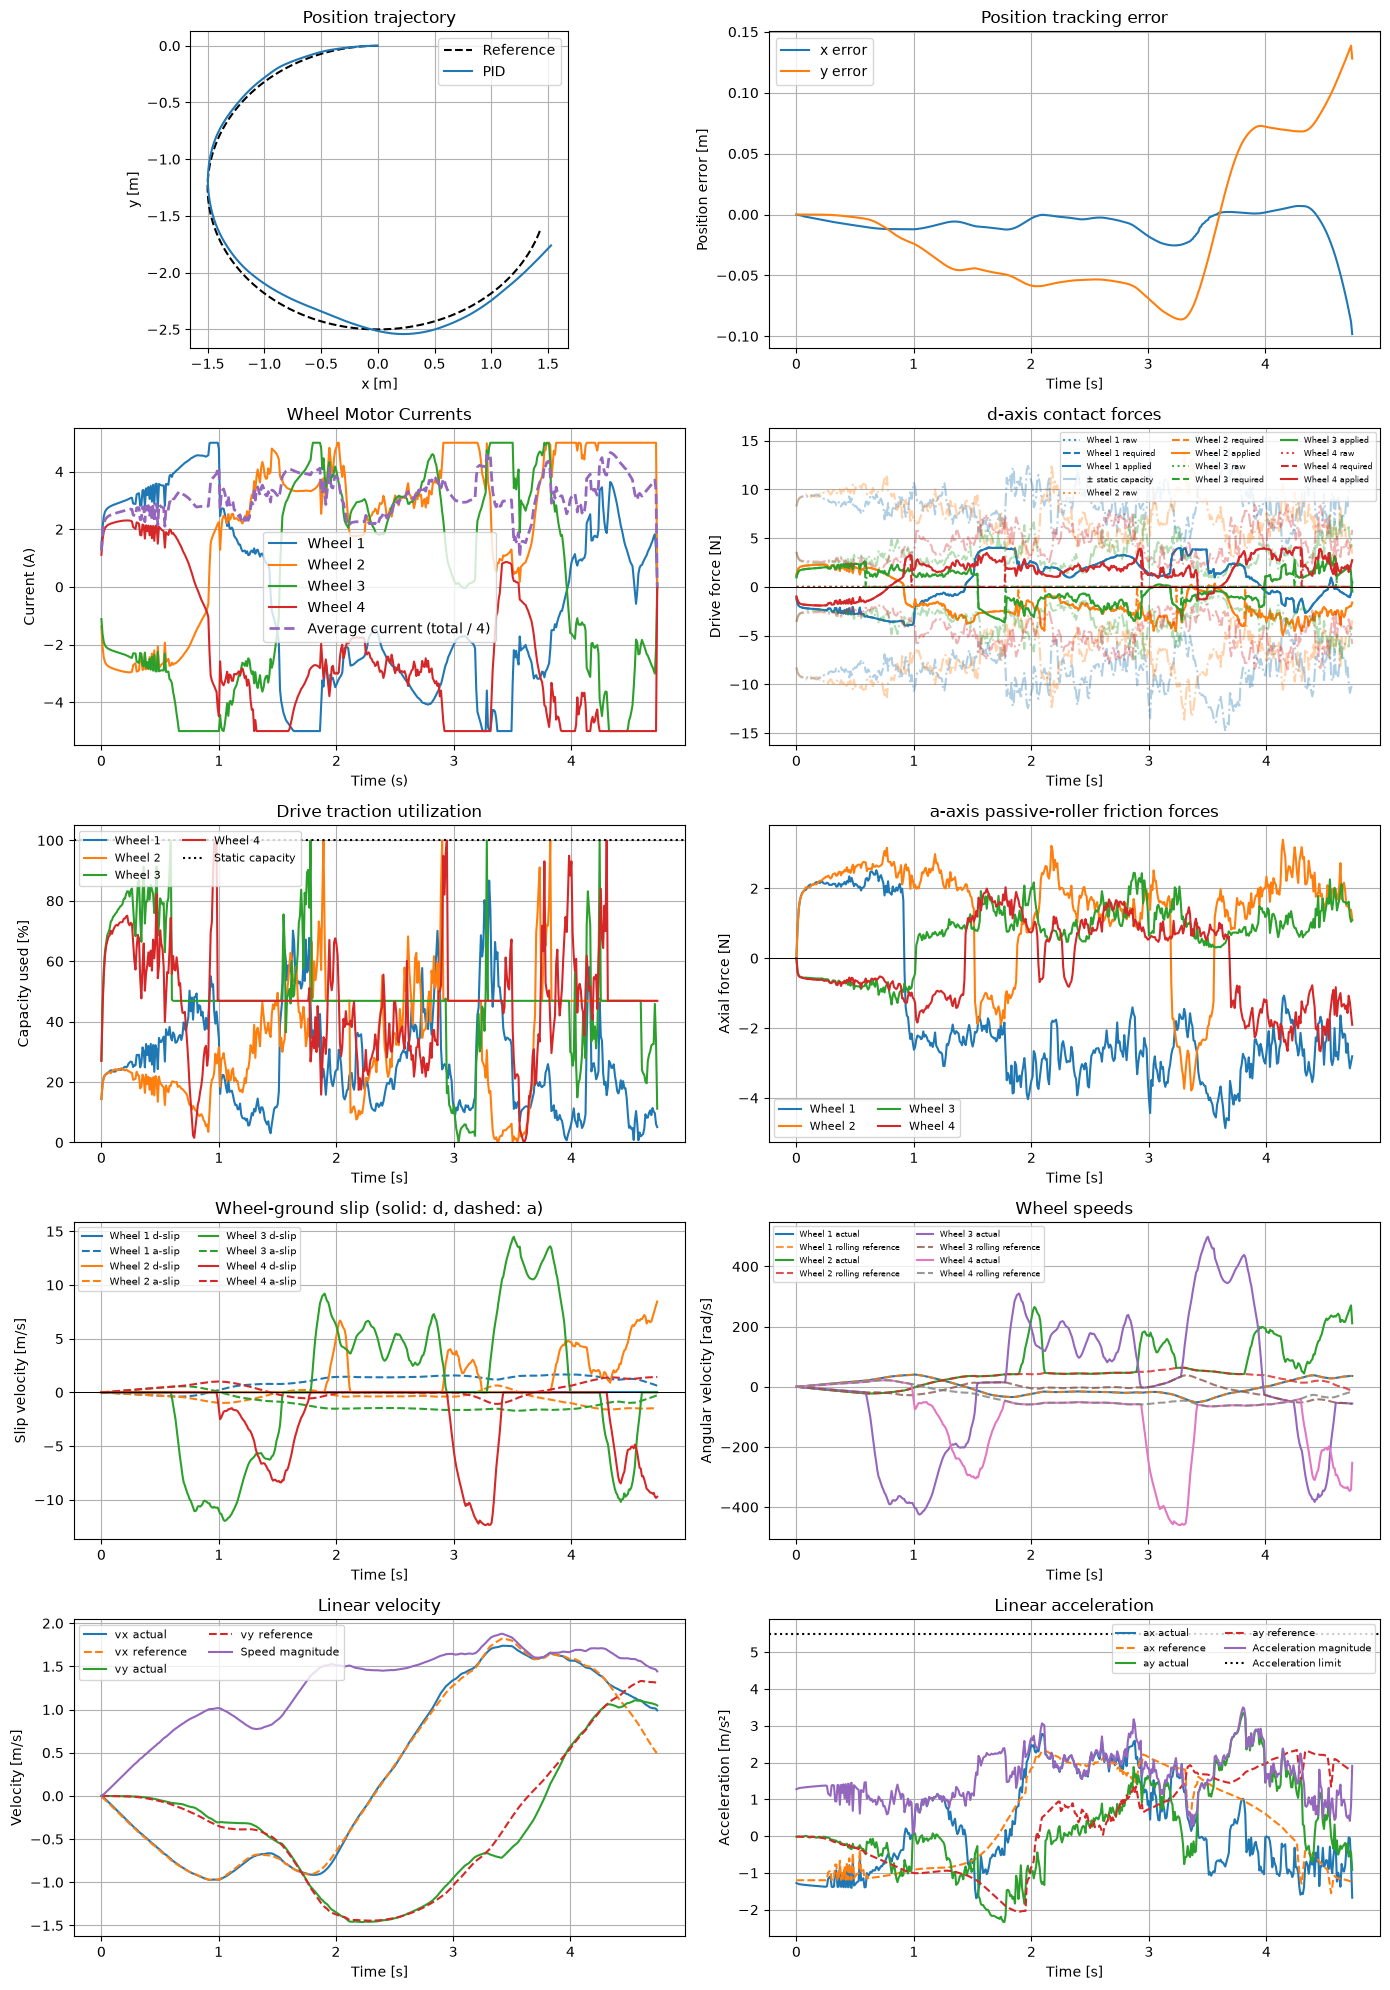

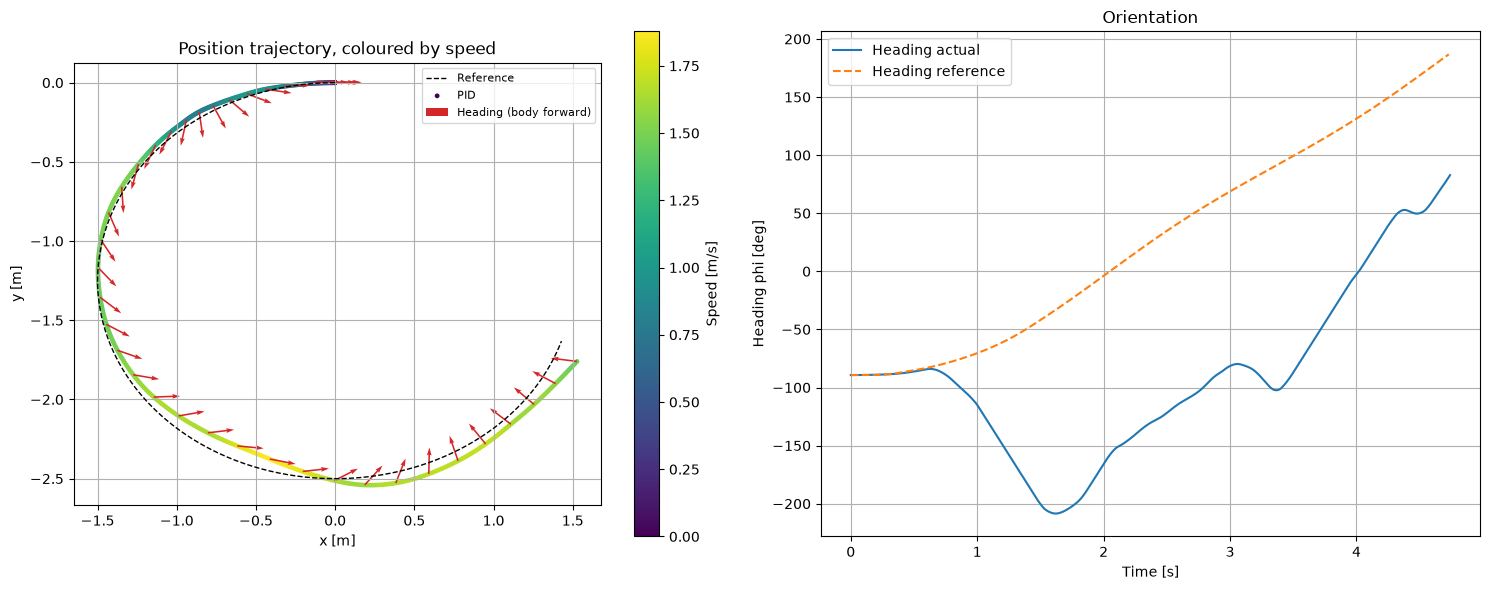

In [28]:
if not RUN_PLANT_CHECKS:
    def make_selected_controller():
        if CONTROLLER_MODE.upper() == "PID":
            return PositionPIDController()
        if CONTROLLER_MODE.upper() == "MPC":
            return ConvexMPCController(horizon=MPC_HORIZON)
        raise ValueError("CONTROLLER_MODE must be 'PID' or 'MPC'")


    preview_plant = make_plant()
    preview_controller = make_selected_controller()
    for _ in range(3):
        snapshot = preview_plant.step(preview_controller)
        print(
            f"{CONTROLLER_MODE.upper()} k={snapshot['step']} t={snapshot['time']:.2f}s "
            f"p={np.round(snapshot['state_after'][:2], 4)} "
            f"i={np.round(snapshot['current'], 4)} "
            f"min_margin={snapshot['minimum_constraint_margin']:.4f}"
        )
    if snapshot["linear_model"] is not None:
        print("Model shapes A/B/E:", snapshot["linear_model"]["A"].shape,
              snapshot["linear_model"]["B"].shape, snapshot["linear_model"]["E"].shape)
    else:
        print("PID uses direct nonlinear plant dynamics; skipped MPC linearization.")

    GOAL_HOLD_TIME = 1.0  # Require a full second at rest before declaring arrival.
    plant = make_plant()
    print(f"Plant: {type(plant).__name__}")
    run_controller = make_selected_controller()
    if CONTROLLER_MODE.upper() == "PID":
        # PID follows actual route progress, so end the run when the plant reaches
        # the endpoint and settles. A generous cap protects against endless runs;
        # it does not move the target or prescribe a transit schedule.
        MAX_SIMULATION_TIME = 3.0 * PATH_END_TIME + GOAL_HOLD_TIME
        MAX_STEPS = int(np.ceil(MAX_SIMULATION_TIME / DT))
        settled_steps = 0
        required_settled_steps = int(np.ceil(GOAL_HOLD_TIME / DT))
        trace = []
        progress_interval = max(1, MAX_STEPS // 10)
        for simulation_step in range(MAX_STEPS):
            sample = plant.step(run_controller)
            trace.append(sample)
            # Stop on the first violated constraint; later steps cannot repair this trial
            # and only delay the existing diagnostic raised below.
            if not sample["feasible"]:
                break
            if (simulation_step + 1) % progress_interval == 0:
                print(f"PID simulation progress: {simulation_step + 1}/{MAX_STEPS} steps "
                      f"({100.0 * (simulation_step + 1) / MAX_STEPS:.0f}%)")
            at_route_end = run_controller.path_arc_progress >= PATH_ARC[-1] - 0.02
            at_rest = np.linalg.norm(plant.state[3:5]) < 0.05
            settled_steps = settled_steps + 1 if at_route_end and at_rest else 0
            if settled_steps >= required_settled_steps:
                break
        route_complete = settled_steps >= required_settled_steps
    else:
        # MPC retains the original fixed-time demonstration while it is paused.
        SIMULATION_TIME = PATH_END_TIME + GOAL_HOLD_TIME
        trace = plant.run(run_controller, int(np.ceil(SIMULATION_TIME / DT)))
        route_complete = None
    N_STEPS = len(trace)
    SIMULATION_TIME = N_STEPS * DT
    TIME = DT * np.arange(N_STEPS + 1)
    state_history = np.vstack((plant.initial_state,
                               np.array([sample["state_after"] for sample in trace])))
    if CONTROLLER_MODE.upper() == "PID":
        # Plot the online path-following targets recorded by PID at each state.
        pid_position_targets = np.array([sample["decision"]["position_ref"] for sample in trace])
        pid_velocity_targets = np.array([sample["decision"]["velocity_ref"] for sample in trace])
        pid_acceleration_targets = np.array([sample["decision"]["acceleration_ref"] for sample in trace])
        position_reference_history = np.vstack((pid_position_targets, pid_position_targets[-1]))
        velocity_reference_history = np.vstack((pid_velocity_targets, pid_velocity_targets[-1]))
        acceleration_reference_history = pid_acceleration_targets
    else:
        # MPC retains its fixed, time-indexed trajectory reference.
        position_reference_history = np.array([trajectory_reference(t)[0] for t in TIME])
        velocity_reference_history = np.array([trajectory_reference(t)[1] for t in TIME])
        acceleration_reference_history = np.array([trajectory_reference(t)[2] for t in TIME[:-1]])
    position_error_history = position_reference_history - state_history[:, :2]
    velocity_history = state_history[:, 3:5]
    speed_history = np.linalg.norm(velocity_history, axis=1)

    acceleration_history = np.array([
        sample["state_derivative"][3:5] for sample in trace
    ])
    # PID uses the locally projected, rate-limited acceleration targets above.
    acceleration_magnitude_history = np.linalg.norm(acceleration_history, axis=1)
    current_history = np.array([sample["current"] for sample in trace])
    traction_history = np.array([sample["required_traction"] for sample in trace])
    normal_load_history = np.array([sample["normal_loads_N"] for sample in trace])
    traction_limit_history = np.array([sample["wheel_traction_limits_N"] for sample in trace])
    #slip_onset_history = np.array([sample["slip_onset"] for sample in trace])
    torque_residual_history = np.array([sample["wheel_torque_balance_residual"] for sample in trace])
    traction_utilization_history = 100.0 * np.abs(traction_history) / np.maximum(traction_limit_history, 1e-12)
    drive_slip_history = np.array([sample["drive_slip"] for sample in trace])
    drive_force_history = np.array([sample["force_d"] for sample in trace])
    axial_slip_history = np.array([sample["slip_a"] for sample in trace])
    axial_force_history = np.array([sample["force_a"] for sample in trace])
    wheel_speed_history = state_history[:, 6:10]
    wheel_speed_rolling_history = np.array([
        -(plant.H.T @ np.r_[world_to_body(state[3:5], state[2]), state[5]]) / rc.WHEEL_RADIUS
        for state in state_history
    ])
    wheel_speed_mismatch_history = wheel_speed_history - wheel_speed_rolling_history
    force_mode_history = np.array([sample["force_mode"] for sample in trace])
    rolling_mask_history = np.array([sample["rolling_mask"] for sample in trace])
    force_required_history = np.array([sample["force_required"] for sample in trace])
    raw_drive_force_history = np.array([sample["force_d"] for sample in trace])
    force_used_history = np.array([sample["force_used"] for sample in trace])

    # Recorded issue to revisit: the earlier MPC run hit the obstacle check at k=176 (1.760 s).
    # This PID run can also fail the plant safety assertion on collision; PID has no QP status.
    infeasible_samples = [sample for sample in trace if not sample["feasible"]]
    if infeasible_samples:
        first_bad = infeasible_samples[0]
        violated_constraints = {
            name: float(np.min(margin))
            for name, margin in first_bad["constraint_margins"].items()
            if np.min(margin) < -MPC_CONSTRAINT_TOL
        }
        print(
            f"WARNING: {len(infeasible_samples)} infeasible plant samples; first at "
            f"k={first_bad['step']} t={first_bad['time']:.3f}s, "
            f"current={np.max(np.abs(first_bad['current'])):.4f}/{rc.IQ_LIMIT:.4f} A, "
            f"margin={first_bad['minimum_constraint_margin']:.3e}, "
            f"yaw_rate={abs(first_bad['state_after'][5]):.4f}/{MAX_YAW_RATE:.4f} rad/s, "
            f"violated_constraints={violated_constraints}, "
            f"obstacle_collision={first_bad['collision']}, "
            f"obstacle_clearance_margin={first_bad['minimum_obstacle_clearance_margin']:.4f} m"
        )
        print("Displaying the recorded run up to the first infeasible sample.")
    force_balance_error = max(np.max(np.abs(sample["force_balance_residual"])) for sample in trace)
    wheel_torque_balance_error = max(np.max(np.abs(sample["wheel_torque_balance_residual"])) for sample in trace)
    if force_balance_error >= 1e-8:
        print(f"WARNING: force-balance residual exceeds tolerance: {force_balance_error:.2e}")
    if wheel_torque_balance_error >= 1e-10:
        print(f"WARNING: wheel torque-balance residual exceeds tolerance: {wheel_torque_balance_error:.2e}")
    if np.max(np.abs(current_history)) > rc.IQ_LIMIT + MPC_CONSTRAINT_TOL:
        print(f"WARNING: current limit exceeded: {np.max(np.abs(current_history)):.4f}/{rc.IQ_LIMIT:.4f} A")
    if not ALLOW_DRIVE_TRACTION_OVERLOAD and np.any(
        np.abs(traction_history) > traction_limit_history + MPC_CONSTRAINT_TOL
    ):
        print("WARNING: drive traction limit exceeded in the recorded run.")
    if CONTROLLER_MODE.upper() == "PID":
        achieved_progress = run_controller.path_arc_progress
        print(f"\nPID route progress: {achieved_progress:.2f}/{PATH_ARC[-1]:.2f} m; "
              f"settled at endpoint: {route_complete}; run time: {SIMULATION_TIME:.2f} s")
    else:
        print(f"\nMPC reference transit time: {PATH_END_TIME:.2f} s; "
              f"simulation including goal hold: {SIMULATION_TIME:.2f} s")
    print(f"{CONTROLLER_MODE.upper()} run: {N_STEPS} explicit plant steps")
    print(f"Position RMS error: {np.sqrt(np.mean(position_error_history**2)):.5f} m per axis")
    print(f"Maximum position error: {np.max(np.linalg.norm(position_error_history, axis=1)):.5f} m")
    print(f"Peak wheel current: {np.max(np.abs(current_history)):.3f} A / {rc.IQ_LIMIT:.3f} A")
    if "motor_voltage_applied" in trace[0]:
        voltage_history = np.array([sample["motor_voltage_applied"] for sample in trace])
        print(f"Peak motor voltage: {np.max(np.abs(voltage_history)):.3f} V / {rc.MAX_MOTOR_VOLTAGE:.3f} V")
    print(f"Samples where the plant limited the motor command: "
          f"{sum(sample['decision'].get('driver_limited', False) for sample in trace)}")
    print(f"Peak required drive traction: {np.max(np.abs(traction_history)):.3f} N; "
          f"static grip at rest MU_D_STAT*N_i: {np.round(rc.MU_D_STAT * plant.static_loads, 3)} N "
          f"('{plant.load_model}' loads)")
    friction_scale_history = np.array([sample["friction_scale"] for sample in trace])
    load_scale_history = np.array([sample["load_scale"] for sample in trace])
    print(f"Disturbances: friction offset {ENABLE_FRICTION_OFFSET}, load vibration {ENABLE_LOAD_VIBRATION}, "
          f"seed {DISTURBANCE_SEED}; friction scale range {friction_scale_history.min():.3f} to "
          f"{friction_scale_history.max():.3f}; load multiplier range {load_scale_history.min():.3f} to "
          f"{load_scale_history.max():.3f}")
    print(f"Wheel-load range: {np.min(normal_load_history):.3f} to "
          f"{np.max(normal_load_history):.3f} N")
    print(f"Peak traction utilization: {np.max(traction_utilization_history):.1f}%")
    #print(f"Drive-slip onset samples (threshold { _williams_model.slip_threshold:.4f} m/s): "
    #      f"{int(np.sum(np.any(slip_onset_history, axis=1)))}")
    print(f"Peak drive-direction slip: {np.max(np.abs(drive_slip_history)):.4f} m/s")
    print("Per-wheel contact-mode sample counts:",
          {mode: int(np.sum(force_mode_history == mode)) for mode in ("rolling", "sliding")})
    print(f"Peak passive-roller axial slip: {np.max(np.abs(axial_slip_history)):.4f} m/s")
    print(f"Peak passive-roller axial friction: {np.max(np.abs(axial_force_history)):.3f} N/wheel")
    print(f"Peak speed: {np.max(speed_history):.3f} m/s")
    print(f"Peak linear acceleration: {np.max(acceleration_magnitude_history):.3f} m/s^2")
    print(f"Peak wheel torque-balance residual: {np.max(np.abs(torque_residual_history)):.2e} N m")

    # Explicit IPython display keeps all plots inline in the notebook output.
    from IPython.display import HTML, display

    # The animated field view is the primary simulation visualization.
    # Animated top-down XY view. This silhouette is for display; collision checks
    # still use the separate ROBOT_CLEARANCE value in the simulator/MPC.
    from matplotlib.animation import FuncAnimation
    from matplotlib.patches import Polygon as PolygonPatch
    from matplotlib.transforms import Affine2D
    from IPython.display import HTML, display

    # Follow the COCO_T1 solution's interactive XY animation: fixed field axes,
    # an animated robot trace, a visible reference path, and play/scrub controls.
    # Keep this plot inline in the notebook, as in the COCO example.
    import plotly.graph_objects as go

    # The robot uses the project wheel/contact radius and the SSL-style clipped front.
    ROBOT_BODY_RADIUS = rc.WHEEL_ROBOT_DIST
    SSL_FRONT_CUT_FRACTION = 0.055 / 0.085
    ROBOT_FRONT_CUT_X = SSL_FRONT_CUT_FRACTION * ROBOT_BODY_RADIUS
    cut_angle = np.arccos(ROBOT_FRONT_CUT_X / ROBOT_BODY_RADIUS)
    arc_angles = np.linspace(cut_angle, 2.0 * np.pi - cut_angle, 100)
    robot_outline_local = np.vstack((
        np.column_stack((ROBOT_BODY_RADIUS * np.cos(arc_angles),
                         ROBOT_BODY_RADIUS * np.sin(arc_angles))),
        [ROBOT_FRONT_CUT_X, ROBOT_BODY_RADIUS * np.sin(cut_angle)],
    ))
    front_edge_local = np.array([
        [ROBOT_FRONT_CUT_X, -ROBOT_BODY_RADIUS * np.sin(cut_angle)],
        [ROBOT_FRONT_CUT_X,  ROBOT_BODY_RADIUS * np.sin(cut_angle)],
    ])

    # Downsample long runs for a responsive animation while retaining both endpoints.
    frame_indices = np.unique(np.linspace(
        0, len(TIME) - 1, min(240, len(TIME)), dtype=int
    ))

    def robot_world_geometry(sample_index):
        """Rotate and translate the robot outline using the simulated pose."""
        x, y, phi = state_history[sample_index, :3]
        rotation = np.array([[np.cos(phi), -np.sin(phi)],
                             [np.sin(phi),  np.cos(phi)]])
        outline = robot_outline_local @ rotation.T + np.array([x, y])
        front = front_edge_local @ rotation.T + np.array([x, y])
        nose = np.array([x, y]) + ROBOT_BODY_RADIUS * np.array([np.cos(phi), np.sin(phi)])
        return x, y, phi, outline, front, nose

    first_index = int(frame_indices[0])
    x0, y0, phi0, outline0, front0, nose0 = robot_world_geometry(first_index)
    static_traces = []
    for obstacle_index, obstacle_vertices in enumerate(STATIC_OBSTACLES):
        vertices = np.asarray(obstacle_vertices, dtype=float)
        closed = np.vstack((vertices, vertices[0]))
        static_traces.append(go.Scatter(
            x=closed[:, 0], y=closed[:, 1], mode="lines", fill="toself",
            fillcolor="rgba(120,120,120,0.48)",
            line=dict(color="#444444", width=1.5),
            name="static obstacle" if obstacle_index == 0 else None,
            showlegend=(obstacle_index == 0), hoverinfo="skip",
        ))

    obstacle_trace_count = len(static_traces)
    path_trace = go.Scatter(
        x=_route_points[:, 0], y=_route_points[:, 1],
        mode="lines", line=dict(color="gray", width=1.5, dash="dot"),
        name="route centerline",
    )
    trail_trace = go.Scatter(
        x=state_history[:first_index + 1, 0], y=state_history[:first_index + 1, 1],
        mode="lines", line=dict(color="#0072B2", width=2.5), name="robot path",
    )
    target_trace = go.Scatter(
        x=[position_reference_history[first_index, 0]],
        y=[position_reference_history[first_index, 1]],
        mode="markers", marker=dict(symbol="x", size=10, color="#D55E00"),
        name="current target",
    )
    robot_trace = go.Scatter(
        x=np.r_[outline0[:, 0], outline0[0, 0]],
        y=np.r_[outline0[:, 1], outline0[0, 1]],
        mode="lines", fill="toself", fillcolor="rgba(0,114,178,0.82)",
        line=dict(color="black", width=2), name="robot (to scale)",
    )
    front_trace = go.Scatter(
        x=front0[:, 0], y=front0[:, 1], mode="lines",
        line=dict(color="crimson", width=4), name="robot front / heading",
    )
    heading_trace = go.Scatter(
        x=[x0, nose0[0]], y=[y0, nose0[1]], mode="lines",
        line=dict(color="crimson", width=2), showlegend=False, hoverinfo="skip",
    )
    start_trace = go.Scatter(
        x=[ROUTE_WAYPOINTS[0, 0]], y=[ROUTE_WAYPOINTS[0, 1]],
        mode="markers", marker=dict(symbol="x", size=10, color="green"),
        name="start / stop",
    )
    traces = static_traces + [path_trace, trail_trace, target_trace,
                              robot_trace, front_trace, heading_trace, start_trace]
    path_i = obstacle_trace_count
    trail_i, target_i = path_i + 1, path_i + 2
    robot_i, front_i, heading_i, start_i = path_i + 3, path_i + 4, path_i + 5, path_i + 6

    frames = []
    slider_steps = []
    for frame_number, sample_index in enumerate(frame_indices):
        sample_index = int(sample_index)
        x, y, phi, outline, front, nose = robot_world_geometry(sample_index)
        frame_name = str(frame_number)
        speed = np.linalg.norm(state_history[sample_index, 3:5])
        frame_data = [
            go.Scatter(x=state_history[:sample_index + 1, 0],
                       y=state_history[:sample_index + 1, 1]),
            go.Scatter(x=[position_reference_history[sample_index, 0]],
                       y=[position_reference_history[sample_index, 1]]),
            go.Scatter(x=np.r_[outline[:, 0], outline[0, 0]],
                       y=np.r_[outline[:, 1], outline[0, 1]]),
            go.Scatter(x=front[:, 0], y=front[:, 1]),
            go.Scatter(x=[x, nose[0]], y=[y, nose[1]]),
        ]
        frame_layout = go.Layout(title=(
            f"4.5 m x 6 m field | t={TIME[sample_index]:.2f} s | "
            f"heading={np.degrees(phi):.1f} deg | speed={speed:.2f} m/s"
        ))
        frames.append(go.Frame(data=frame_data,
                               traces=[trail_i, target_i, robot_i, front_i, heading_i],
                               layout=frame_layout, name=frame_name))
        slider_steps.append(dict(
            label=f"{TIME[sample_index]:.2f}", method="animate",
            args=[[frame_name], dict(mode="immediate",
                                     frame=dict(duration=0, redraw=True),
                                     transition=dict(duration=0))],
        ))

    anim_fig = go.Figure(data=traces, frames=frames)
    anim_fig.update_layout(
        title=(f"4.5 m x 6 m field | t={TIME[first_index]:.2f} s | "
               f"heading={np.degrees(phi0):.1f} deg | "
               f"speed={np.linalg.norm(state_history[first_index, 3:5]):.2f} m/s"),
        width=900, height=760, template="plotly_white",
        xaxis=dict(title="x [m]", range=[-FIELD_LENGTH / 2, FIELD_LENGTH / 2],
                   showgrid=True, gridcolor="#d8e0dd", zeroline=False),
        yaxis=dict(title="y [m]", range=[-FIELD_WIDTH / 2, FIELD_WIDTH / 2],
                   scaleanchor="x", scaleratio=1, showgrid=True,
                   gridcolor="#d8e0dd", zeroline=False),
        plot_bgcolor="#f1f5f3", hovermode="closest",
        legend=dict(x=1.02, y=1.0),
        updatemenus=[dict(type="buttons", x=0.0, y=1.12, xanchor="left",
                          direction="right", buttons=[
            dict(label="▶ Play", method="animate",
                 args=[None, dict(frame=dict(duration=max(20, int(1000 * SIMULATION_TIME / max(1, len(frame_indices)))), redraw=True),
                                  fromcurrent=True, transition=dict(duration=0))]),
            dict(label="⏸ Pause", method="animate",
                 args=[[None], dict(frame=dict(duration=0, redraw=False), mode="immediate")]),
        ])],
        sliders=[dict(active=0, currentvalue=dict(prefix="time [s] = "),
                      steps=slider_steps)],
        margin=dict(l=70, r=190, t=105, b=80),
    )
    # COCO's XY view uses equal x/y scale. The field outline confirms the exact board size.
    anim_fig.add_shape(type="rect", x0=-FIELD_LENGTH / 2, y0=-FIELD_WIDTH / 2,
                       x1=FIELD_LENGTH / 2, y1=FIELD_WIDTH / 2,
                       line=dict(color="#333333", width=2), fillcolor="rgba(0,0,0,0)")
    anim_fig.add_shape(type="line", x0=0.0, y0=-FIELD_WIDTH / 2,
                       x1=0.0, y1=FIELD_WIDTH / 2,
                       line=dict(color="white", width=2))
    display(anim_fig)  # Notebook display keeps the interactive plot inline.

    # Keep exactly 10 scalar plots in the original 5 x 2 layout.
    figure, axes = plt.subplots(5, 2, figsize=(14, 20))

    # 1. Position trajectory
    axes[0, 0].plot(position_reference_history[:, 0], position_reference_history[:, 1],
                    "k--", label="Reference")
    axes[0, 0].plot(state_history[:, 0], state_history[:, 1],
                    label=CONTROLLER_MODE.upper())
    axes[0, 0].set(xlabel="x [m]", ylabel="y [m]",
                   title="Position trajectory")
    axes[0, 0].set_aspect("equal", adjustable="box")
    axes[0, 0].legend()
    axes[0, 0].grid(True)

    # 2. Position tracking error
    axes[0, 1].plot(TIME, position_error_history[:, 0], label="x error")
    axes[0, 1].plot(TIME, position_error_history[:, 1], label="y error")
    axes[0, 1].set(xlabel="Time [s]", ylabel="Position error [m]",
                   title="Position tracking error")
    axes[0, 1].legend()
    axes[0, 1].grid(True)

    # 3. Wheel current
    average_current_history = np.mean(np.abs(current_history), axis=1)

    for wheel in range(N_WHEELS):
        axes[1, 0].plot(TIME[:-1], current_history[:, wheel],
                        label=f"Wheel {wheel + 1}")

    axes[1, 0].plot(TIME[:-1], average_current_history,
                    "--", linewidth=2, label="Average current (total / 4)")

    axes[1, 0].set_title("Wheel Motor Currents")
    axes[1, 0].set_xlabel("Time (s)")
    axes[1, 0].set_ylabel("Current (A)")
    axes[1, 0].legend()
    axes[1, 0].grid(True)

    # 4. d-axis forces: all force types on the same axes.
    # Color identifies the wheel; line style identifies the force type.
    required_for_plot = np.where(
        force_mode_history == "rolling", force_required_history, 0.0
    )

    for wheel in range(N_WHEELS):
        color = f"C{wheel}"
        axes[1, 1].plot(TIME[:-1], raw_drive_force_history[:, wheel],
                        color=color, linestyle=":", alpha=0.85,
                        label=f"Wheel {wheel + 1} raw")
        axes[1, 1].plot(TIME[:-1], required_for_plot[:, wheel],
                        color=color, linestyle="--",
                        label=f"Wheel {wheel + 1} required")
        axes[1, 1].plot(TIME[:-1], force_used_history[:, wheel],
                        color=color, linestyle="-", linewidth=1.5,
                        label=f"Wheel {wheel + 1} applied")

        # Static traction capacity, shown without adding eight legend entries.
        axes[1, 1].plot(TIME[:-1], traction_limit_history[:, wheel],
                        color=color, linestyle="-.", alpha=0.35,
                        label="± static capacity" if wheel == 0 else "_nolegend_")
        axes[1, 1].plot(TIME[:-1], -traction_limit_history[:, wheel],
                        color=color, linestyle="-.", alpha=0.35,
                        label="_nolegend_")

    axes[1, 1].axhline(0.0, color="black", linewidth=0.7)
    axes[1, 1].set(xlabel="Time [s]", ylabel="Drive force [N]",
                   title="d-axis contact forces")
    axes[1, 1].legend(ncol=3, fontsize=6)
    axes[1, 1].grid(True)

    # 5. Drive traction utilization
    for wheel in range(N_WHEELS):
        axes[2, 0].plot(TIME[:-1], traction_utilization_history[:, wheel],
                        label=f"Wheel {wheel + 1}")
    axes[2, 0].axhline(100.0, color="black", linestyle=":", label="Static capacity")
    axes[2, 0].set(xlabel="Time [s]", ylabel="Capacity used [%]",
                   title="Drive traction utilization")
    axes[2, 0].set_ylim(bottom=0)
    axes[2, 0].legend(ncol=2, fontsize=8)
    axes[2, 0].grid(True)

    # 6. a-axis forces: force only, no slip on this plot.
    for wheel in range(N_WHEELS):
        axes[2, 1].plot(TIME[:-1], axial_force_history[:, wheel],
                        label=f"Wheel {wheel + 1}")
    axes[2, 1].axhline(0.0, color="black", linewidth=0.7)
    axes[2, 1].set(xlabel="Time [s]", ylabel="Axial force [N]",
                   title="a-axis passive-roller friction forces")
    axes[2, 1].legend(ncol=2, fontsize=8)
    axes[2, 1].grid(True)

    # 7. Slip only: solid = d-axis, dashed = a-axis.
    for wheel in range(N_WHEELS):
        color = f"C{wheel}"
        axes[3, 0].plot(TIME[:-1], drive_slip_history[:, wheel],
                        color=color, linestyle="-",
                        label=f"Wheel {wheel + 1} d-slip")
        axes[3, 0].plot(TIME[:-1], axial_slip_history[:, wheel],
                        color=color, linestyle="--",
                        label=f"Wheel {wheel + 1} a-slip")

    axes[3, 0].axhline(0.0, color="black", linewidth=0.7)
    axes[3, 0].set(xlabel="Time [s]", ylabel="Slip velocity [m/s]",
                   title="Wheel-ground slip (solid: d, dashed: a)")
    axes[3, 0].legend(ncol=2, fontsize=7)
    axes[3, 0].grid(True)

    # 8. Actual wheel speeds versus rolling-reference speeds
    for wheel in range(N_WHEELS):
        axes[3, 1].plot(TIME, wheel_speed_history[:, wheel],
                        label=f"Wheel {wheel + 1} actual")
        axes[3, 1].plot(TIME, wheel_speed_rolling_history[:, wheel],
                        linestyle="--", alpha=0.8,
                        label=f"Wheel {wheel + 1} rolling reference")
    axes[3, 1].set(xlabel="Time [s]", ylabel="Angular velocity [rad/s]",
                   title="Wheel speeds")
    axes[3, 1].legend(ncol=2, fontsize=6)
    axes[3, 1].grid(True)

    # 9. Linear velocity
    axes[4, 0].plot(TIME, velocity_history[:, 0], label="vx actual")
    axes[4, 0].plot(TIME, velocity_reference_history[:, 0], "--", label="vx reference")
    axes[4, 0].plot(TIME, velocity_history[:, 1], label="vy actual")
    axes[4, 0].plot(TIME, velocity_reference_history[:, 1], "--", label="vy reference")
    axes[4, 0].plot(TIME, speed_history, label="Speed magnitude")
    axes[4, 0].set(xlabel="Time [s]", ylabel="Velocity [m/s]",
                   title="Linear velocity")
    axes[4, 0].legend(ncol=2, fontsize=8)
    axes[4, 0].grid(True)

    # 10. Linear acceleration
    axes[4, 1].plot(TIME[:-1], acceleration_history[:, 0], label="ax actual")
    axes[4, 1].plot(TIME[:-1], acceleration_reference_history[:, 0],
                    "--", label="ax reference")
    axes[4, 1].plot(TIME[:-1], acceleration_history[:, 1], label="ay actual")
    axes[4, 1].plot(TIME[:-1], acceleration_reference_history[:, 1],
                    "--", label="ay reference")
    axes[4, 1].plot(TIME[:-1], acceleration_magnitude_history, label="Acceleration magnitude")
    axes[4, 1].axhline(MAX_ACCELERATION, color="black", linestyle=":",
                      label="Acceleration limit")
    axes[4, 1].set(xlabel="Time [s]", ylabel="Acceleration [m/s²]",
                   title="Linear acceleration")
    axes[4, 1].legend(ncol=2, fontsize=7)
    axes[4, 1].grid(True)

    figure.tight_layout()
    display(figure)
    plt.close(figure)

    # Trajectory coloured by speed, with heading arrows, and orientation versus time.
    heading_history = state_history[:, 2]
    heading_reference_history = np.array([sample["reference"]["heading"] for sample in trace])
    trajectory_figure, (path_ax, heading_ax) = plt.subplots(1, 2, figsize=(15, 6))
    path_ax.plot(position_reference_history[:, 0], position_reference_history[:, 1],
                 "k--", linewidth=1, label="Reference")
    speed_points = path_ax.scatter(state_history[:, 0], state_history[:, 1], c=speed_history,
                                   cmap="viridis", s=6, label=CONTROLLER_MODE.upper())
    trajectory_figure.colorbar(speed_points, ax=path_ax, label="Speed [m/s]")
    # Arrows show the robot's body +y (forward) direction at evenly spaced samples.
    arrow_indices = np.linspace(0, len(state_history) - 1, 40, dtype=int)
    path_ax.quiver(state_history[arrow_indices, 0], state_history[arrow_indices, 1],
                   -np.sin(heading_history[arrow_indices]), np.cos(heading_history[arrow_indices]),
                   angles="xy", scale_units="xy", scale=6.0, width=0.003, color="tab:red",
                   label="Heading (body forward)")
    path_ax.set(xlabel="x [m]", ylabel="y [m]", title="Position trajectory, coloured by speed")
    path_ax.set_aspect("equal", adjustable="box")
    path_ax.legend(loc="upper right", fontsize=8)
    path_ax.grid(True)
    heading_ax.plot(TIME, np.degrees(np.unwrap(heading_history)), label="Heading actual")
    heading_ax.plot(TIME[:-1], np.degrees(np.unwrap(heading_reference_history)), "--", label="Heading reference")
    heading_ax.set(xlabel="Time [s]", ylabel="Heading phi [deg]", title="Orientation")
    heading_ax.legend()
    heading_ax.grid(True)
    trajectory_figure.tight_layout()
    display(trajectory_figure)
    plt.close(trajectory_figure)
else:
    print("PID/MPC simulation skipped (RUN_PLANT_CHECKS = True).")

In [29]:
# Run a short MPC check against the same slip-capable plant when MPC is selected.
if CONTROLLER_MODE.upper() == "MPC":
    mpc_plant = WheelSlipRobotSimulator()
    mpc_controller = ConvexMPCController(horizon=2)
    mpc_snapshot = mpc_plant.step(mpc_controller)

    assert mpc_snapshot["decision"]["qp_status"] in ("optimal", "optimal_inaccurate")
    assert mpc_snapshot["decision"]["planned_states"].shape == (mpc_plant.state.size, 3)
    assert mpc_snapshot["decision"]["planned_currents"].shape == (N_WHEELS, 2)
    assert mpc_snapshot["feasible"]

    print("QP status:", mpc_snapshot["decision"]["qp_status"])
    print("Objective:", round(mpc_snapshot["decision"]["qp_objective"], 6))
    print("First current decision [A]:", np.round(mpc_snapshot["current"], 5))
    print("Predicted state/current shapes:",
          mpc_snapshot["decision"]["planned_states"].shape,
          mpc_snapshot["decision"]["planned_currents"].shape)
    print("Minimum plant constraint margin:", round(mpc_snapshot["minimum_constraint_margin"], 6))
else:
    print("Standalone MPC demo skipped because CONTROLLER_MODE is PID.")

Standalone MPC demo skipped because CONTROLLER_MODE is PID.


## 8. MPC objective and cost function

The tracking MPC uses a quadratic stage cost and a terminal cost. A suitable general form is

\[
J = \sum_{k=0}^{N-1}\left[
(\mathbf{x}_k-\mathbf{x}^{\mathrm{ref}}_k)^T Q
(\mathbf{x}_k-\mathbf{x}^{\mathrm{ref}}_k)
+ (\mathbf{u}_k-\mathbf{u}^{\mathrm{ref}}_k)^T R
(\mathbf{u}_k-\mathbf{u}^{\mathrm{ref}}_k)
+ \Delta\mathbf{u}_k^T S\Delta\mathbf{u}_k
\right]
+ (\mathbf{x}_N-\mathbf{x}^{\mathrm{ref}}_N)^T P
(\mathbf{x}_N-\mathbf{x}^{\mathrm{ref}}_N).
\]

Here, \(Q\) weights tracking error, \(R\) penalizes current/effort, \(S\) penalizes changes in input, and \(P\) weights terminal error. The exact implemented terms and weights are those in the MPC code cell above; do not assume every term in this general expression is currently enabled. Since the controller solves a convex QP around a local linearization, the objective is quadratic in the decision variables. The nonlinear slip-capable plant remains responsible for the actual simulated motion.

## 9. Minimum-time optimal-control problem

Minimum-time trajectory generation is a separate optimal-control problem from the notebook's current fixed-sample-time tracking MPC. A continuous-time formulation is

\[
\min_{T,\mathbf{x}(\cdot),\mathbf{u}(\cdot)} T
\]

subject to

\[
\dot{\mathbf{x}}(t)=f(\mathbf{x}(t),\mathbf{u}(t)),\quad
\mathbf{x}(0)=\mathbf{x}_0,\quad
\mathbf{x}(T)\in\mathcal{X}_{\mathrm{goal}},
\]

plus actuator/current limits, wheel-speed limits, collision-clearance constraints, and any chosen traction or safety constraints. The terminal set should specify the required final position and, where needed, zero translational velocity and a target heading.

A direct transcription would optimize the time horizon (or time-step durations) along with the state and input sequence. This is a proposed future formulation, not a claim that the present notebook solves minimum time. The current reference is time-indexed and the existing MPC tracks that reference at a fixed DT; minimizing tracking error does not itself minimize arrival time.

## 10. MPC formulation, constraints, and trajectory planning

At each control update, the MPC uses a local affine approximation of the plant to predict the state over a finite horizon. In compact form,

\[
\mathbf{x}_{k+1}=A_k\mathbf{x}_k+B_k\mathbf{u}_k+\mathbf{e}_k,
\]

with a quadratic tracking/effort objective and constraints expressed as linear inequalities where possible. The nonlinear simulator still evaluates the configured wheel-slip contact law when the selected control is applied.

The reference path is currently selected outside the QP. The notebook's obstacle-side logic selects a local safe half-space from the nominal route, then holds that choice fixed within the convex subproblem. This is a local corridor constraint: it does not let one QP freely choose either side of an obstacle. Route generation and discrete obstacle-side selection remain outer planning decisions.

The relevant constraint categories are current/actuator bounds, chassis velocity and acceleration limits, yaw-rate limits, and obstacle-clearance half-spaces. Friction/traction feasibility is handled through the notebook's configured feasibility logic and contact model; it should not be described as an exact complementarity constraint. Verify each constraint against the actual QP code before treating it as active, since the selected controller mode and optional settings determine which paths execute.

## 11. Development roadmap

1. **Restore and lock down plant kinematics.** Keep the wheel-centre rotational-velocity regression check and add tests for slip signs, force directions, and wheel torque balance.
2. **Establish a reproducible baseline.** Run the PID controller with fixed initial conditions and settings; record solver failures, runtime per simulated second, tracking error, wheel speeds, slip, contact forces, current commands, and obstacle clearance.
3. **Diagnose numerical stability.** Repeat the same case with tighter RK45 tolerances and a smaller maximum integration step; compare state and force histories and report solver failures rather than silently bypassing contact physics.
4. **Validate the MPC separately.** Select CONTROLLER_MODE = "MPC" and test QP feasibility, constraint residuals, solver status, and closed-loop behavior against the same reference and plant.
5. **Tune from measured evidence.** Adjust objective weights and limits only after distinguishing model errors, numerical integration error, controller infeasibility, and genuine traction limits.
6. **Consider minimum-time planning only after tracking is validated.** Add a time-optimization layer as a distinct feature; retain the fixed-time tracking MPC as a baseline for comparison.

## 12. Testing and validation plan

### Focused regression tests

- **Wheel-centre velocity:** the check above verifies translation plus \(\boldsymbol{\omega}\times\mathbf r_i\), and the zero-yaw limit.
- **Slip kinematics:** for zero chassis and wheel velocity, both d- and a-axis slip should be zero. Test pure translation, pure yaw, and individual wheel rotation with hand-computed expected signs.
- **Force law:** confirm force signs oppose the defined slip, forces remain bounded by the configured normal load and friction coefficients, and the static-to-dynamic transition is continuous for the configured smooth law.
- **Wheel torque balance:** verify \(J_w\ddot{\theta}_i=K_t I_{q,i}+R_w F_{d,i}\) using the notebook's sign convention.
- **Load redistribution:** when enabled, confirm all normal loads are nonnegative and their sum equals the robot's total weight.

### Closed-loop and numerical tests

- Run identical short scenarios twice and compare outputs for reproducibility.
- Compare RK45 results using tighter tolerances and smaller maximum steps; report state, slip, and force differences.
- Exercise PID and MPC separately. For MPC, record QP status, constraint violations, solve time, and fallback behavior.
- Check tracking RMSE, final position/velocity error, maximum wheel speed/current, minimum obstacle-clearance margin, and contact-force histories.
- Preserve failures and diagnostic traces. Do not disable model terms merely to make a test pass or improve runtime; isolate the failing subsystem and report the evidence.

These are validation requirements, not results: the checks and simulation runs must be executed in the target environment before the model can be called validated.